## Описание данных

В соревновании **ASHRAE – Great Energy Predictor III** необходимо предсказать энергопотребление зданий на основе исторических показаний счётчиков, характеристик зданий и погодных условий.

Данные содержат почасовые измерения энергопотребления для более чем 1000 зданий, расположенных на нескольких объектах (`site_id`) в разных регионах мира.

### `train.csv`

Основной обучающий датасет с показаниями счётчиков.

- `building_id` — идентификатор здания, связывающий таблицу с `building_metadata.csv`;
- `meter` — тип счётчика:
  - `0` — электричество;
  - `1` — охлаждённая вода;
  - `2` — пар;
  - `3` — горячая вода;
- `timestamp` — дата и время измерения;
- `meter_reading` — объём энергопотребления, **целевая переменная**.

Не для каждого здания доступны все четыре типа счётчиков.

---

### `test.csv`

Тестовая выборка, для которой необходимо получить прогноз `meter_reading`.

- `row_id` — уникальный идентификатор строки, используемый при формировании submission;
- `building_id` — идентификатор здания;
- `meter` — тип счётчика;
- `timestamp` — дата и время измерения.

В отличие от `train.csv`, столбец `meter_reading` отсутствует.

---

### `building_metadata.csv`

Содержит дополнительную информацию о зданиях.

- `site_id` — идентификатор площадки, связывающий здание с погодными данными;
- `building_id` — идентификатор здания;
- `primary_use` — основное назначение здания;
- `square_feet` — общая площадь здания в квадратных футах;
- `year_built` — год постройки здания;
- `floor_count` — количество этажей.

---

### `weather_train.csv` / `weather_test.csv`

Содержат погодные данные ближайших к соответствующим площадкам метеостанций.

- `site_id` — идентификатор площадки;
- `timestamp` — дата и время наблюдения;
- `air_temperature` — температура воздуха, °C;
- `cloud_coverage` — облачность;
- `dew_temperature` — температура точки росы, °C;
- `precip_depth_1_hr` — количество осадков за последний час, мм;
- `sea_level_pressure` — атмосферное давление на уровне моря;
- `wind_direction` — направление ветра в градусах от `0` до `360`;
- `wind_speed` — скорость ветра, м/с.

`weather_train.csv` соответствует временному периоду обучающей выборки, а `weather_test.csv` — тестовой.

---

### `sample_submission.csv`

Пример файла для отправки результатов на Kaggle.

Содержит:

- `row_id` — идентификатор строки из `test.csv`;
- `meter_reading` — прогнозируемое значение энергопотребления.

---

### Связи между таблицами

Основную обучающую таблицу можно представить как объединение:

```text
train.csv
    │
    ├── building_id ──> building_metadata.csv
    │                        │
    │                        └── site_id
    │                              │
    └── timestamp + site_id ───────┴──> weather_train.csv
```

Таким образом, итоговый датасет для обучения формируется объединением:

`train.csv` + `building_metadata.csv` + `weather_train.csv`

Для тестовой выборки аналогично:

`test.csv` + `building_metadata.csv` + `weather_test.csv`

**Целевая переменная:** `meter_reading`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [2]:
DATA_DIR = "ashrae-energy-prediction"

building_metadata = pd.read_csv(f"{DATA_DIR}/building_metadata.csv")
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

weather_train = pd.read_csv(f"{DATA_DIR}/weather_train.csv")
weather_test = pd.read_csv(f"{DATA_DIR}/weather_test.csv")

sample_submission = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

print("building_metadata:", building_metadata.shape)
print("train:", train.shape)
print("test:", test.shape)
print("weather_train:", weather_train.shape)
print("weather_test:", weather_test.shape)
print("sample_submission:", sample_submission.shape)

building_metadata: (1449, 6)
train: (20216100, 4)
test: (41697600, 4)
weather_train: (139773, 9)
weather_test: (277243, 9)
sample_submission: (41697600, 2)


In [3]:
print("===TRAIN===")
print(train.head(5))
print("===weather_train===")
print(weather_train.head(2))
print("===building_metadata===")
print(building_metadata.head(2))

===TRAIN===
   building_id  meter            timestamp  meter_reading
0            0      0  2016-01-01 00:00:00            0.0
1            1      0  2016-01-01 00:00:00            0.0
2            2      0  2016-01-01 00:00:00            0.0
3            3      0  2016-01-01 00:00:00            0.0
4            4      0  2016-01-01 00:00:00            0.0
===weather_train===
   site_id            timestamp  air_temperature  cloud_coverage  \
0        0  2016-01-01 00:00:00             25.0             6.0   
1        0  2016-01-01 01:00:00             24.4             NaN   

   dew_temperature  precip_depth_1_hr  sea_level_pressure  wind_direction  \
0             20.0                NaN              1019.7             0.0   
1             21.1               -1.0              1020.2            70.0   

   wind_speed  
0         0.0  
1         1.5  
===building_metadata===
   site_id  building_id primary_use  square_feet  year_built  floor_count
0        0            0   Education  

### Согласование времени погоды и счётчиков

[Isamu & Matt](https://www.kaggle.com/competitions/ashrae-energy-prediction/writeups/isamu-matt-1st-place-solution-team-isamu-matt) описали исправление рассогласования часовых поясов.
[Обсуждение](https://www.kaggle.com/c/ashrae-energy-prediction/discussion/114483) показывает смещение дневных температурных максимумов.

Ниже — эксперимент с фиксированным стандартным временем (без DST): поправки выведены из [таблицы зон участника](https://www.kaggle.com/code/juanmah/ashrae-data-wrangling-csv-to-pickle). Это не подтверждённая точная таблица Isamu & Matt. Качество нужно сравнить на той же временной валидации.
Сдвигаем только погоду: local = UTC + offset. Исходные weather_train/weather_test сохраняем, поэтому повторный запуск не накапливает сдвиг. На границах периода возможны новые пропуски; автоматически их не заполняем.


In [4]:
# Стандартные смещения UTC в часах; летнее время здесь не применяется.
WEATHER_UTC_OFFSETS = {
    0: -5, 1: 0, 2: -7, 3: -5,
    4: -8, 5: 0, 6: -5, 7: -5,
    8: -5, 9: -6, 10: -8, 11: -5,
    12: 0, 13: -6, 14: -5, 15: -5,
}


def align_weather_time(weather):
    aligned = weather.copy()
    offsets = aligned["site_id"].map(WEATHER_UTC_OFFSETS)
    if offsets.isna().any():
        raise ValueError("Для некоторых site_id не задано смещение")
    aligned["timestamp"] = (
        pd.to_datetime(aligned["timestamp"])
        + pd.to_timedelta(offsets, unit="h")
    )
    if aligned.duplicated(["site_id", "timestamp"]).any():
        raise ValueError("Неуникальные ключи погоды")
    return aligned


In [5]:
weather_train_aligned = align_weather_time(weather_train)
weather_test_aligned = align_weather_time(weather_test)
# Окна температуры по site_id. Считаем по train и test вместе: погода test
# продолжает train без разрыва, поэтому в январе 2017 окна не обрываются.
# Все окна захватывают только прошлое и текущий час.
WEATHER_WINDOWS = (3, 24, 72)
WEATHER_LAG_HOURS = 24


def add_temperature_windows(weather_train, weather_test):
    both = pd.concat(
        [weather_train.assign(_part=0), weather_test.assign(_part=1)],
        ignore_index=True,
    )
    both["_row"] = np.arange(len(both))
    both = both.sort_values(["site_id", "timestamp"], kind="stable")

    temperature = both.set_index("timestamp").groupby("site_id")[
        "air_temperature"
    ]

    for hours in WEATHER_WINDOWS:
        both[f"air_temperature_mean_{hours}h"] = (
            temperature.rolling(f"{hours}h", min_periods=1)
            .mean()
            .to_numpy(dtype=np.float32)
        )

    # Температура сутки назад: по метке времени, а не по номеру строки —
    # в погоде есть пропущенные часы.
    lagged = both[["site_id", "timestamp", "air_temperature"]].rename(
        columns={"air_temperature": f"air_temperature_lag_{WEATHER_LAG_HOURS}h"}
    )
    lagged["timestamp"] += pd.Timedelta(hours=WEATHER_LAG_HOURS)

    both = both.merge(
        lagged,
        on=["site_id", "timestamp"],
        how="left",
        validate="one_to_one",
    )
    both[f"air_temperature_lag_{WEATHER_LAG_HOURS}h"] = both[
        f"air_temperature_lag_{WEATHER_LAG_HOURS}h"
    ].astype(np.float32)

    # Отклонение от среднего за трое суток: потепление или похолодание.
    both["air_temperature_diff_72h"] = (
        both["air_temperature"] - both["air_temperature_mean_72h"]
    ).astype(np.float32)

    return tuple(
        both.loc[both["_part"] == part]
        .sort_values("_row")
        .drop(columns=["_part", "_row"])
        .reset_index(drop=True)
        for part in (0, 1)
    )


weather_train_aligned, weather_test_aligned = add_temperature_windows(
    weather_train_aligned, weather_test_aligned,
)

train["timestamp"] = pd.to_datetime(train["timestamp"])
test["timestamp"] = pd.to_datetime(test["timestamp"])

# В будущем при объединении test используй weather_test_aligned.
print("Погода train:", weather_train_aligned["timestamp"].agg(["min", "max"]))


Погода train: min   2015-12-31 17:00:00
max   2016-12-31 23:00:00
Name: timestamp, dtype: datetime64[ns]


In [6]:
# Диагностика: час максимума средней температуры до и после сдвига.
def temperature_peak_hour(weather):
    hours = pd.to_datetime(weather["timestamp"]).dt.hour
    profile = weather.groupby([weather["site_id"], hours])["air_temperature"].mean()
    return profile.unstack().idxmax(axis=1)

pd.DataFrame({
    "peak_before": temperature_peak_hour(weather_train),
    "offset_hours": pd.Series(WEATHER_UTC_OFFSETS),
    "peak_after": temperature_peak_hour(weather_train_aligned),
})


,peak_before,offset_hours,peak_after
0,19,-5,14
1,14,0,14
2,23,-7,16
3,20,-5,15
4,22,-8,14
5,14,0,14
6,20,-5,15
7,20,-5,15
8,19,-5,14
9,21,-6,15


In [7]:
train_full = train.merge(
    building_metadata,
    on="building_id",
    how="left",
    validate="many_to_one"
)

train_full = train_full.merge(
    weather_train_aligned,
    on=["site_id", "timestamp"],
    how="left",
    validate="many_to_one"
)

train_full.head()

,building_id,meter,timestamp,meter_reading,site_id,primary_use,square_feet,year_built,floor_count,air_temperature,...,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed,air_temperature_mean_3h,air_temperature_mean_24h,air_temperature_mean_72h,air_temperature_lag_24h,air_temperature_diff_72h
0,0,0,2016-01-01,0.0,0,Education,7432,2008.0,NaN,19.4,...,19.4,0.0,NaN,0.0,0.0,20.166666,22.116667,22.116667,NaN,-2.716667
1,1,0,2016-01-01,0.0,0,Education,2720,2004.0,NaN,19.4,...,19.4,0.0,NaN,0.0,0.0,20.166666,22.116667,22.116667,NaN,-2.716667
2,2,0,2016-01-01,0.0,0,Education,5376,1991.0,NaN,19.4,...,19.4,0.0,NaN,0.0,0.0,20.166666,22.116667,22.116667,NaN,-2.716667
3,3,0,2016-01-01,0.0,0,Education,23685,2002.0,NaN,19.4,...,19.4,0.0,NaN,0.0,0.0,20.166666,22.116667,22.116667,NaN,-2.716667
4,4,0,2016-01-01,0.0,0,Education,116607,1975.0,NaN,19.4,...,19.4,0.0,NaN,0.0,0.0,20.166666,22.116667,22.116667,NaN,-2.716667


In [8]:
train_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20216100 entries, 0 to 20216099
Data columns (total 21 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   building_id               int64         
 1   meter                     int64         
 2   timestamp                 datetime64[ns]
 3   meter_reading             float64       
 4   site_id                   int64         
 5   primary_use               object        
 6   square_feet               int64         
 7   year_built                float64       
 8   floor_count               float64       
 9   air_temperature           float64       
 10  cloud_coverage            float64       
 11  dew_temperature           float64       
 12  precip_depth_1_hr         float64       
 13  sea_level_pressure        float64       
 14  wind_direction            float64       
 15  wind_speed                float64       
 16  air_temperature_mean_3h   float32       
 17  air_te

In [9]:
round(train_full.describe(), 2)

,building_id,meter,timestamp,meter_reading,site_id,square_feet,year_built,floor_count,air_temperature,cloud_coverage,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed,air_temperature_mean_3h,air_temperature_mean_24h,air_temperature_mean_72h,air_temperature_lag_24h,air_temperature_diff_72h
count,20216100.00,20216100.00,20216100,20216100.00,20216100.00,20216100.00,8088455.00,3506933.00,20108387.00,11385815.0,20104905.00,16458651.00,18974835.00,18756320.00,20061358.00,20113425.00,20114555.00,20114555.00,19995459.00,20108387.00
mean,799.28,0.66,2016-07-03 22:59:40.301601792,2117.12,7.99,107782.98,1968.28,4.18,15.99,1.9,7.75,0.80,1016.08,172.99,3.38,15.99,15.99,15.99,16.03,0.00
min,0.00,0.00,2016-01-01 00:00:00,0.00,0.00,283.00,1900.00,1.00,-28.90,0.0,-35.00,-1.00,968.20,0.00,0.00,-28.60,-26.66,-22.24,-28.90,-16.72
25%,393.00,0.00,2016-04-05 21:00:00,18.30,3.00,32527.00,1951.00,1.00,8.60,0.0,0.00,0.00,1011.60,70.00,2.10,8.67,9.12,9.07,8.90,-3.05
50%,895.00,0.00,2016-07-04 17:00:00,78.78,9.00,72709.00,1969.00,3.00,16.70,0.0,8.90,0.00,1016.00,180.00,3.10,16.87,17.07,17.02,16.90,-0.27
75%,1179.00,1.00,2016-10-02 22:00:00,267.98,13.00,139113.00,1993.00,6.00,24.30,4.0,16.10,0.00,1020.50,280.00,4.60,24.10,23.80,23.67,24.40,2.97
max,1448.00,3.00,2016-12-31 23:00:00,21904700.00,15.00,875000.00,2017.00,26.00,47.20,9.0,26.10,343.00,1045.50,360.00,19.00,47.20,40.51,39.39,47.20,20.40
std,426.91,0.93,NaN,153235.62,5.10,117142.44,30.21,4.01,10.95,2.4,10.18,7.48,7.06,114.04,2.27,10.91,10.40,10.21,10.94,4.47


In [10]:
train_full.isna().sum()

building_id                        0
meter                              0
timestamp                          0
meter_reading                      0
site_id                            0
primary_use                        0
square_feet                        0
year_built                  12127645
floor_count                 16709167
air_temperature               107713
cloud_coverage               8830285
dew_temperature               111195
precip_depth_1_hr            3757449
sea_level_pressure           1241265
wind_direction               1459780
wind_speed                    154742
air_temperature_mean_3h       102675
air_temperature_mean_24h      101545
air_temperature_mean_72h      101545
air_temperature_lag_24h       220641
air_temperature_diff_72h      107713
dtype: int64

In [11]:
train_full["meter_reading"].quantile([
    0.5, 0.9, 0.95, 0.99, 0.999, 1.0
])

0.500    7.877500e+01
0.900    8.019970e+02
0.950    1.581360e+03
0.990    5.449220e+03
0.999    3.867190e+04
1.000    2.190470e+07
Name: meter_reading, dtype: float64

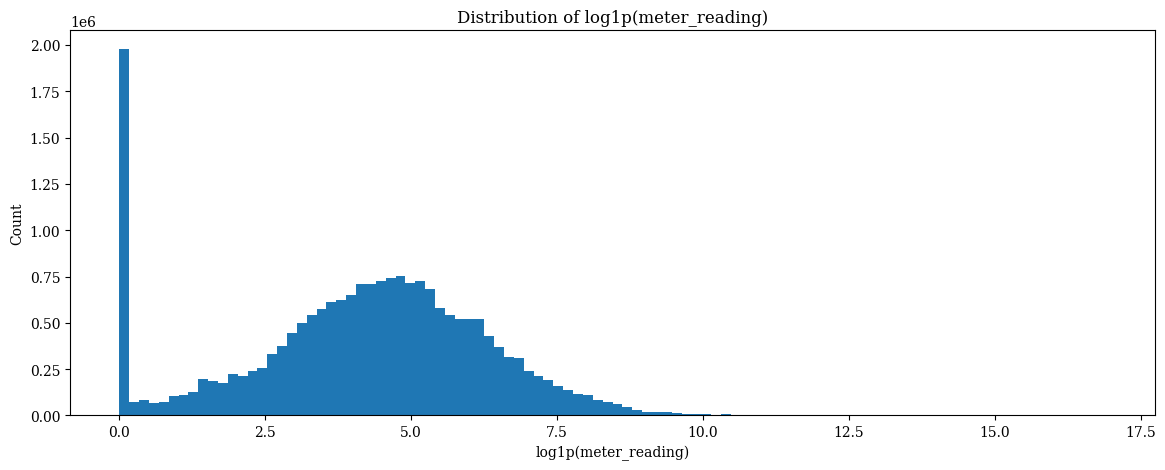

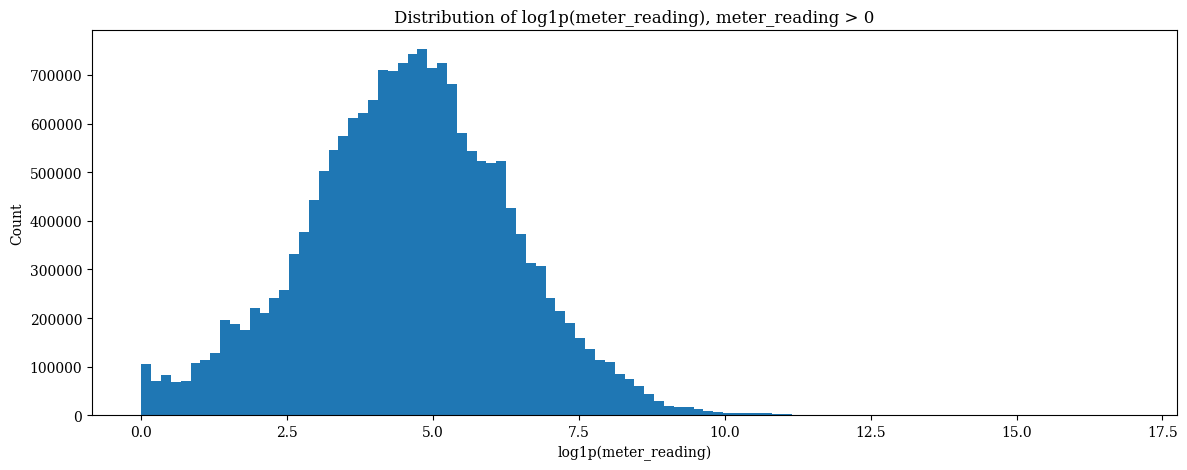

In [12]:
plt.figure(figsize=(14, 5))

plt.hist(
    np.log1p(train_full["meter_reading"]),
    bins=100
)

plt.xlabel("log1p(meter_reading)")
plt.ylabel("Count")
plt.title("Distribution of log1p(meter_reading)")
plt.show()


plt.figure(figsize=(14, 5))

plt.hist(
    np.log1p(train_full["meter_reading"][train_full["meter_reading"]>0]),
    bins=100
)


plt.xlabel("log1p(meter_reading)")
plt.ylabel("Count")
plt.title("Distribution of log1p(meter_reading), meter_reading > 0")
plt.show()

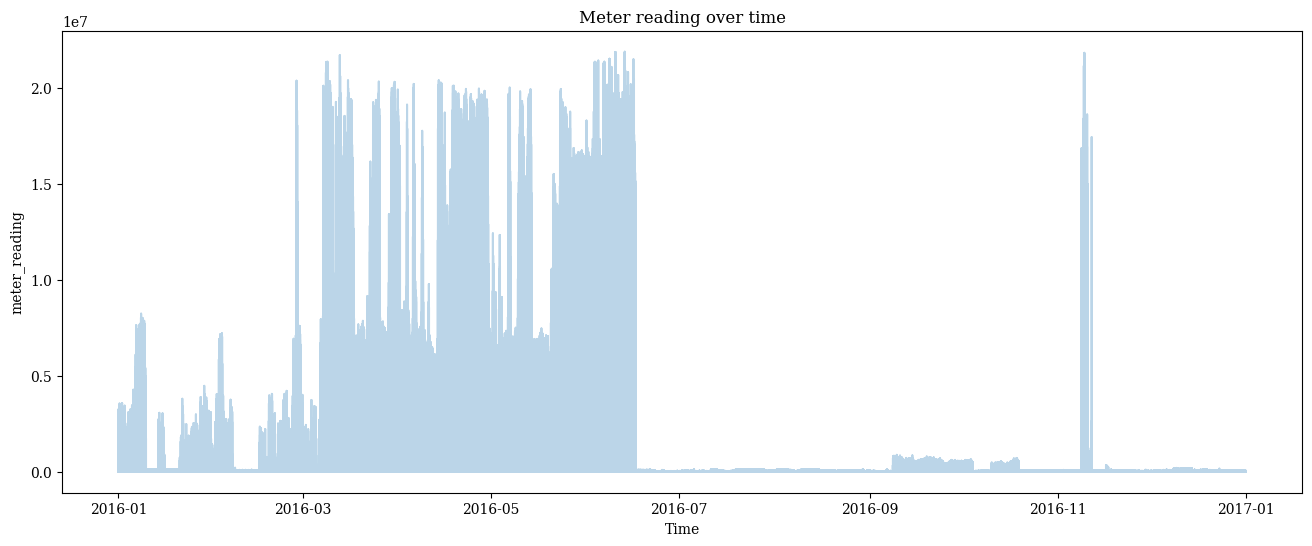

In [13]:
train_full["timestamp"] = pd.to_datetime(train_full["timestamp"])

plt.figure(figsize=(16, 6))

plt.plot(
    train_full["timestamp"],
    train_full["meter_reading"],
    alpha=0.3
)

plt.xlabel("Time")
plt.ylabel("meter_reading")
plt.title("Meter reading over time")
plt.show()


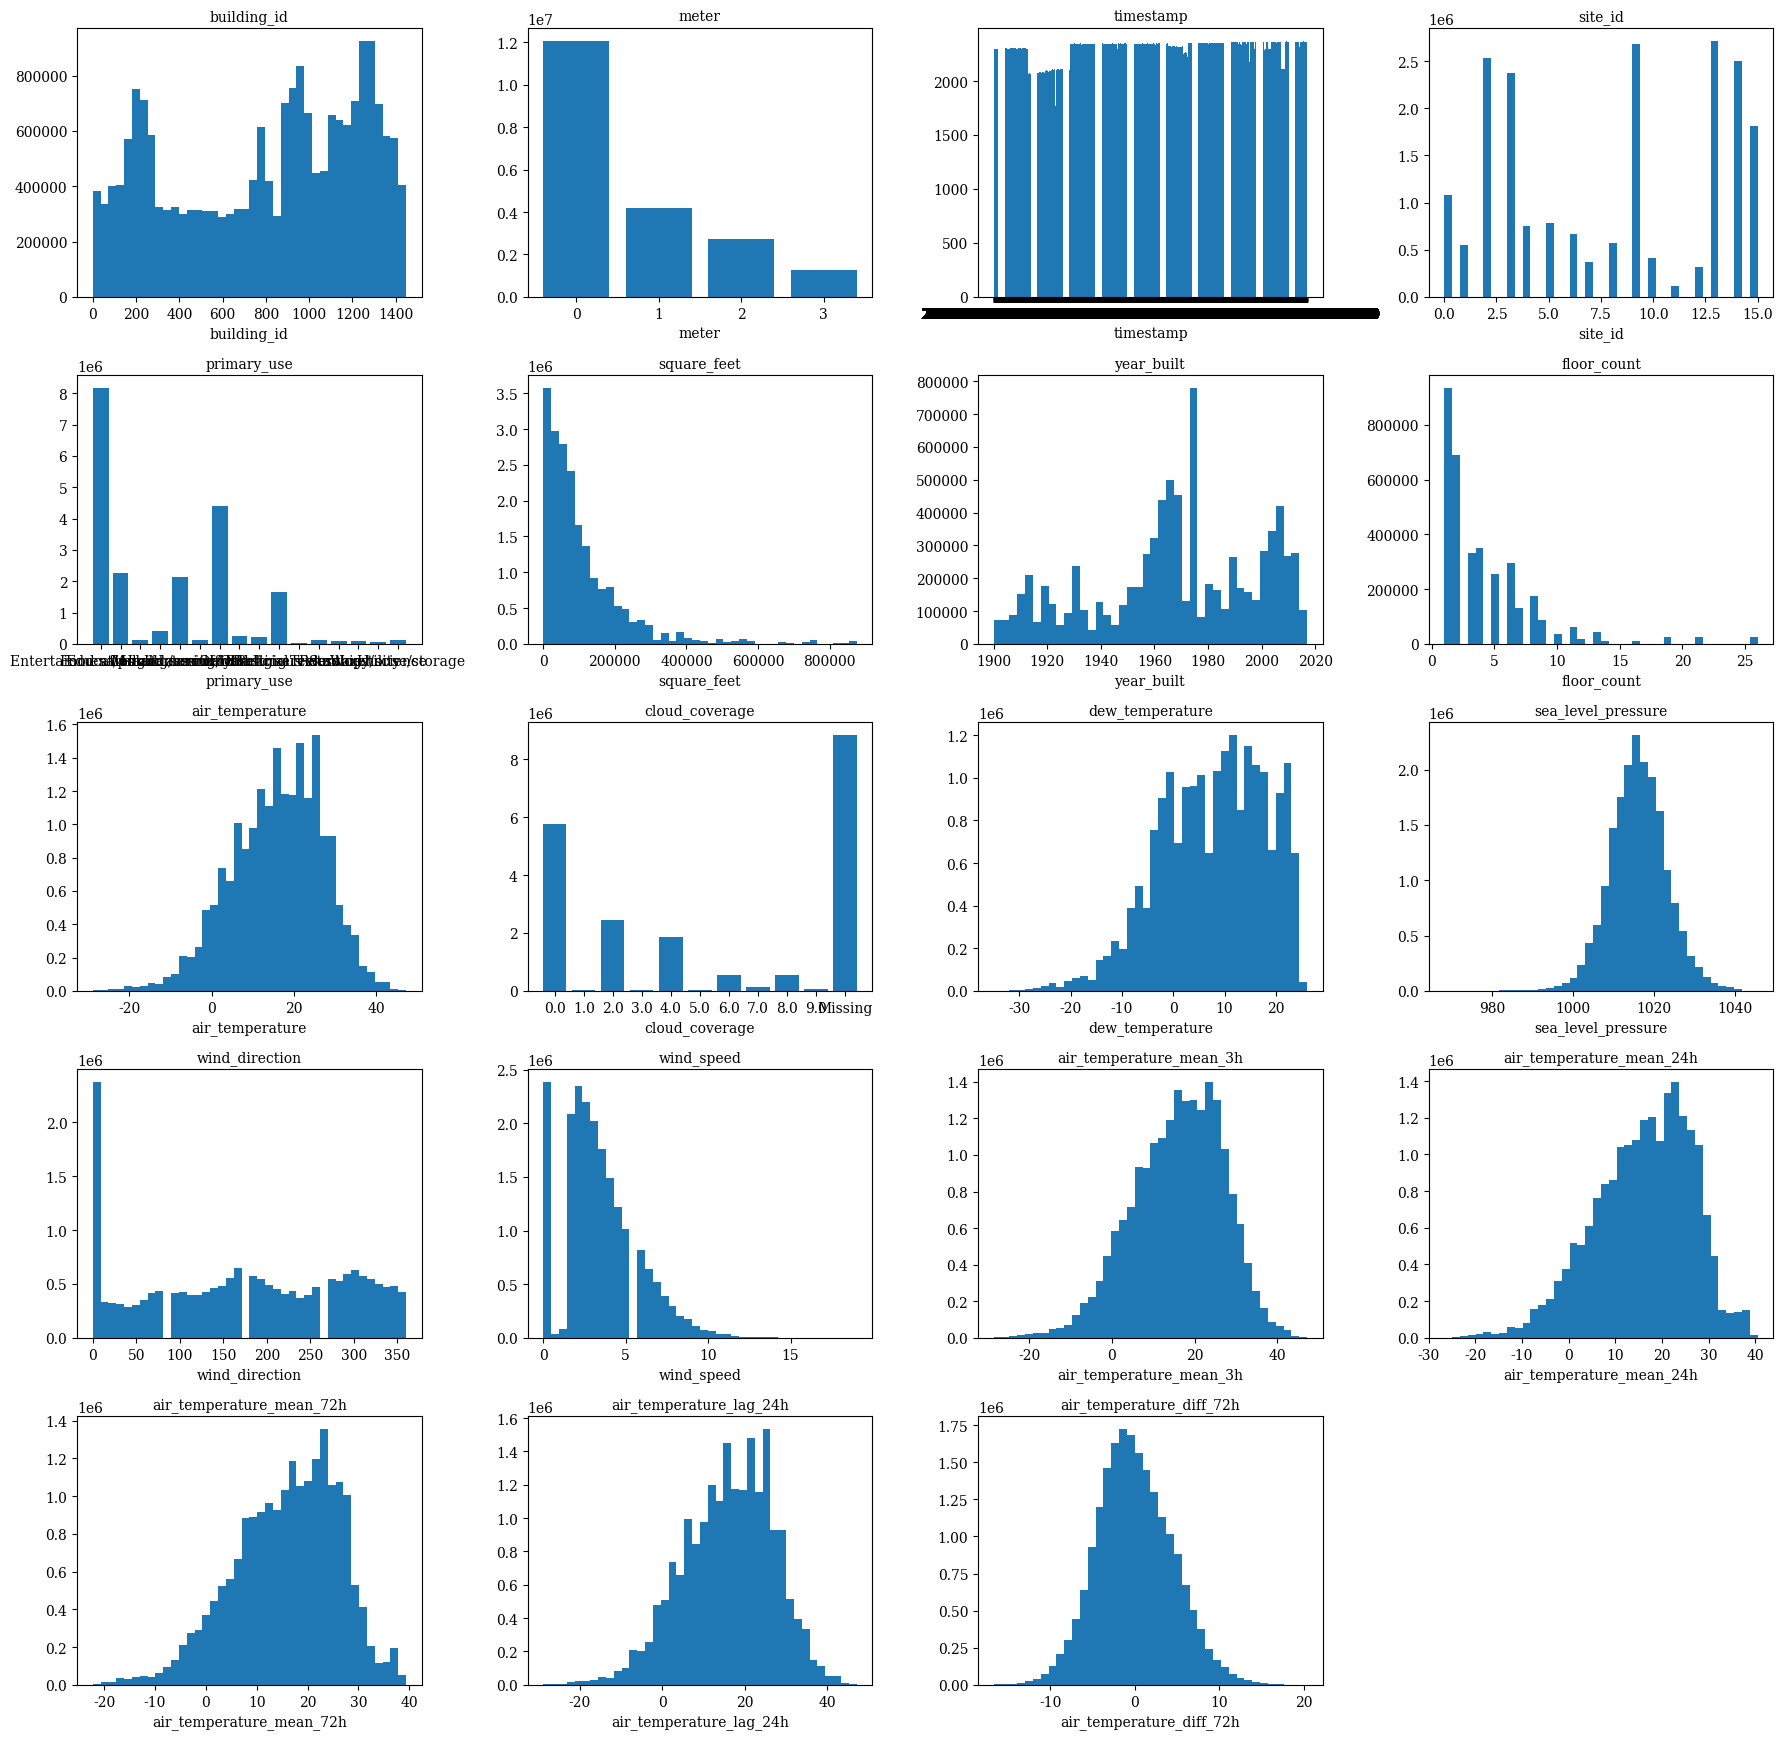

In [14]:
cols = train_full.drop(
    columns=["meter_reading", "precip_depth_1_hr"]
).columns.tolist()


n_plot_cols = 4
n_rows = (len(cols) + n_plot_cols - 1) // n_plot_cols

fig, axes = plt.subplots(
    n_rows,
    n_plot_cols,
    figsize=(18, n_rows * 3.5)
)

axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, cols):
    n_unique = train_full[col].nunique()

    
    if pd.api.types.is_numeric_dtype(train_full[col]) and n_unique > 10:
        ax.hist(train_full[col].dropna(), bins=40)
        ax.set_xlabel(col)
    else:
        counts = train_full[col].value_counts(dropna=False).sort_index()
        labels = [
            "Missing" if pd.isna(value) else str(value)
            for value in counts.index
        ]
        ax.bar(range(len(counts)), counts.to_numpy())
        ax.set_xticks(range(len(counts)), labels)
        ax.set_xlabel(col)

    ax.set_title(col, fontsize=10)

for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

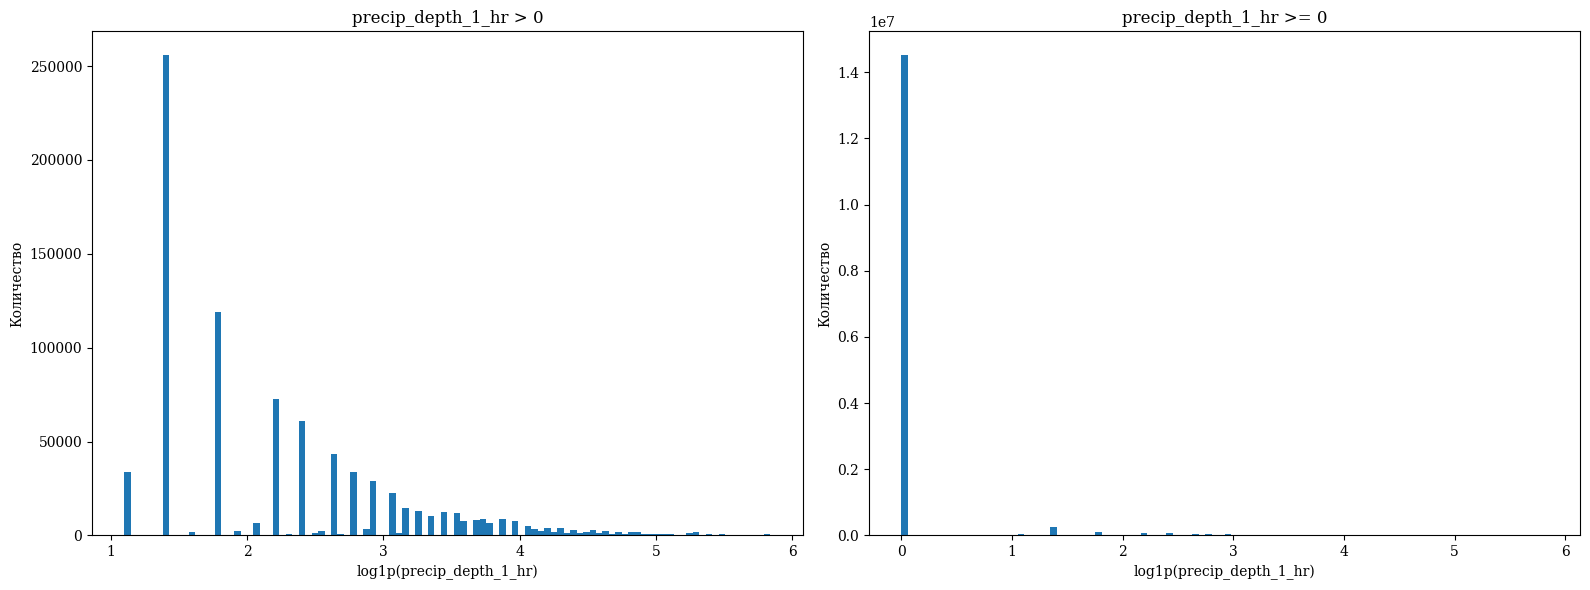

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Только положительные значения
val = train_full["precip_depth_1_hr"].dropna()
val = np.log1p(val[val > 0])

axes[0].hist(val, bins=100)
axes[0].set_xlabel("log1p(precip_depth_1_hr)")
axes[0].set_ylabel("Количество")
axes[0].set_title("precip_depth_1_hr > 0")


# Нули + положительные значения
val = train_full["precip_depth_1_hr"].dropna()
val = np.log1p(val[val >= 0])

axes[1].hist(val, bins=100)
axes[1].set_xlabel("log1p(precip_depth_1_hr)")
axes[1].set_ylabel("Количество")
axes[1].set_title("precip_depth_1_hr >= 0")

plt.tight_layout()
plt.show()

In [16]:
part = train_full
series_stats = (
    part.groupby(["building_id", "meter"])["meter_reading"]
    .agg(["size", "median", "max"])
)
zero_count = (
    part.loc[part["meter_reading"] == 0]
    .groupby(["building_id", "meter"]).size()
)
series_stats["zero_share"] = zero_count.div(series_stats["size"]).fillna(0)
del part
series_stats.sort_values("zero_share", ascending=False).head(20)

,,size,median,max,zero_share
building_id,meter,,,,
1018,1,8773,0.0,0.0334,0.999886
1022,1,8774,0.0,23.4080,0.999088
287,3,8783,0.0,73.2678,0.995104
279,3,8783,0.0,73.2678,0.994193
1250,2,8784,0.0,11687.5000,0.971767
1003,3,8306,0.0,70.2065,0.960029
1345,0,6951,0.0,17.9000,0.935980
53,0,1685,0.0,1713.0000,0.929970
163,3,8783,0.0,55.6835,0.928157


Сделаем подготовку для отбора признаков

In [17]:
CONSTANT_RUN_HOURS = 168
ZERO_RUN_METERS = (0,)


def constant_run_mask(frame, min_hours=CONSTANT_RUN_HOURS, zero_meters=ZERO_RUN_METERS):
    """True у строк, входящих в серию одинаковых показаний длиной от min_hours."""
    order = np.lexsort((
        frame["timestamp"].to_numpy(),
        frame["meter"].to_numpy(),
        frame["building_id"].to_numpy(),
    ))
    building = frame["building_id"].to_numpy()[order]
    meter = frame["meter"].to_numpy()[order]
    reading = frame["meter_reading"].to_numpy()[order]
    time = frame["timestamp"].to_numpy()[order]

    starts = np.ones(len(order), dtype=bool)
    starts[1:] = (
        (building[1:] != building[:-1])
        | (meter[1:] != meter[:-1])
        | (reading[1:] != reading[:-1])
        | (time[1:] - time[:-1] != np.timedelta64(1, "h"))
    )
    run_id = np.cumsum(starts) - 1
    long_run = np.bincount(run_id)[run_id] >= min_hours

    if zero_meters is not None:
        long_run &= (reading != 0) | np.isin(meter, zero_meters)

    mask = np.empty(len(order), dtype=bool)
    mask[order] = long_run
    return mask


train_full["constant_run"] = constant_run_mask(train_full)

print(
    "Строк в сериях:", int(train_full["constant_run"].sum()),
    f"({train_full['constant_run'].mean():.2%})",
)
display(
    train_full.assign(zero=train_full["meter_reading"] == 0)
    .groupby("meter")[["constant_run", "zero"]]
    .mean()
    .round(4)
)

Строк в сериях: 567473 (2.81%)


,constant_run,zero
meter,,
0,0.0440,0.0440
1,0.0040,0.1570
2,0.0019,0.1281
3,0.0116,0.2693


In [18]:
train_full.to_parquet("train_full.parquet", compression="zstd", index=False)

In [ ]:
# train_full = pd.read_parquet("train_full.parquet")

In [3]:
VALID_START = pd.Timestamp("2016-10-01")

train_part = train_full[
    train_full["timestamp"] < VALID_START
]

valid_part = train_full[
    train_full["timestamp"] >= VALID_START
]


y_train = np.log1p(train_part["meter_reading"])
y_valid = np.log1p(valid_part["meter_reading"])

### Эксперимент 1: исходные признаки

Подготовка X_train/X_valid и обучение SGD. Сохраняем модель, scaler и метрику отдельно для сравнения со вторым экспериментом.


In [4]:
X_train = (
    train_part
    .drop(columns=["meter_reading", "timestamp"])
    .select_dtypes(include="number")
    .fillna(0)
)

X_valid = (
    valid_part
    .drop(columns=["meter_reading", "timestamp"])
    .select_dtypes(include="number")
    .fillna(0)
)

In [5]:
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()
model = SGDRegressor(
    random_state=42,
    max_iter=10,
    tol=None
)

BATCH_SIZE = 10_000

In [6]:
for start in range(0, len(X_train), BATCH_SIZE):
    X_batch = X_train.iloc[start:start + BATCH_SIZE]
    scaler.partial_fit(X_batch)

for start in range(0, len(X_train), BATCH_SIZE):
    X_batch = X_train.iloc[start:start + BATCH_SIZE]
    y_batch = y_train.iloc[start:start + BATCH_SIZE]

    X_batch = scaler.transform(X_batch)

    model.partial_fit(X_batch, y_batch)

In [7]:
X_valid_scaled = scaler.transform(X_valid)

pred = model.predict(X_valid_scaled)

rmse = mean_squared_error(y_valid, pred) ** 0.5

print("RMSE:", rmse)

# Эти результаты не перезаписываются полиномиальными экспериментами ниже.
model_original = model
scaler_original = scaler
rmse_original = float(rmse)


RMSE: 1.9750440228730632


### Эксперимент 2: периодические и категориальные признаки

Числовые характеристики сохраняются; час и направление ветра кодируются через sin/cos, а meter, site_id, primary_use и building_id — через One-Hot. Исходные X_train/X_valid не меняются. Используем то же временное разделение, размер батча и настройки SGD, что в первом эксперименте. Encoder и scaler обучаются только на train.


In [8]:
from scipy import sparse
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import SGDRegressor

categorical_columns = ["meter", "site_id", "primary_use", "building_id"]
cyclic_columns = ["hour_sin", "hour_cos", "wind_direction_sin", "wind_direction_cos"]
numeric_columns_cyclic = [
    col for col in train_part.select_dtypes(include="number").columns
    if col not in categorical_columns + cyclic_columns + ["meter_reading", "wind_direction"]
]
BATCH_SIZE_CYCLIC = BATCH_SIZE


def cyclic_numeric_batch(frame):
    result = frame[numeric_columns_cyclic].astype(np.float32).fillna(0)
    angle = frame["timestamp"].dt.hour.to_numpy(dtype=np.float32)
    angle *= np.float32(2 * np.pi / 24)
    result["hour_sin"], result["hour_cos"] = np.sin(angle), np.cos(angle)
    if "wind_direction" in frame:
        angle = frame["wind_direction"].to_numpy(dtype=np.float32, copy=True)
        np.deg2rad(angle, out=angle)
        result["wind_direction_sin"] = np.sin(angle)
        result["wind_direction_cos"] = np.cos(angle)
    else:
        result[["wind_direction_sin", "wind_direction_cos"]] = frame[
            ["wind_direction_sin", "wind_direction_cos"]
        ]
    return result.fillna(0).to_numpy(dtype=np.float32)


In [9]:
# Категории определяем только по train
encoder_cyclic = OneHotEncoder(
    categories=[np.sort(train_part[col].unique()) for col in categorical_columns],
    handle_unknown="ignore", sparse_output=True, dtype=np.float32,
)
encoder_cyclic.fit(train_part.iloc[:1][categorical_columns])
scaler_cyclic = StandardScaler()
for start in range(0, len(train_part), BATCH_SIZE_CYCLIC):
    batch = train_part.iloc[start:start + BATCH_SIZE_CYCLIC]
    scaler_cyclic.partial_fit(cyclic_numeric_batch(batch))


def prepare_cyclic_batch(frame):
    numeric = scaler_cyclic.transform(cyclic_numeric_batch(frame))
    categorical = encoder_cyclic.transform(frame[categorical_columns])
    return sparse.hstack([sparse.csr_matrix(numeric), categorical], format="csr")


In [10]:
# Отдельная модель: масштабированные числовые + циклические + One-Hot.
# Те же параметры SGD: сравниваем влияние признаков.
model_cyclic = SGDRegressor(**model_original.get_params())
for start in range(0, len(train_part), BATCH_SIZE_CYCLIC):
    stop = start + BATCH_SIZE_CYCLIC
    batch = prepare_cyclic_batch(train_part.iloc[start:stop])
    model_cyclic.partial_fit(batch, y_train.iloc[start:stop])

squared_error_cyclic = 0.0
for start in range(0, len(valid_part), BATCH_SIZE_CYCLIC):
    stop = start + BATCH_SIZE_CYCLIC
    batch = prepare_cyclic_batch(valid_part.iloc[start:stop])
    predictions = model_cyclic.predict(batch)
    squared_error_cyclic += np.sum((y_valid.iloc[start:stop].to_numpy() - predictions) ** 2)

rmse_cyclic = np.sqrt(squared_error_cyclic / len(valid_part))
print(f"RMSE(log1p), циклические и категориальные: {rmse_cyclic:.6f}")


RMSE(log1p), циклические и категориальные: 1.688844


In [11]:
comparison = pd.DataFrame({
    "Эксперимент": ["Исходные признаки", "Периодические + категориальные"],
    "RMSE(log1p)": [rmse_original, rmse_cyclic],
})
comparison


,Эксперимент,RMSE(log1p)
0,Исходные признаки,1.975044
1,Периодические + категориальные,1.688844


Добавим новые комбинации признаков

Строим полиномы степени 3 по масштабированным числовым признакам второго эксперимента. Отбираем k комбинаций на части train, затем масштабируем их по всему train. Все циклические признаки и One-Hot категории добавляем отдельно; степени к ним не применяем. Encoder и исходный scaler используем из второго эксперимента, без повторного обучения.

k — количество выбранных числовых полиномиальных признаков. На батчах вычисляем только выбранные комбинации. Модели первых двух экспериментов сохраняются. Для всех k используем одинаковую выборку отбора, один проход обучения и одинаковые настройки SGD с небольшим шагом.


In [12]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression

n_numeric_poly = len(numeric_columns_cyclic)
poly_numeric = PolynomialFeatures(degree=3, include_bias=False)
sample_poly_frame = train_part.sample(n=min(50_000, len(train_part)), random_state=42)
sample_numeric = scaler_cyclic.transform(cyclic_numeric_batch(sample_poly_frame))
sample_poly = poly_numeric.fit_transform(sample_numeric[:, :n_numeric_poly])

K_POLY = 15
selector_poly = SelectKBest(f_regression, k=K_POLY)
selector_poly.fit(sample_poly, y_train.loc[sample_poly_frame.index])
rank_poly = np.argsort(selector_poly.scores_, kind="stable")[::-1]
names_poly = poly_numeric.get_feature_names_out(numeric_columns_cyclic)
print(names_poly[selector_poly.get_support()])
del sample_poly_frame, sample_numeric, sample_poly


['square_feet' 'square_feet year_built^2' 'square_feet air_temperature^2'
 'square_feet air_temperature air_temperature_mean_3h'
 'square_feet air_temperature air_temperature_lag_24h'
 'square_feet dew_temperature^2' 'square_feet wind_speed^2'
 'square_feet air_temperature_mean_3h^2'
 'square_feet air_temperature_mean_3h air_temperature_mean_72h'
 'square_feet air_temperature_mean_3h air_temperature_lag_24h'
 'square_feet air_temperature_mean_24h air_temperature_mean_72h'
 'square_feet air_temperature_mean_72h^2'
 'square_feet air_temperature_mean_72h air_temperature_lag_24h'
 'square_feet air_temperature_lag_24h^2'
 'square_feet air_temperature_diff_72h^2']


In [13]:
def polynomial_numeric_batch(frame, powers):
    scaled = scaler_cyclic.transform(cyclic_numeric_batch(frame))
    numeric = scaled[:, :n_numeric_poly]
    combinations = np.ones((len(frame), len(powers)), dtype=np.float32)
    for j, term in enumerate(powers):
        for col in np.flatnonzero(term):
            # Повторные умножения совпадают с определением PolynomialFeatures.
            for _ in range(int(term[col])):
                combinations[:, j] *= numeric[:, col]
    return combinations, scaled[:, n_numeric_poly:]


def prepare_polynomial_batch(frame, powers, polynomial_scaler):
    combinations, cyclic = polynomial_numeric_batch(frame, powers)
    categorical = encoder_cyclic.transform(frame[categorical_columns])
    return sparse.hstack([
        sparse.csr_matrix(polynomial_scaler.transform(combinations)),
        sparse.csr_matrix(cyclic), categorical,
    ], format="csr")


In [14]:
def polynomial_rmse(model, polynomial_scaler, powers, batch_size):
    squared_error = 0.0
    for start in range(0, len(valid_part), batch_size):
        stop = start + batch_size
        batch = prepare_polynomial_batch(valid_part.iloc[start:stop], powers, polynomial_scaler)
        pred = model.predict(batch)
        if not np.isfinite(pred).all():
            raise ValueError("Прогнозы не конечны: уменьшите eta0 в POLY_SGD_PARAMS")
        squared_error += np.sum((y_valid.iloc[start:stop].to_numpy() - pred) ** 2)
    return float(np.sqrt(squared_error / len(valid_part)))


In [15]:
def fit_polynomial_model(k, batch_size=BATCH_SIZE_CYCLIC):
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= poly_numeric.n_output_features_:
        raise ValueError(f"k должен быть целым от 1 до {poly_numeric.n_output_features_}")
    if batch_size < 1:
        raise ValueError("batch_size должен быть положительным")
    columns = np.sort(rank_poly[:k])
    powers = poly_numeric.powers_[columns]
    polynomial_scaler = StandardScaler()
    params = model_cyclic.get_params()
    params.update(
        learning_rate="invscaling",
        eta0=1e-2,
        
    )
    model = SGDRegressor(**params)

    for start in range(0, len(train_part), batch_size):
        batch = train_part.iloc[start:start + batch_size]
        combinations, _ = polynomial_numeric_batch(batch, powers)
        polynomial_scaler.partial_fit(combinations)

    for start in range(0, len(train_part), batch_size):
        stop = start + batch_size
        batch = prepare_polynomial_batch(train_part.iloc[start:stop], powers, polynomial_scaler)
        model.partial_fit(batch, y_train.iloc[start:stop])

    score = polynomial_rmse(model, polynomial_scaler, powers, batch_size)
    return model, polynomial_scaler, powers, score


In [16]:
# Отдельная модель с 15 числовыми комбинациями + циклическими + One-Hot.
model_poly, scaler_poly, powers_poly, rmse_poly = fit_polynomial_model(K_POLY)
print(f"k={K_POLY}: RMSE(log1p)={rmse_poly:.6f}")

pd.DataFrame({
    "Эксперимент": ["Исходные", "Циклические + One-Hot", f"Полиномы k={K_POLY} + циклические + One-Hot"],
    "RMSE(log1p)": [rmse_original, rmse_cyclic, rmse_poly],
})


k=15: RMSE(log1p)=1.683388


,Эксперимент,RMSE(log1p)
0,Исходные,1.975044
1,Циклические + One-Hot,1.688844
2,Полиномы k=15 + циклические + One-Hot,1.683388


### RMSE в зависимости от k

Используем уже рассчитанный отбор. Для каждого k заново обучаем scaler полиномиальных признаков и SGD; циклические и One-Hot признаки во всех моделях одинаковы. Каждый новый k требует проходов по полному train и valid.


In [34]:
def evaluate_k(k, batch_size=BATCH_SIZE_CYCLIC):
    _, _, _, score = fit_polynomial_model(k, batch_size)
    return score


k_values = np.arange(1, 14, 2)
rows_k = []
for k in k_values:
    score = evaluate_k(k)
    rows_k.append({"k": k, "rmse_log": score})
    print(f"k={k}: RMSE(log1p)={score:.6f}", flush=True)
results_k = pd.DataFrame(rows_k).sort_values("k")
results_k


k=1: RMSE(log1p)=1.673053
k=3: RMSE(log1p)=1.673080
k=5: RMSE(log1p)=1.673373
k=7: RMSE(log1p)=1.687064
k=9: RMSE(log1p)=1.687464
k=11: RMSE(log1p)=1.685742
k=13: RMSE(log1p)=1.684373


,k,rmse_log
0,1,1.673053
1,3,1.673080
2,5,1.673373
3,7,1.687064
4,9,1.687464
5,11,1.685742
6,13,1.684373


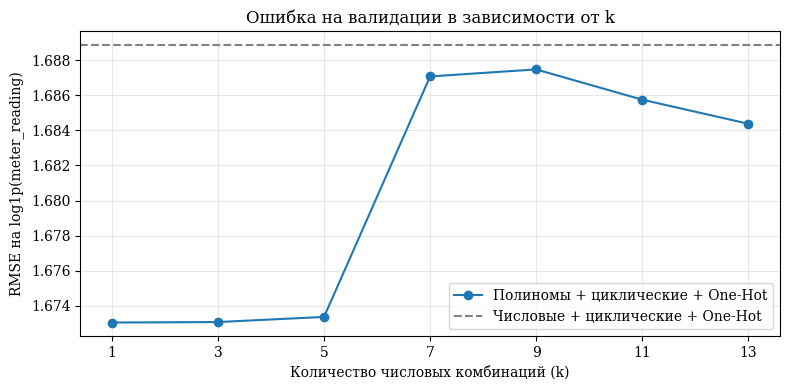

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(results_k["k"], results_k["rmse_log"], marker="o", label="Полиномы + циклические + One-Hot")
ax.axhline(rmse_cyclic, color="gray", linestyle="--", label="Числовые + циклические + One-Hot")
ax.set(xlabel="Количество числовых комбинаций (k)", ylabel="RMSE на log1p(meter_reading)",
       title="Ошибка на валидации в зависимости от k")
ax.set_xticks(results_k["k"])
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:
import json
model_k5, scaler_k5, powers_k5, rmse_k5 = fit_polynomial_model(k=10)

print(f"RMSE(log1p): {rmse_k5:.6f}")

selected_features = []
all_powers = poly_numeric.powers_
for powers in powers_k5:
    idx = np.flatnonzero((all_powers == powers).all(axis=1))[0]
    name = str(names_poly[idx])
    selected_features.append(name)
    print(name)

with open("polynomial_features_k10.json", "w", encoding="utf-8") as file:
    json.dump(selected_features, file, ensure_ascii=False, indent=2)

RMSE(log1p): 1.686547
square_feet
square_feet year_built^2
square_feet air_temperature^2
square_feet air_temperature air_temperature_mean_3h
square_feet dew_temperature^2
square_feet wind_speed^2
square_feet air_temperature_mean_3h^2
square_feet air_temperature_mean_72h^2
square_feet air_temperature_lag_24h^2
square_feet air_temperature_diff_72h^2


Для начала попробуем классические модели

### LightGBM и CatBoost: полиномиальные признаки и группировки

Бустинги используют 18 признаков: 10 полиномиальных комбинаций из `polynomial_features_k10.json` (построены по масштабированным числовым признакам, все содержат `square_feet`), sin/cos часа и направления ветра и четыре категории — `meter`, `site_id`, `primary_use`, `building_id`, которые передаются бустингам нативно, без One-Hot. Сырые погодные признаки отдельно, день недели и день года в матрицу не входят. MLP ниже строит полиномы по тому же принципу, но берёт k из 200 отобранных и добавляет One-Hot.

Используется первый фолд из `BOOSTING_FOLDS`: базы (`fit`) обучаются на январе–июле, август (`meta`) нужен для обучения метамодели стэкинга, сентябрь (`predict`) — для сравнения группировок и оценки стэкинга. Early stopping не используется: число деревьев задано в `LGBM_PARAMS` и `CATBOOST_PARAMS`. Группировки ранжируются по RMSE сентября, поэтому для выбранных группировок сентябрь — не полностью независимая оценка. Фолды с октябрём–декабрём в этом разделе не запускаются: чтобы их проверить, передайте в `prepare_boosting_fold` другой элемент `BOOSTING_FOLDS` и повторите ячейки ниже. Во всех таблицах `meta` и `predict` показаны отдельно.

Из `fit` исключён известный сбой электрических счётчиков site 0 в первые 3378 часов 2016 года ([код исходного решения ASHRAE](https://github.com/buds-lab/ashrae-great-energy-predictor-3-solution-analysis/blob/master/solutions/rank-3/generate_datasets.ipynb)); остальные нули сохраняются, а исключение применяется только к `fit`. По умолчанию `BOOSTING_MAX_ROWS` не ограничивает строки: `fit` ≈ 11.3 млн, `meta` ≈ 1.7 млн, `predict` ≈ 1.7 млн. При нехватке памяти задайте числовые лимиты (выборка случайная, seed фиксирован) и заново выполните подготовку фолда.

Сравниваем общую модель LightGBM и модели по `meter`, `site_id + meter`, `building_id + meter`. Для групп с менее чем 100 строками в `fit`, с постоянной целевой переменной и для групп, которых нет в `fit`, используем прогноз общей модели. В стэкинге участвуют обе общие модели (LightGBM и CatBoost) и две лучшие группировки, выбранные по LightGBM и применённые к обоим алгоритмам. MLP в этот раздел не входит. Ядро: `.venv-boosting/bin/python`.

In [17]:
import lightgbm, catboost
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from scipy.optimize import minimize

BASE_END = pd.Timestamp("2016-08-01")
SELECTION_END = pd.Timestamp("2016-09-01")
assert BASE_END < SELECTION_END < VALID_START
BOOSTING_BATCH_SIZE = 50_000
BOOSTING_MAX_ROWS = {"fit": 1_000_000, "meta": 200_000, "predict": 200_000}
BOOSTING_CATEGORICAL = categorical_columns.copy()
GROUPINGS = {
    "meter": ["meter"],
    "site_id + meter": ["site_id", "meter"],
    "site_id + primary_use + meter": ["site_id", "primary_use", "meter"],
    "building_id + meter": ["building_id", "meter"],
}
BAD_SITE0_END = (
    pd.Timestamp("2016-01-01") + pd.Timedelta(hours=3378)
)

with open("polynomial_features_k10.json", "r", encoding="utf-8") as file:
    BEST_FEATURES = json.load(file)

print("Выбранные признаки:", BEST_FEATURES)

all_names = pd.Index(
    poly_numeric.get_feature_names_out(numeric_columns_cyclic)
)
selected_indices = all_names.get_indexer(BEST_FEATURES)
if (selected_indices < 0).any():
    raise ValueError("Некоторые выбранные признаки не найдены")
BEST_POWERS = poly_numeric.powers_[selected_indices]

LGBM_PARAMS = dict(
    objective="regression", n_estimators=100, random_state=42, verbosity=-1, n_jobs=2,
)
CATBOOST_PARAMS = dict(
    loss_function="RMSE", iterations=100, random_seed=42, verbose=False, allow_writing_files=False, thread_count=2, max_ctr_complexity=1
)
PERIODS_BOOSTING = {
    "fit": (None, BASE_END),
    "select": (BASE_END, SELECTION_END),
    "meta": (SELECTION_END, VALID_START),
    "final": (VALID_START, None),
}

Выбранные признаки: ['square_feet', 'square_feet year_built^2', 'square_feet air_temperature^2', 'square_feet air_temperature air_temperature_mean_3h', 'square_feet dew_temperature^2', 'square_feet wind_speed^2', 'square_feet air_temperature_mean_3h^2', 'square_feet air_temperature_mean_72h^2', 'square_feet air_temperature_lag_24h^2', 'square_feet air_temperature_diff_72h^2']


In [18]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm, catboost
from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

ART = Path("artifacts")
DATA_DIR = "ashrae-energy-prediction"

train_full = pd.read_parquet(ART / "train_full.parquet")
test = pd.read_parquet(ART / "test.parquet")
weather_test_aligned = pd.read_parquet(ART / "weather_test_aligned.parquet")
building_metadata = pd.read_csv(f"{DATA_DIR}/building_metadata.csv")

# Все имена из двух файлов становятся обычными переменными ноутбука.
globals().update(joblib.load(ART / "boosting_config.joblib"))
globals().update(joblib.load(ART / "boosting_results.joblib"))

# Константы из ячейки с импортами бустингов.
VALID_START = pd.Timestamp("2016-10-01")
BOOSTING_BATCH_SIZE = 50_000
BOOSTING_CATEGORICAL = categorical_columns.copy()
GROUPINGS = {
    "meter": ["meter"],
    "site_id + meter": ["site_id", "meter"],
    "building_id + meter": ["building_id", "meter"],
}
BAD_SITE0_END = (
    pd.Timestamp("2016-01-01") + pd.Timedelta(hours=3378)
)


def cyclic_numeric_batch(frame):
    # Копия функции из ячейки с экспериментом 2 (без обращения к train_part).
    result = frame[numeric_columns_cyclic].astype(np.float32).fillna(0)
    angle = frame["timestamp"].dt.hour.to_numpy(dtype=np.float32)
    angle *= np.float32(2 * np.pi / 24)
    result["hour_sin"], result["hour_cos"] = np.sin(angle), np.cos(angle)
    if "wind_direction" in frame:
        angle = frame["wind_direction"].to_numpy(dtype=np.float32, copy=True)
        np.deg2rad(angle, out=angle)
        result["wind_direction_sin"] = np.sin(angle)
        result["wind_direction_cos"] = np.cos(angle)
    else:
        result[["wind_direction_sin", "wind_direction_cos"]] = frame[
            ["wind_direction_sin", "wind_direction_cos"]
        ]
    return result.fillna(0).to_numpy(dtype=np.float32)


In [19]:
BOOSTING_FOLDS = []

for predict_start in pd.date_range(
    "2016-09-01", "2016-12-01", freq="MS"
):
    meta_start = predict_start - pd.DateOffset(months=1)

    BOOSTING_FOLDS.append({
        "fit": (pd.Timestamp("2016-01-01"), meta_start),
        "meta": (meta_start, predict_start),
        "predict": (
            predict_start,
            predict_start + pd.DateOffset(months=1),
        ),
    })

BOOSTING_FOLDS

[{'fit': (Timestamp('2016-01-01 00:00:00'), Timestamp('2016-08-01 00:00:00')),
  'meta': (Timestamp('2016-08-01 00:00:00'), Timestamp('2016-09-01 00:00:00')),
  'predict': (Timestamp('2016-09-01 00:00:00'),
   Timestamp('2016-10-01 00:00:00'))},
 {'fit': (Timestamp('2016-01-01 00:00:00'), Timestamp('2016-09-01 00:00:00')),
  'meta': (Timestamp('2016-09-01 00:00:00'), Timestamp('2016-10-01 00:00:00')),
  'predict': (Timestamp('2016-10-01 00:00:00'),
   Timestamp('2016-11-01 00:00:00'))},
 {'fit': (Timestamp('2016-01-01 00:00:00'), Timestamp('2016-10-01 00:00:00')),
  'meta': (Timestamp('2016-10-01 00:00:00'), Timestamp('2016-11-01 00:00:00')),
  'predict': (Timestamp('2016-11-01 00:00:00'),
   Timestamp('2016-12-01 00:00:00'))},
 {'fit': (Timestamp('2016-01-01 00:00:00'), Timestamp('2016-11-01 00:00:00')),
  'meta': (Timestamp('2016-11-01 00:00:00'), Timestamp('2016-12-01 00:00:00')),
  'predict': (Timestamp('2016-12-01 00:00:00'),
   Timestamp('2017-01-01 00:00:00'))}]

In [20]:
def take_period(df, start, stop, max_rows=None, exclude=None):
    mask = (
        (df["timestamp"] >= start)
        & (df["timestamp"] < stop)
    )

    if exclude is not None:
        mask &= ~exclude

    positions = np.flatnonzero(mask.to_numpy())

    if max_rows is not None and len(positions) > max_rows:
        positions = np.random.default_rng(42).choice(
            positions,  size=max_rows,  replace=False,
        )
        positions.sort()

    frame = df.iloc[positions].reset_index(drop=True)

    if frame.empty:
        raise ValueError(f"Пустой период: {start} — {stop}")

    return frame


# Сырые значения без fillna(0): LightGBM и CatBoost сами обрабатывают NaN.
RAW_COLUMNS = [
    "air_temperature", "dew_temperature", "cloud_coverage",
    "sea_level_pressure", "wind_speed", "precip_depth_1_hr",
    "square_feet", "year_built", "floor_count",
    "air_temperature_mean_3h", "air_temperature_mean_24h",
    "air_temperature_mean_72h", "air_temperature_lag_24h",
    "air_temperature_diff_72h",
]

# Нерабочие дни 2016–2018 по странам площадок: праздник и день, на который
# он перенесён. У США добавлена пятница после Дня благодарения.
HOLIDAYS = {
    "US": [
        "2016-01-01", "2016-01-18", "2016-02-15", "2016-05-30", "2016-07-04",
        "2016-09-05", "2016-10-10", "2016-11-11", "2016-11-24", "2016-11-25",
        "2016-12-25", "2016-12-26",
        "2017-01-01", "2017-01-02", "2017-01-16", "2017-02-20", "2017-05-29",
        "2017-07-04", "2017-09-04", "2017-10-09", "2017-11-10", "2017-11-11",
        "2017-11-23", "2017-11-24", "2017-12-25",
        "2018-01-01", "2018-01-15", "2018-02-19", "2018-05-28", "2018-07-04",
        "2018-09-03", "2018-10-08", "2018-11-11", "2018-11-12", "2018-11-22",
        "2018-11-23", "2018-12-25",
    ],
    "UK": [
        "2016-01-01", "2016-03-25", "2016-03-28", "2016-05-02", "2016-05-30",
        "2016-08-29", "2016-12-25", "2016-12-26", "2016-12-27",
        "2017-01-01", "2017-01-02", "2017-04-14", "2017-04-17", "2017-05-01",
        "2017-05-29", "2017-08-28", "2017-12-25", "2017-12-26",
        "2018-01-01", "2018-03-30", "2018-04-02", "2018-05-07", "2018-05-28",
        "2018-08-27", "2018-12-25", "2018-12-26",
    ],
    "IE": [
        "2016-01-01", "2016-03-17", "2016-03-28", "2016-05-02", "2016-06-06",
        "2016-08-01", "2016-10-31", "2016-12-25", "2016-12-26", "2016-12-27",
        "2017-01-01", "2017-01-02", "2017-03-17", "2017-04-17", "2017-05-01",
        "2017-06-05", "2017-08-07", "2017-10-30", "2017-12-25", "2017-12-26",
        "2018-01-01", "2018-03-17", "2018-03-19", "2018-04-02", "2018-05-07",
        "2018-06-04", "2018-08-06", "2018-10-29", "2018-12-25", "2018-12-26",
    ],
    "CA": [
        "2016-01-01", "2016-02-15", "2016-03-25", "2016-05-23", "2016-07-01",
        "2016-08-01", "2016-09-05", "2016-10-10", "2016-12-25", "2016-12-26",
        "2016-12-27",
        "2017-01-01", "2017-01-02", "2017-02-20", "2017-04-14", "2017-05-22",
        "2017-07-01", "2017-07-03", "2017-08-07", "2017-09-04", "2017-10-09",
        "2017-12-25", "2017-12-26",
        "2018-01-01", "2018-02-19", "2018-03-30", "2018-05-21", "2018-07-01",
        "2018-07-02", "2018-08-06", "2018-09-03", "2018-10-08", "2018-12-25",
        "2018-12-26",
    ],
}
# Площадки вне США; смещения UTC у них те же, что в WEATHER_UTC_OFFSETS.
SITE_COUNTRY = {1: "UK", 5: "UK", 12: "IE", 7: "CA", 11: "CA"}


def holiday_flags(frame):
    """1 у строк, попавших на нерабочий день страны своей площадки."""
    dates = frame["timestamp"].dt.normalize()
    country = frame["site_id"].map(SITE_COUNTRY).fillna("US")
    flags = np.zeros(len(frame), dtype=np.int8)

    for name, days in HOLIDAYS.items():
        flags[
            ((country == name) & dates.isin(pd.to_datetime(days))).to_numpy()
        ] = 1

    return flags


def make_boosting_features(frame, scaler, category_maps):
    n_numeric = len(numeric_columns_cyclic)
    n_poly = len(BEST_FEATURES)

    # Выделяем итоговую матрицу один раз.
    values = np.empty(
        (len(frame), n_poly + len(cyclic_columns)),
        dtype=np.float32,
    )

    for start in range(0, len(frame), BOOSTING_BATCH_SIZE):
        stop = min(start + BOOSTING_BATCH_SIZE, len(frame))
        batch = frame.iloc[start:stop]

        scaled = scaler.transform(cyclic_numeric_batch(batch))
        numeric = scaled[:, :n_numeric]

        combinations = np.ones(
            (len(batch), n_poly),
            dtype=np.float32,
        )

        for j, powers in enumerate(BEST_POWERS):
            for column in np.flatnonzero(powers):
                for _ in range(int(powers[column])):
                    combinations[:, j] *= numeric[:, column]

        values[start:stop, :n_poly] = combinations
        values[start:stop, n_poly:] = scaled[:, n_numeric:]

    X = pd.DataFrame(
        values,
        columns=BEST_FEATURES + list(cyclic_columns),
    )

    # Категории добавляем отдельно, без One-Hot.
    for column in BOOSTING_CATEGORICAL:
        X[column] = (frame[column].map(category_maps[column]).fillna(-1).to_numpy(dtype=np.int32))

    # Префикс raw_: square_feet уже есть среди полиномиальных (масштабированный).
    for column in RAW_COLUMNS:
        X[f"raw_{column}"] = frame[column].to_numpy(dtype=np.float32)

    # Метки времени местные: погода выровнена под счётчики.
    X["hour"] = frame["timestamp"].dt.hour.to_numpy(dtype=np.int8)
    X["dayofweek"] = frame["timestamp"].dt.dayofweek.to_numpy(dtype=np.int8)
    X["is_holiday"] = holiday_flags(frame)
    # Месяц, а не день года: на блоках месяцев день года хуже и вместе с месяцем
    # ничего не добавляет.
    X["month"] = frame["timestamp"].dt.month.to_numpy(dtype=np.int8)

    return X

In [21]:
def prepare_boosting_fold(df, periods):
    boosting_data, period_rows = {}, []

    bad = ((df["site_id"] == 0)
        & (df["meter"] == 0)
        & (df["timestamp"] < BAD_SITE0_END)
    ) | df["constant_run"]

    for name in ["fit", "meta", "predict"]:
        start, stop = periods[name]

        frame = take_period(df, start, stop,
            max_rows=BOOSTING_MAX_ROWS[name],
            exclude=bad if name == "fit" else None,
        )

        if name == "fit":
            scaler = StandardScaler()

            for batch_start in range(0, len(frame), BOOSTING_BATCH_SIZE):
                batch = frame.iloc[
                    batch_start:batch_start + BOOSTING_BATCH_SIZE
                ]
                scaler.partial_fit(cyclic_numeric_batch(batch))

            category_maps = {column: {
                value: i for i, value in enumerate(frame[column].dropna().unique())
                }
                for column in BOOSTING_CATEGORICAL
            }

        X = make_boosting_features(frame, scaler, category_maps)

        boosting_data[name] = {"X": X, "y": np.log1p(
                frame["meter_reading"].to_numpy(dtype=np.float64)
            ),
            "groups": frame[
                ["meter", "site_id", "building_id", "primary_use"]
            ].copy(),
        }

        period_rows.append({
            "period": name,
            "rows": len(frame),
            "features": X.shape[1],
            "MB": X.memory_usage(deep=True).sum() / 2**20,
            "start": frame["timestamp"].min(),
            "end": frame["timestamp"].max(),
        })

        del frame, X

    return boosting_data,  pd.DataFrame(period_rows),  scaler, category_maps


# Первый шаг: январь–июль → август → сентябрь.
boosting_data, period_rows, boosting_scaler, boosting_category_maps = prepare_boosting_fold(train_full, BOOSTING_FOLDS[0])

display(period_rows)

,period,rows,features,MB,start,end
0,fit,1000000,36,125.885136,2016-01-01,2016-07-31 23:00:00
1,meta,200000,36,25.177128,2016-08-01,2016-08-31 23:00:00
2,predict,200000,36,25.177128,2016-09-01,2016-09-30 23:00:00


In [22]:
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED
from itertools import islice
from time import perf_counter

MIN_GROUP_ROWS = 100
GROUP_WORKERS = 2


def global_predictions(
    kind, X_fit, y_fit, X_eval, params,
    batch_size=BOOSTING_BATCH_SIZE,
):
    """Обучает бустинг и возвращает прогнозы в шкале log1p."""
    if batch_size < 1:
        raise ValueError("batch_size должен быть положительным")

    if kind == "lightgbm":
        model = lightgbm.LGBMRegressor(**params)
        fit_params = {"categorical_feature": BOOSTING_CATEGORICAL}
        predict_params = {}

    elif kind == "catboost":
        model = catboost.CatBoostRegressor(**params)
        fit_params = {"cat_features": BOOSTING_CATEGORICAL}
        predict_params = {"thread_count": params.get("thread_count", 2)}

    else:
        raise ValueError(f"Неизвестный алгоритм: {kind}")

    model.fit(X_fit, y_fit, **fit_params)

    predictions = {}

    for name, X in X_eval.items():
        pred = np.empty(len(X), dtype=np.float64)

        for start in range(0, len(X), batch_size):
            stop = min(start + batch_size, len(X))
            pred[start:stop] = model.predict(
                X.iloc[start:stop],
                **predict_params,
            )

        predictions[name] = np.maximum(pred, 0)

    return predictions


def grouped_predictions(
    kind, X_fit, y_fit, groups_fit, X_eval, groups_eval,
    group_columns, params, fallback,
    min_group_rows=MIN_GROUP_ROWS,
    batch_size=BOOSTING_BATCH_SIZE,
    progress_every=100,
    n_workers=1,
):
    """Обучает локальные модели; для остальных строк оставляет fallback."""
    if n_workers < 1:
        raise ValueError("n_workers должен быть положительным")

    started = perf_counter()
    columns = list(group_columns)
    y_fit = np.asarray(y_fit)

    fit_indices = groups_fit.groupby(
        columns, sort=False, observed=True
    ).indices

    eval_indices = {
        name: groups_eval[name].groupby(
            columns, sort=False, observed=True
        ).indices
        for name in X_eval
    }

    predictions = {name: np.array(fallback[name], dtype=np.float64, copy=True) for name in X_eval}

    local_rows = dict.fromkeys(X_eval, 0)
    n_workers = max(1, min(n_workers, len(fit_indices)))

    local_params = dict(params)

    # Ограничиваем внутренние потоки при параллельном обучении групп.
    if n_workers > 1:
        parameter = (
            "n_jobs" if kind == "lightgbm" else "thread_count"
        )
        local_params[parameter] = 1

    def fit_group(item):
        key, rows = item

        if len(rows) < min_group_rows or np.ptp(y_fit[rows]) == 0:
            return {}, {}

        targets = {
            name: indices[key]
            for name, indices in eval_indices.items()
            if key in indices
        }

        if not targets:
            return {}, {}

        local = global_predictions(
            kind=kind,
            X_fit=X_fit.iloc[rows],
            y_fit=y_fit[rows],
            X_eval={
                name: X_eval[name].iloc[indices]
                for name, indices in targets.items()
            },
            params=local_params,
            batch_size=batch_size,
        )

        return local, targets

    def results():
        if n_workers == 1:
            yield from map(fit_group, fit_indices.items())
            return

        with ThreadPoolExecutor(max_workers=n_workers) as pool:
            items = iter(fit_indices.items())

            pending = {
                pool.submit(fit_group, item)
                for item in islice(items, 2 * n_workers)
            }

            while pending:
                completed, pending = wait(
                    pending,
                    return_when=FIRST_COMPLETED,
                )

                for future in completed:
                    yield future.result()

                    item = next(items, None)
                    if item is not None:
                        pending.add(pool.submit(fit_group, item))

    n_models = 0
    total = len(fit_indices)
    label = f"{kind} ({' + '.join(columns)})"

    if progress_every:
        print(
            f"{label}: старт, {total} групп, "
            f"параллельных задач: {n_workers}",
            flush=True,
        )

    for processed, (local, targets) in enumerate(results(), 1):
        for name, indices in targets.items():
            predictions[name][indices] = local[name]
            local_rows[name] += len(indices)

        n_models += bool(targets)

        if progress_every and (
            processed % progress_every == 0 or processed == total
        ):
            print(
                f"{label}: {processed}/{total}, "
                f"моделей {n_models}, "
                f"пропущено {processed - n_models}, "
                f"{perf_counter() - started:.1f} с",
                flush=True,
            )

    stats = {
        "n_models": n_models,
        "fallback_share": {
            name: (
                1 - local_rows[name] / len(pred)
                if len(pred) else 0.0
            )
            for name, pred in predictions.items()
        },
    }

    return predictions, stats


def run_grouped_booster(kind, grouping, data, params, fallback):
    """Запускает выбранную группировку для одного месячного шага."""
    fit_data = data["fit"]
    evaluation_names = ["meta", "predict"]

    workers = GROUP_WORKERS if kind == "lightgbm" else 1

    return grouped_predictions(
        kind=kind,
        X_fit=fit_data["X"],
        y_fit=fit_data["y"],
        groups_fit=fit_data["groups"],
        X_eval={
            name: data[name]["X"]
            for name in evaluation_names
        },
        groups_eval={
            name: data[name]["groups"]
            for name in evaluation_names
        },
        group_columns=GROUPINGS[grouping],
        params=params,
        fallback=fallback,
        min_group_rows=MIN_GROUP_ROWS,
        batch_size=BOOSTING_BATCH_SIZE,
        n_workers=workers,
        progress_every=(
            1 if grouping == "meter"
            else 10 if grouping == "site_id + meter"
            else 100
        ),
    )


def rmse_log(y, pred):
    return float(np.sqrt(mean_squared_error(y, pred)))


def fit_boosting_stack(predictions, data, alpha=1.0):
    """Обучает Ridge на meta и прогнозирует следующий месяц."""
    names = list(predictions)

    Z_meta = np.column_stack([
        predictions[name]["meta"]
        for name in names
    ])

    Z_predict = np.column_stack([
        predictions[name]["predict"]
        for name in names
    ])

    meta_model = Ridge(alpha=alpha, positive=True)
    meta_model.fit(Z_meta, data["meta"]["y"])

    stack_predictions = np.maximum(
        meta_model.predict(Z_predict),
        0,
    )

    weights = pd.Series(
        meta_model.coef_,
        index=names,
        name="stack_weight",
    )

    return stack_predictions, weights, meta_model

In [23]:
fit_data = boosting_data["fit"]
evaluation_names = ["meta", "predict"]

# Общая LightGBM: её прогнозы также используются как fallback.
global_base_predictions = {}

global_base_predictions["lightgbm"] = global_predictions(
    kind="lightgbm",
    X_fit=fit_data["X"],
    y_fit=fit_data["y"],
    X_eval={
        period: boosting_data[period]["X"]
        for period in evaluation_names
    },
    params=LGBM_PARAMS,
    batch_size=BOOSTING_BATCH_SIZE,
)


In [24]:
grouping_rows = []
lgbm_group_predictions = {}
lgbm_group_stats = {}

# Общая модель тоже входит в сравнение.
global_pred = global_base_predictions["lightgbm"]

grouping_rows.append({
    "grouping": "global",
    "rmse_meta": rmse_log(
        boosting_data["meta"]["y"],
        global_pred["meta"],
    ),
    "rmse_predict": rmse_log(
        boosting_data["predict"]["y"],
        global_pred["predict"],
    ),
    "local_models": 0,
    "fallback_share": np.nan,
})

for grouping in GROUPINGS:
    predictions, stats = run_grouped_booster(
        kind="lightgbm",
        grouping=grouping,
        data=boosting_data,
        params=LGBM_PARAMS,
        fallback=global_pred,
    )

    lgbm_group_predictions[grouping] = predictions
    lgbm_group_stats[grouping] = stats

    score = rmse_log(
        boosting_data["predict"]["y"],
        predictions["predict"],
    )

    grouping_rows.append({
        "grouping": grouping,
        "rmse_meta": rmse_log(
            boosting_data["meta"]["y"],
            predictions["meta"],
        ),
        "rmse_predict": score,
        "local_models": stats["n_models"],
        "fallback_share": stats["fallback_share"]["predict"],
    })

    print(
        f"{grouping}: RMSE месяца проверки = {score:.6f}",
        flush=True,
    )

grouping_comparison = pd.DataFrame(grouping_rows)
display(grouping_comparison)


lightgbm (meter): старт, 4 групп, параллельных задач: 2
lightgbm (meter): 1/4, моделей 1, пропущено 0, 1.0 с
lightgbm (meter): 2/4, моделей 2, пропущено 0, 3.8 с
lightgbm (meter): 3/4, моделей 3, пропущено 0, 5.6 с
lightgbm (meter): 4/4, моделей 4, пропущено 0, 7.0 с
meter: RMSE месяца проверки = 1.008304
lightgbm (site_id + meter): старт, 39 групп, параллельных задач: 2
lightgbm (site_id + meter): 10/39, моделей 10, пропущено 0, 2.7 с
lightgbm (site_id + meter): 20/39, моделей 20, пропущено 0, 4.2 с
lightgbm (site_id + meter): 30/39, моделей 30, пропущено 0, 6.2 с
lightgbm (site_id + meter): 39/39, моделей 39, пропущено 0, 7.3 с
site_id + meter: RMSE месяца проверки = 1.036952
lightgbm (building_id + meter): старт, 2364 групп, параллельных задач: 2
lightgbm (building_id + meter): 100/2364, моделей 99, пропущено 1, 1.4 с
lightgbm (building_id + meter): 200/2364, моделей 199, пропущено 1, 2.9 с
lightgbm (building_id + meter): 300/2364, моделей 298, пропущено 2, 4.3 с
lightgbm (building_

,grouping,rmse_meta,rmse_predict,local_models,fallback_share
0,global,1.008778,1.049950,0,NaN
1,meter,0.941981,1.008304,4,0.000000
2,site_id + meter,0.945718,1.036952,39,0.000000
3,building_id + meter,0.987561,1.073811,2341,0.012865


In [25]:
TOP_GROUPINGS = 2

best_groupings = (
    grouping_comparison
    .loc[lambda df: df["grouping"] != "global"]
    .nsmallest(TOP_GROUPINGS, "rmse_predict")
    ["grouping"]
    .tolist()
)

print("Лучшие группировки:", best_groupings)

Лучшие группировки: ['meter', 'site_id + meter']


### Стэкинг общих моделей и лучших группировок

Для каждого алгоритма берём общую модель и две группировки, выбранные по LightGBM по RMSE сентября. Прогнозы LightGBM повторно не считаются: используются уже рассчитанные выше. Все базы обучены на январе–июле без early stopping.

Метамодель — `Ridge(alpha=1.0, positive=True)`: обучается на августовских (`meta`) прогнозах баз и применяется к сентябрю (`predict`). Других вариантов метамодели (выпуклого смешивания, среднего) в коде нет. Так как группировки выбраны по сентябрю, ошибка стэкинга на сентябре слегка оптимистична.

In [26]:
fit_data = boosting_data["fit"]
evaluation_names = ["meta", "predict"]
base_predictions, base_summary = {}, []

for kind, params in [
    ("lightgbm", LGBM_PARAMS),
    ("catboost", CATBOOST_PARAMS),
]:
    # Обучаем общую модель, если её прогнозов ещё нет.
    if kind not in global_base_predictions:
        print(f"Общая модель {kind}...", flush=True)

        global_base_predictions[kind] = global_predictions(
            kind=kind,
            X_fit=fit_data["X"],
            y_fit=fit_data["y"],
            X_eval={
                period: boosting_data[period]["X"]
                for period in evaluation_names
            },
            params=params,
            batch_size=BOOSTING_BATCH_SIZE,
        )

    global_pred = global_base_predictions[kind]
    global_name = f"{kind}: global"

    base_predictions[global_name] = global_pred

    base_summary.append({
        "model": global_name,
        "local_models": 0,
        "rmse_meta": rmse_log(
            boosting_data["meta"]["y"],
            global_pred["meta"],
        ),
        "rmse_predict": rmse_log(
            boosting_data["predict"]["y"],
            global_pred["predict"],
        ),
        "fallback_meta": np.nan,
        "fallback_predict": np.nan,
    })

    for grouping in best_groupings:
        if kind == "lightgbm":
            predictions = lgbm_group_predictions[grouping]
            stats = lgbm_group_stats[grouping]

        else:
            predictions, stats = run_grouped_booster(
                kind=kind,
                grouping=grouping,
                data=boosting_data,
                params=params,
                fallback=global_pred,
            )

        name = f"{kind}: {grouping}"
        base_predictions[name] = predictions

        base_summary.append({
            "model": name,
            "local_models": stats["n_models"],
            "rmse_meta": rmse_log(
                boosting_data["meta"]["y"],
                predictions["meta"],
            ),
            "rmse_predict": rmse_log(
                boosting_data["predict"]["y"],
                predictions["predict"],
            ),
            "fallback_meta": stats["fallback_share"]["meta"],
            "fallback_predict": stats["fallback_share"]["predict"],
        })

base_comparison = pd.DataFrame(base_summary)
display(base_comparison)

Общая модель catboost...


catboost (meter): старт, 4 групп, параллельных задач: 1
catboost (meter): 1/4, моделей 1, пропущено 0, 10.4 с
catboost (meter): 2/4, моделей 2, пропущено 0, 11.6 с
catboost (meter): 3/4, моделей 3, пропущено 0, 15.2 с
catboost (meter): 4/4, моделей 4, пропущено 0, 17.6 с
catboost (site_id + meter): старт, 39 групп, параллельных задач: 1
catboost (site_id + meter): 10/39, моделей 10, пропущено 0, 7.0 с
catboost (site_id + meter): 20/39, моделей 20, пропущено 0, 11.3 с
catboost (site_id + meter): 30/39, моделей 30, пропущено 0, 17.0 с
catboost (site_id + meter): 39/39, моделей 39, пропущено 0, 19.9 с


,model,local_models,rmse_meta,rmse_predict,fallback_meta,fallback_predict
0,lightgbm: global,0,1.008778,1.049950,NaN,NaN
1,lightgbm: meter,4,0.941981,1.008304,0.0,0.0
2,lightgbm: site_id + meter,39,0.945718,1.036952,0.0,0.0
3,catboost: global,0,1.182381,1.168806,NaN,NaN
4,catboost: meter,4,1.025277,1.072365,0.0,0.0
5,catboost: site_id + meter,39,0.973889,1.092016,0.0,0.0


In [27]:
# Обучаем метамодель на meta и прогнозируем predict.
stack_predictions, stack_weights, meta_model = fit_boosting_stack(
    base_predictions,
    boosting_data,
)

Z_meta = np.column_stack([
    predictions["meta"]
    for predictions in base_predictions.values()
])

stack_meta_predictions = np.maximum(
    meta_model.predict(Z_meta),
    0,
)

stack_meta_rmse = rmse_log(
    boosting_data["meta"]["y"],
    stack_meta_predictions,
)

# Ошибки базовых моделей.
comparison_rows = [
    {
        "model": name,
        "RMSE(log1p), meta": rmse_log(
            boosting_data["meta"]["y"],
            predictions["meta"],
        ),
        "RMSE(log1p), predict": rmse_log(
            boosting_data["predict"]["y"],
            predictions["predict"],
        ),
    }
    for name, predictions in base_predictions.items()
]

# Для стэкинга показываем только ошибку следующего месяца.
comparison_rows.append({
    "model": "Stacking: LightGBM + CatBoost",
    "RMSE(log1p), meta": stack_meta_rmse,
    "RMSE(log1p), predict": rmse_log(
        boosting_data["predict"]["y"],
        stack_predictions,
    ),
})

boosting_final_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("RMSE(log1p), predict")
    .reset_index(drop=True)
)

display(boosting_final_comparison)
display(stack_weights)

,model,"RMSE(log1p), meta","RMSE(log1p), predict"
0,Stacking: LightGBM + CatBoost,0.927853,0.999616
1,lightgbm: meter,0.941981,1.008304
2,lightgbm: site_id + meter,0.945718,1.036952
3,lightgbm: global,1.008778,1.049950
4,catboost: meter,1.025277,1.072365
5,catboost: site_id + meter,0.973889,1.092016
6,catboost: global,1.182381,1.168806


lightgbm: global             0.095985
lightgbm: meter              0.325879
lightgbm: site_id + meter    0.396820
catboost: global             0.000000
catboost: meter              0.038919
catboost: site_id + meter    0.136924
Name: stack_weight, dtype: float64

### MLP: число признаков × архитектура, затем dropout

`PolynomialFeatures(degree=3, include_bias=False)` строится по 9 масштабированным числовым признакам (`mlp_numeric`); из 219 комбинаций `SelectKBest(f_regression)` оставляет 200 лучших в порядке убывания оценки. Масштабирование, полиномы и отбор обучаются только на `fit` (январь–июль). Для каждого k = 30, 50, 100, 200 проверяем четыре архитектуры скрытых слоёв: `32`, `32–8`, `64–32–8`, `64–32–16–8`. Сначала обучаем все 16 вариантов без dropout и строим heatmap августовского RMSE: строки — архитектуры, столбцы — k. Затем в отдельной ячейке для трёх лучших пар «k + архитектура» проверяем dropout 0.1, 0.25, 0.4 после каждого скрытого слоя (9 вариантов).

Категории One-Hot и sin/cos часа и направления ветра добавляются отдельно и в k не входят. Обучение — Adam (lr 1e-3), MSE, батч 1024, фиксированные 15 эпох (`MLP_EPOCHS`) без early stopping, поэтому берётся сеть после последней эпохи. Август (`meta`) используется для выбора k, архитектуры и dropout, поэтому это валидация: в `mlp_best` попадает вариант с наименьшим RMSE августа среди всех 25 запусков (16 без dropout и 9 с dropout). Сентябрь (`predict`) — оценка только выбранной модели. По умолчанию берём одинаковые для всех вариантов выборки до 100 000 строк из каждого периода (`MLP_MAX_ROWS`). Scaler, encoder и отбор признаков обучаются только на `fit`.

Для запуска нужна только таблица `train_full` (загрузка и объединение выше): `take_period`, `BOOSTING_FOLDS` и `BAD_SITE0_END` определены в первой ячейке раздела, настройки бустингов не требуются. Обучение PyTorch выполняется в ячейках ядра `.venv-boosting` на доступном устройстве (mps, cuda или cpu). Плотными становятся только мини-батчи; лучшая сеть доступна в `mlp_best_model`.

API: [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html), [SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html), [heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html), [Dropout](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html).

In [ ]:
BAD_SITE0_END = (
    pd.Timestamp("2016-01-01") + pd.Timedelta(hours=3378)
)

BOOSTING_FOLDS = []

for predict_start in pd.date_range(
    "2016-09-01", "2016-12-01", freq="MS"
):
    meta_start = predict_start - pd.DateOffset(months=1)

    BOOSTING_FOLDS.append({
        "fit": (pd.Timestamp("2016-01-01"), meta_start),
        "meta": (meta_start, predict_start),
        "predict": (
            predict_start,
            predict_start + pd.DateOffset(months=1),
        ),
    })


def take_period(df, start, stop, max_rows=None, exclude=None):
    mask = (
        (df["timestamp"] >= start)
        & (df["timestamp"] < stop)
    )

    if exclude is not None:
        mask &= ~exclude

    positions = np.flatnonzero(mask.to_numpy())

    if max_rows is not None and len(positions) > max_rows:
        positions = np.random.default_rng(42).choice(
            positions,
            size=max_rows,
            replace=False,
        )
        positions.sort()

    frame = df.iloc[positions].reset_index(drop=True)

    if frame.empty:
        raise ValueError(f"Пустой период: {start} — {stop}")

    return frame

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from torch import nn
from scipy import sparse
from sklearn.preprocessing import (
    PolynomialFeatures, StandardScaler, OneHotEncoder
)
from sklearn.feature_selection import SelectKBest, f_regression

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Устройство:", device)

MLP_K_VALUES = [30, 50, 100, 200]
MLP_ARCHITECTURES = [
    (32,), (32, 8), (64, 32, 8), (64, 32, 16, 8)
]
MLP_DROPOUTS = [0.1, 0.25, 0.4]

MLP_MAX_ROWS = 100_000
MLP_EPOCHS = 15
MLP_BATCH_SIZE = 1024

# 0: январь–июль → август → сентябрь.
MLP_FOLD_INDEX = 0
mlp_periods = BOOSTING_FOLDS[MLP_FOLD_INDEX]

mlp_numeric = [
    "square_feet", "year_built", "floor_count",
    "air_temperature", "cloud_coverage", "dew_temperature",
    "precip_depth_1_hr", "sea_level_pressure", "wind_speed",
]
mlp_categories = [
    "meter", "site_id", "primary_use", "building_id"
]

Устройство: mps


In [ ]:
bad = (
    (train_full["site_id"] == 0)
    & (train_full["meter"] == 0)
    & (train_full["timestamp"] < BAD_SITE0_END)
)

mlp_frames = {}

for name in ["fit", "meta", "predict"]:
    mlp_frames[name] = take_period(
        train_full,
        *mlp_periods[name],
        max_rows=MLP_MAX_ROWS,
        exclude=bad if name == "fit" else None,
    )

    print(name, mlp_frames[name].shape, flush=True)

mlp_y = {
    name: np.log1p(
        frame["meter_reading"].to_numpy(dtype=np.float32)
    )
    for name, frame in mlp_frames.items()
}

del bad


def mlp_numeric_inputs(frame):
    return (
        frame[mlp_numeric]
        .fillna(0)
        .to_numpy(dtype=np.float32)
    )


def mlp_category_inputs(frame):
    return (
        frame[mlp_categories]
        .astype("string")
        .fillna("__MISSING__")
    )

fit (100000, 16)
meta (100000, 16)
predict (100000, 16)


In [ ]:
from threadpoolctl import threadpool_limits

mlp_scaler = StandardScaler()
mlp_poly = PolynomialFeatures(degree=3, include_bias=False)

print("Масштабирование", flush=True)

scaled_numeric = mlp_scaler.fit_transform(
    mlp_numeric_inputs(mlp_frames["fit"])
)

print("Построение полиномов", flush=True)

train_polynomial = mlp_poly.fit_transform(scaled_numeric)
del scaled_numeric

print(
    "Полиномы:",
    train_polynomial.shape,
    f"{train_polynomial.nbytes / 2**20:.1f} МБ",
    flush=True,
)

mlp_selector = SelectKBest(
    f_regression,
    k=max(MLP_K_VALUES),
)

print("Отбор признаков", flush=True)

with threadpool_limits(limits=1, user_api="blas"):
    mlp_selector.fit(train_polynomial, mlp_y["fit"])

# Порядок от наиболее высокой оценки к наиболее низкой.
mlp_order = np.flatnonzero(mlp_selector.get_support())
mlp_order = mlp_order[
    np.argsort(
        mlp_selector.scores_[mlp_order],
        kind="stable",
    )[::-1]
]

mlp_poly_scaler = StandardScaler().fit(
    train_polynomial[:, mlp_order]
)

mlp_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32,
)

mlp_encoder.fit(
    mlp_category_inputs(mlp_frames["fit"])
)

print("Преобразования готовы", flush=True)

Масштабирование
Построение полиномов
Полиномы: (100000, 219) 83.5 МБ
Отбор признаков
Преобразования готовы


In [ ]:
def mlp_features(frame, polynomial):
    hour = (
        frame["timestamp"].dt.hour.to_numpy()
        * (2 * np.pi / 24)
    )

    wind = np.deg2rad(
        frame["wind_direction"].fillna(0).to_numpy()
    )

    cyclic = np.column_stack([
        np.sin(hour), np.cos(hour),
        np.sin(wind), np.cos(wind),
    ])

    return sparse.hstack(
        [
            mlp_poly_scaler.transform(
                polynomial[:, mlp_order]
            ),
            cyclic,
            mlp_encoder.transform(
                mlp_category_inputs(frame)
            ),
        ],
        format="csr",
        dtype=np.float32,
    )


mlp_X = {
    "fit": mlp_features(
        mlp_frames["fit"],
        train_polynomial,
    )
}

del train_polynomial

for name in ["meta", "predict"]:
    print("Подготовка:", name, flush=True)

    polynomial = mlp_poly.transform(
        mlp_scaler.transform(
            mlp_numeric_inputs(mlp_frames[name])
        )
    )

    mlp_X[name] = mlp_features(
        mlp_frames[name],
        polynomial,
    )

    del polynomial

display(pd.DataFrame([
    {
        "period": name,
        "rows": len(frame),
        "features": mlp_X[name].shape[1],
        "start": frame["timestamp"].min(),
        "end": frame["timestamp"].max(),
    }
    for name, frame in mlp_frames.items()
]))

del mlp_frames

Подготовка: meta
Подготовка: predict


,period,rows,features,start,end
0,fit,100000,1680,2016-01-01,2016-07-31 23:00:00
1,meta,100000,1680,2016-08-01,2016-08-31 23:00:00
2,predict,100000,1680,2016-09-01,2016-09-30 23:00:00


In [ ]:
def mlp_inputs(period, k):
    # Первые k полиномов + все sin/cos и One-Hot.
    columns = np.r_[
        np.arange(k),
        np.arange(
            max(MLP_K_VALUES),
            mlp_X[period].shape[1],
        ),
    ]
    return mlp_X[period][:, columns]


def mlp_predict(model, features):
    model.eval()
    model_device = next(model.parameters()).device
    predictions = []

    with torch.inference_mode():
        for start in range(
            0, features.shape[0], MLP_BATCH_SIZE
        ):
            batch = features[
                start:start + MLP_BATCH_SIZE
            ].toarray()

            X_batch = torch.from_numpy(batch).to(
                device=model_device,
                dtype=torch.float32,
            )

            pred = model(X_batch).squeeze(1)
            predictions.append(pred.cpu().numpy())

    return np.concatenate(predictions)


def mlp_rmse(y, pred):
    difference = (
        np.asarray(y, dtype=np.float64)
        - np.asarray(pred, dtype=np.float64)
    )
    return float(np.sqrt(np.mean(difference ** 2)))


def fit_mlp(k, hidden_layers, dropout=0.0):
    torch.manual_seed(42)
    rng = np.random.default_rng(42)

    fit_X = mlp_inputs("fit", k)
    meta_X = mlp_inputs("meta", k)

    widths = [fit_X.shape[1], *hidden_layers]
    layers = []

    for input_width, output_width in zip(
        widths[:-1], widths[1:]
    ):
        layers.extend([
            nn.Linear(input_width, output_width),
            nn.ReLU(),
            nn.Dropout(dropout),
        ])

    layers.append(nn.Linear(widths[-1], 1))
    model = nn.Sequential(*layers).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=1e-3
    )

    # Фиксированное число эпох, без early stopping.
    for epoch in range(MLP_EPOCHS):
        model.train()
        order = rng.permutation(len(mlp_y["fit"]))

        for start in range(
            0, len(order), MLP_BATCH_SIZE
        ):
            rows = order[start:start + MLP_BATCH_SIZE]

            X_batch = torch.from_numpy(
                fit_X[rows].toarray()
            ).to(device=device, dtype=torch.float32)

            y_batch = torch.from_numpy(
                mlp_y["fit"][rows]
            ).to(device=device, dtype=torch.float32)

            optimizer.zero_grad()
            pred = model(X_batch).squeeze(1)
            loss = nn.functional.mse_loss(pred, y_batch)
            loss.backward()
            optimizer.step()

    fit_pred = np.maximum(mlp_predict(model, fit_X), 0)
    meta_pred = np.maximum(mlp_predict(model, meta_X), 0)

    if not (
        np.isfinite(fit_pred).all()
        and np.isfinite(meta_pred).all()
    ):
        raise ValueError("MLP выдала неконечные прогнозы")

    result = {
        "k": int(k),
        "architecture": "-".join(map(str, hidden_layers)),
        "hidden_layers": tuple(hidden_layers),
        "dropout": dropout,
        "rmse_fit": mlp_rmse(mlp_y["fit"], fit_pred),
        "rmse_meta": mlp_rmse(mlp_y["meta"], meta_pred),
    }

    print(
        f"k={k}, layers={result['architecture']}, "
        f"dropout={dropout}: "
        f"RMSE(meta)={result['rmse_meta']:.5f}",
        flush=True,
    )

    # Завершённую модель храним на CPU.
    return result, model.cpu()

k=30, layers=32, dropout=0.0: RMSE(meta)=1.38634
k=30, layers=32-8, dropout=0.0: RMSE(meta)=1.33618
k=30, layers=64-32-8, dropout=0.0: RMSE(meta)=1.27832
k=30, layers=64-32-16-8, dropout=0.0: RMSE(meta)=1.30965
k=50, layers=32, dropout=0.0: RMSE(meta)=1.21067
k=50, layers=32-8, dropout=0.0: RMSE(meta)=1.16115
k=50, layers=64-32-8, dropout=0.0: RMSE(meta)=1.11176
k=50, layers=64-32-16-8, dropout=0.0: RMSE(meta)=1.09467
k=100, layers=32, dropout=0.0: RMSE(meta)=1.18222
k=100, layers=32-8, dropout=0.0: RMSE(meta)=1.14848
k=100, layers=64-32-8, dropout=0.0: RMSE(meta)=1.09169
k=100, layers=64-32-16-8, dropout=0.0: RMSE(meta)=1.10335
k=200, layers=32, dropout=0.0: RMSE(meta)=1.22054
k=200, layers=32-8, dropout=0.0: RMSE(meta)=1.18503
k=200, layers=64-32-8, dropout=0.0: RMSE(meta)=1.11809
k=200, layers=64-32-16-8, dropout=0.0: RMSE(meta)=1.10916


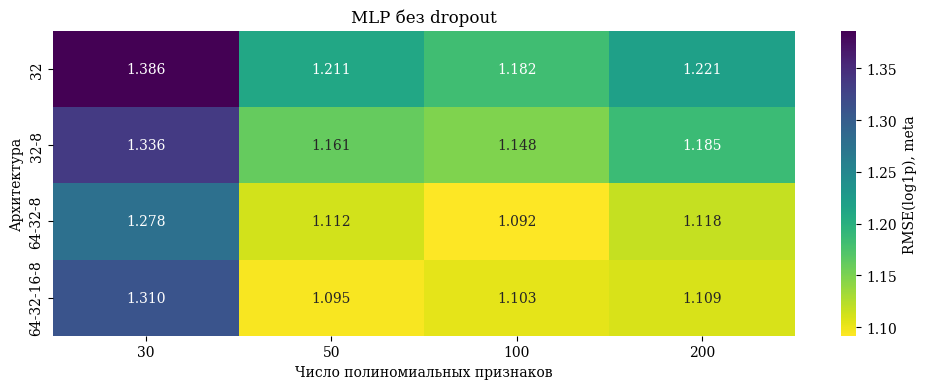

,k,architecture,hidden_layers,dropout,rmse_fit,rmse_meta
0,100,64-32-8,"(64, 32, 8)",0.0,0.930430,1.091693
1,50,64-32-16-8,"(64, 32, 16, 8)",0.0,0.918329,1.094670
2,100,64-32-16-8,"(64, 32, 16, 8)",0.0,0.938960,1.103346
3,200,64-32-16-8,"(64, 32, 16, 8)",0.0,0.919088,1.109163
4,50,64-32-8,"(64, 32, 8)",0.0,0.934919,1.111757
5,200,64-32-8,"(64, 32, 8)",0.0,0.912892,1.118088
6,100,32-8,"(32, 8)",0.0,0.994692,1.148477
7,50,32-8,"(32, 8)",0.0,1.017479,1.161151
8,100,32,"(32,)",0.0,1.039459,1.182219
9,200,32-8,"(32, 8)",0.0,1.005943,1.185027


In [ ]:
mlp_grid = []
mlp_best = None
mlp_best_model = None

for k in MLP_K_VALUES:
    for architecture in MLP_ARCHITECTURES:
        result, model = fit_mlp(
            k=k,
            hidden_layers=architecture,
            dropout=0.0,
        )

        mlp_grid.append(result)

        if (
            mlp_best is None
            or result["rmse_meta"] < mlp_best["rmse_meta"]
        ):
            mlp_best = result
            mlp_best_model = model

        del model

mlp_comparison = (
    pd.DataFrame(mlp_grid)
    .sort_values("rmse_meta")
    .reset_index(drop=True)
)

heatmap = mlp_comparison.pivot(
    index="architecture",
    columns="k",
    values="rmse_meta",
).reindex(
    index=[
        "-".join(map(str, architecture))
        for architecture in MLP_ARCHITECTURES
    ],
    columns=MLP_K_VALUES,
)

plt.figure(figsize=(10, 4))
sns.heatmap(
    heatmap,
    annot=True,
    fmt=".3f",
    cmap="viridis_r",
    cbar_kws={"label": "RMSE(log1p), meta"},
)
plt.xlabel("Число полиномиальных признаков")
plt.ylabel("Архитектура")
plt.title("MLP без dropout")
plt.tight_layout()
plt.show()

display(mlp_comparison)

In [ ]:
top_configs = mlp_comparison.head(3).to_dict("records")
dropout_rows = []

for config in top_configs:
    for dropout in MLP_DROPOUTS:
        result, model = fit_mlp(
            k=int(config["k"]),
            hidden_layers=config["hidden_layers"],
            dropout=dropout,
        )

        dropout_rows.append(result)

        if result["rmse_meta"] < mlp_best["rmse_meta"]:
            mlp_best = result
            mlp_best_model = model

        del model

mlp_dropout_comparison = (
    pd.DataFrame(dropout_rows)
    .sort_values("rmse_meta")
    .reset_index(drop=True)
)

display(mlp_dropout_comparison)

# Оцениваем следующий месяц только после выбора конфигурации.
mlp_best_model = mlp_best_model.to(device)

mlp_final_predictions = np.maximum(
    mlp_predict(
        mlp_best_model,
        mlp_inputs("predict", mlp_best["k"]),
    ),
    0,
)

mlp_report = pd.DataFrame([{
    "k": mlp_best["k"],
    "architecture": mlp_best["architecture"],
    "dropout": mlp_best["dropout"],
    "RMSE(log1p), fit": mlp_best["rmse_fit"],
    "RMSE(log1p), meta": mlp_best["rmse_meta"],
    "RMSE(log1p), predict": mlp_rmse(
        mlp_y["predict"],
        mlp_final_predictions,
    ),
}])

display(mlp_report)
mlp_best_model = mlp_best_model.cpu()

k=100, layers=64-32-8, dropout=0.1: RMSE(meta)=1.12081
k=100, layers=64-32-8, dropout=0.25: RMSE(meta)=1.21059
k=100, layers=64-32-8, dropout=0.4: RMSE(meta)=1.43302
k=50, layers=64-32-16-8, dropout=0.1: RMSE(meta)=1.09253
k=50, layers=64-32-16-8, dropout=0.25: RMSE(meta)=1.14878
k=50, layers=64-32-16-8, dropout=0.4: RMSE(meta)=1.38954
k=100, layers=64-32-16-8, dropout=0.1: RMSE(meta)=1.13020
k=100, layers=64-32-16-8, dropout=0.25: RMSE(meta)=1.27666
k=100, layers=64-32-16-8, dropout=0.4: RMSE(meta)=1.51089


,k,architecture,hidden_layers,dropout,rmse_fit,rmse_meta
0,50,64-32-16-8,"(64, 32, 16, 8)",0.10,0.949506,1.092534
1,100,64-32-8,"(64, 32, 8)",0.10,0.977678,1.120808
2,100,64-32-16-8,"(64, 32, 16, 8)",0.10,0.990009,1.130203
3,50,64-32-16-8,"(64, 32, 16, 8)",0.25,1.034073,1.148784
4,100,64-32-8,"(64, 32, 8)",0.25,1.102627,1.210594
5,100,64-32-16-8,"(64, 32, 16, 8)",0.25,1.137649,1.276661
6,50,64-32-16-8,"(64, 32, 16, 8)",0.40,1.284256,1.389537
7,100,64-32-8,"(64, 32, 8)",0.40,1.345176,1.433019
8,100,64-32-16-8,"(64, 32, 16, 8)",0.40,1.399184,1.510894


,k,architecture,dropout,"RMSE(log1p), fit","RMSE(log1p), meta","RMSE(log1p), predict"
0,100,64-32-8,0.0,0.93043,1.091693,1.133389


In [ ]:
# import json
# import joblib
# import torch
# from pathlib import Path

# ART = Path("artifacts"); ART.mkdir(exist_ok=True)

# # Сеть: только веса, архитектуру восстановим по mlp_best.
# torch.save(mlp_best_model.cpu().state_dict(), ART / "mlp_best.pt")

# joblib.dump({
#     "mlp_best": mlp_best,
#     "mlp_periods": mlp_periods,
#     "mlp_numeric": mlp_numeric,
#     "mlp_categories": mlp_categories,
#     "mlp_scaler": mlp_scaler,
#     "mlp_poly": mlp_poly,
#     "mlp_order": mlp_order,
#     "mlp_poly_scaler": mlp_poly_scaler,
#     "mlp_encoder": mlp_encoder,
#     "mlp_comparison": mlp_comparison,
#     "mlp_dropout_comparison": mlp_dropout_comparison,
# }, ART / "mlp_results.joblib")


['artifacts/mlp_results.joblib']

### Возобновление: старт с сохранённого состояния

Блок для чистого ядра: после четырёх ячеек ниже можно сразу запускать подбор гиперпараметров и стэкинг пяти моделей, не выполняя ничего выше. Всё читается из `artifacts/` — это файлы, которые пишут ячейки сохранения после стэкинга бустингов и после MLP.

1. Загрузка `train_full`, настроек и прогнозов бустингов (`global_base_predictions`, `base_predictions` и другие).
2. Константы бустингов и `cyclic_numeric_batch` — копии из верхних ячеек, которые без `poly_numeric` и `train_part` не выполнить.
3. Функции бустингов и `boosting_data`. Определения берутся из ячеек раздела бустингов по их id, поэтому второй копии кода нет; затем сверяется, что строки августа и сентября те же, для которых сохранены прогнозы.
4. Лучшая MLP и её преобразования.

Если ячейки выше только что выполнены в этом же ядре, блок не нужен: он заменит результаты в памяти сохранёнными (даты файлов печатаются при загрузке). `test` здесь не загружается — он нужен только разделу с тестом.

Чтобы перейти к стэкингу без нового подбора, выполните только первую ячейку раздела подбора (`tune_grouped_booster`, `tuned_group_predictions`): параметры возьмутся из `best_params_*.json`.

In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
import lightgbm, catboost
from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

ART = Path("artifacts")

# Даты файлов: по ним видно, насколько свежее сохранённое состояние.
for file_name in [
    "train_full.parquet", "boosting_config.joblib",
    "boosting_results.joblib", "mlp_results.joblib", "mlp_best.pt",
]:
    saved_at = pd.Timestamp.fromtimestamp(
        (ART / file_name).stat().st_mtime
    )
    print(f"{saved_at:%d.%m %H:%M}  {file_name}")

train_full = pd.read_parquet(ART / "train_full.parquet")
print("train_full:", train_full.shape)

# Настройки и прогнозы бустингов: каждое имя из файла становится переменной.
for file_name in ["boosting_config.joblib", "boosting_results.joblib"]:
    state = joblib.load(ART / file_name)
    globals().update(state)
    print(f"{file_name}: {', '.join(state)}")

12.10 21:03  train_full.parquet
12.10 21:03  boosting_config.joblib
12.10 21:03  boosting_results.joblib
12.10 19:30  mlp_results.joblib
12.10 19:30  mlp_best.pt
train_full: (20216100, 16)
boosting_config.joblib: numeric_columns_cyclic, cyclic_columns, categorical_columns, BEST_FEATURES, BEST_POWERS, LGBM_PARAMS, CATBOOST_PARAMS, BOOSTING_MAX_ROWS, boosting_scaler, boosting_category_maps, y_meta, y_predict
boosting_results.joblib: global_base_predictions, lgbm_group_predictions, lgbm_group_stats, grouping_comparison, best_groupings, base_predictions, base_summary, stack_weights, meta_model


In [ ]:
# Константы из ячейки настроек бустингов: целиком её не выполнить без poly_numeric.
# Эту ячейку по id выполняет и блок возобновления перед тестом.
BOOSTING_BATCH_SIZE = 50_000
BOOSTING_CATEGORICAL = categorical_columns.copy()
GROUPINGS = {
    "meter": ["meter"],
    "site_id + meter": ["site_id", "meter"],
    "site_id + primary_use + meter": ["site_id", "primary_use", "meter"],
    "building_id + meter": ["building_id", "meter"],
}
BAD_SITE0_END = (
    pd.Timestamp("2016-01-01") + pd.Timedelta(hours=3378)
)


def cyclic_numeric_batch(frame):
    # Копия функции из эксперимента 2: та ячейка требует train_part.
    result = frame[numeric_columns_cyclic].astype(np.float32).fillna(0)
    angle = frame["timestamp"].dt.hour.to_numpy(dtype=np.float32)
    angle *= np.float32(2 * np.pi / 24)
    result["hour_sin"], result["hour_cos"] = np.sin(angle), np.cos(angle)
    if "wind_direction" in frame:
        angle = frame["wind_direction"].to_numpy(dtype=np.float32, copy=True)
        np.deg2rad(angle, out=angle)
        result["wind_direction_sin"] = np.sin(angle)
        result["wind_direction_cos"] = np.cos(angle)
    else:
        result[["wind_direction_sin", "wind_direction_cos"]] = frame[
            ["wind_direction_sin", "wind_direction_cos"]
        ]
    return result.fillna(0).to_numpy(dtype=np.float32)

In [ ]:
# Определения берём из ячеек раздела бустингов по id, чтобы не держать вторую копию кода.
# Читается сохранённый файл: сохраните ноутбук, если меняли эти ячейки.
RESUME_CELLS = {
    "77f0fdc2": "BOOSTING_FOLDS",
    "6e5ba85e": "take_period, make_boosting_features",
    "63359796": "prepare_boosting_fold и сборка boosting_data",
    "34d14645": "global_predictions, grouped_predictions, "
                "run_grouped_booster, fit_boosting_stack",
}

with open("research.ipynb", "r", encoding="utf-8") as file:
    notebook_cells = {
        cell.get("id"): "".join(cell["source"])
        for cell in json.load(file)["cells"]
    }

for cell_id, content in RESUME_CELLS.items():
    if cell_id not in notebook_cells:
        raise KeyError(f"В ноутбуке нет ячейки {cell_id} ({content})")

    exec(
        compile(notebook_cells[cell_id], f"<ячейка {cell_id}>", "exec"),
        globals(),
    )

del notebook_cells

# Прогнозы сохранены для конкретных строк августа и сентября: сверяем их.
for name, saved_y in [("meta", y_meta), ("predict", y_predict)]:
    if not np.array_equal(boosting_data[name]["y"], saved_y):
        raise ValueError(
            f"Строки {name} не совпадают с сохранёнными прогнозами: "
            "пересохраните артефакты"
        )

print("Состояние бустингов восстановлено")

,period,rows,features,MB,start,end
0,fit,1000000,18,68.664677,2016-01-01,2016-07-31 23:00:00
1,meta,200000,18,13.733036,2016-08-01,2016-08-31 23:00:00
2,predict,200000,18,13.733036,2016-09-01,2016-09-30 23:00:00


Состояние бустингов восстановлено


In [ ]:
import joblib
import torch
from torch import nn
from scipy import sparse

# LightGBM и PyTorch на macOS используют разные копии OpenMP: после import lightgbm
# многопоточные операции PyTorch на CPU роняют ядро, поэтому оставляем один поток.
torch.set_num_threads(1)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

globals().update(joblib.load(ART / "mlp_results.joblib"))

# Те же константы, что в ячейке настроек MLP.
MLP_BATCH_SIZE = 1024
MLP_K_VALUES = [30, 50, 100, 200]


def mlp_numeric_inputs(frame):
    return frame[mlp_numeric].fillna(0).to_numpy(dtype=np.float32)


def mlp_category_inputs(frame):
    return frame[mlp_categories].astype("string").fillna("__MISSING__")


def mlp_features(frame, polynomial):
    hour = frame["timestamp"].dt.hour.to_numpy() * (2 * np.pi / 24)
    wind = np.deg2rad(frame["wind_direction"].fillna(0).to_numpy())
    cyclic = np.column_stack([
        np.sin(hour), np.cos(hour), np.sin(wind), np.cos(wind),
    ])
    return sparse.hstack(
        [
            mlp_poly_scaler.transform(polynomial[:, mlp_order]),
            cyclic,
            mlp_encoder.transform(mlp_category_inputs(frame)),
        ],
        format="csr",
        dtype=np.float32,
    )


def mlp_predict(model, features):
    model.eval()
    model_device = next(model.parameters()).device
    predictions = []

    with torch.inference_mode():
        for start in range(0, features.shape[0], MLP_BATCH_SIZE):
            batch = features[start:start + MLP_BATCH_SIZE].toarray()
            X_batch = torch.from_numpy(batch).to(
                device=model_device, dtype=torch.float32
            )
            predictions.append(model(X_batch).squeeze(1).cpu().numpy())

    return np.concatenate(predictions)


# Сеть восстанавливаем по mlp_best и сохранённым весам.
state = torch.load(ART / "mlp_best.pt", map_location="cpu")
widths = [state["0.weight"].shape[1], *mlp_best["hidden_layers"]]
layers = []

for input_width, output_width in zip(widths[:-1], widths[1:]):
    layers.extend([
        nn.Linear(input_width, output_width),
        nn.ReLU(),
        nn.Dropout(mlp_best["dropout"]),
    ])

layers.append(nn.Linear(widths[-1], 1))
mlp_best_model = nn.Sequential(*layers)
mlp_best_model.load_state_dict(state)
mlp_best_model.eval()

print("MLP:", mlp_best["k"], mlp_best["architecture"], mlp_best["dropout"])


MLP: 100 64-32-8 0.0


### Подбор гиперпараметров: LightGBM и CatBoost на site_id + meter

Подбираем общие для всех локальных моделей гиперпараметры на группировке `site_id + meter`. Признаки, разбиение и запуск те же, что выше: `boosting_data` (январь–июль → август → сентябрь), `run_grouped_booster`, fallback — общая модель с базовыми параметрами.

Вариант 0 — текущие `LGBM_PARAMS` / `CATBOOST_PARAMS`, остальные — случайные точки сетки (`ParameterSampler`, фиксированный seed), поэтому на августе результат перебора не хуже базового. Лучший вариант выбираем по RMSE августа (`rmse_meta`); сентябрь выводим для контроля, в выборе он не участвует. Лучшие параметры сразу пишутся в `best_params_<алгоритм>.json`, а прогнозы лучшего варианта остаются в `tuned_group_predictions` для стэкинга.

Каждый вариант — полное обучение 39 локальных моделей, а крупные варианты в несколько раз дольше базового. Ускорить можно числом вариантов (`LGBM_TRIALS`, `CATBOOST_TRIALS`) или ограничением `BOOSTING_MAX_ROWS["fit"]` с пересборкой `boosting_data`.

API: [ParameterSampler](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ParameterSampler.html), [параметры LightGBM](https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html), [параметры CatBoost](https://catboost.ai/docs/en/concepts/parameter-tuning).

In [ ]:
import json
from sklearn.model_selection import ParameterSampler

TUNING_GROUPING = "site_id + meter"

# Лучшие варианты перебора: стэкинг берёт их без повторного обучения.
tuned_group_predictions = {}


def tune_grouped_booster(kind, base_params, search_space, n_trials, seed=42):
    """Случайный перебор гиперпараметров локальных моделей TUNING_GROUPING."""
    # Вариант 0 — базовые параметры, остальные — случайные точки сетки.
    candidates = [{}] + list(
        ParameterSampler(search_space, n_iter=n_trials, random_state=seed)
    )

    name = f"{kind}: {TUNING_GROUPING}"
    rows, best_score = [], np.inf

    for trial, changes in enumerate(candidates):
        params = {**base_params, **changes}
        started = perf_counter()

        predictions, _ = run_grouped_booster(
            kind=kind,
            grouping=TUNING_GROUPING,
            data=boosting_data,
            params=params,
            fallback=global_base_predictions[kind],
        )

        row = {
            "trial": trial,
            "rmse_meta": rmse_log(
                boosting_data["meta"]["y"],
                predictions["meta"],
            ),
            "rmse_predict": rmse_log(
                boosting_data["predict"]["y"],
                predictions["predict"],
            ),
            "minutes": (perf_counter() - started) / 60,
            **changes,
        }
        rows.append(row)

        print(
            f"{kind}, вариант {trial}/{len(candidates) - 1}: "
            f"RMSE(meta)={row['rmse_meta']:.5f}, "
            f"RMSE(predict)={row['rmse_predict']:.5f}, "
            f"{row['minutes']:.1f} мин, "
            f"{changes or 'базовые параметры'}",
            flush=True,
        )

        # Выбираем только по августу; лучший вариант сразу сохраняем.
        if row["rmse_meta"] < best_score:
            best_score = row["rmse_meta"]
            tuned_group_predictions[name] = {
                "params": params,
                "predictions": predictions,
            }

            with open(
                f"best_params_{kind}.json", "w", encoding="utf-8"
            ) as file:
                json.dump(params, file, ensure_ascii=False, indent=2)

    return (
        pd.DataFrame(rows)
        .convert_dtypes()
        .sort_values("rmse_meta")
        .reset_index(drop=True)
    )

In [ ]:
LGBM_TRIALS = 15

LGBM_SEARCH_SPACE = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.03, 0.05, 0.1],
    "num_leaves": [31, 63, 127, 255],
    "min_child_samples": [20, 50, 100],
    "colsample_bytree": [0.7, 0.85, 1.0],
    # subsample работает только вместе с subsample_freq > 0.
    "subsample": [0.7, 1.0],
    "subsample_freq": [1],
    "reg_lambda": [0.0, 1.0, 10.0],
}

lgbm_search = tune_grouped_booster(
    kind="lightgbm",
    base_params=LGBM_PARAMS,
    search_space=LGBM_SEARCH_SPACE,
    n_trials=LGBM_TRIALS,
)

display(lgbm_search)

print(
    "Лучшие параметры LightGBM:",
    tuned_group_predictions[f"lightgbm: {TUNING_GROUPING}"]["params"],
)

lightgbm (site_id + meter): старт, 39 групп, параллельных задач: 2
lightgbm (site_id + meter): 10/39, моделей 10, пропущено 0, 2.0 с
lightgbm (site_id + meter): 20/39, моделей 20, пропущено 0, 3.1 с
lightgbm (site_id + meter): 30/39, моделей 30, пропущено 0, 4.1 с
lightgbm (site_id + meter): 39/39, моделей 39, пропущено 0, 5.0 с
lightgbm, вариант 0/15: RMSE(meta)=1.15444, RMSE(predict)=1.14723, 0.1 мин, базовые параметры
lightgbm (site_id + meter): старт, 39 групп, параллельных задач: 2
lightgbm (site_id + meter): 10/39, моделей 10, пропущено 0, 17.3 с
lightgbm (site_id + meter): 20/39, моделей 20, пропущено 0, 28.7 с
lightgbm (site_id + meter): 30/39, моделей 30, пропущено 0, 40.0 с
lightgbm (site_id + meter): 39/39, моделей 39, пропущено 0, 52.5 с
lightgbm, вариант 1/15: RMSE(meta)=1.15367, RMSE(predict)=1.17901, 0.9 мин, {'subsample_freq': 1, 'subsample': 0.7, 'reg_lambda': 10.0, 'num_leaves': 255, 'n_estimators': 400, 'min_child_samples': 20, 'learning_rate': 0.1, 'colsample_bytree

,trial,rmse_meta,rmse_predict,minutes,subsample_freq,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree
0,3,1.134336,1.150967,1.169694,1,0.7,1,255,600,100,0.03,0.85
1,8,1.13512,1.152939,0.589347,1,0.7,0,127,400,100,0.05,0.85
2,9,1.135163,1.157368,0.582861,1,0.7,0,63,600,50,0.05,1.0
3,14,1.135302,1.146309,0.756944,1,0.7,0,255,400,100,0.03,1.0
4,13,1.138356,1.159241,0.780536,1,0.7,0,255,400,50,0.05,0.7
5,12,1.139041,1.156005,0.304624,1,0.7,1,127,200,100,0.1,0.85
6,6,1.140343,1.158694,0.251298,1,1.0,1,127,200,20,0.1,0.85
7,7,1.14076,1.164385,1.166293,1,0.7,1,255,600,100,0.05,1.0
8,15,1.141467,1.137707,0.276064,1,1.0,1,127,200,50,0.03,0.7
9,2,1.141604,1.143923,0.394436,1,1.0,0,255,200,100,0.03,1.0


Лучшие параметры LightGBM: {'objective': 'regression', 'n_estimators': 600, 'random_state': 42, 'verbosity': -1, 'n_jobs': 2, 'subsample_freq': 1, 'subsample': 0.7, 'reg_lambda': 1.0, 'num_leaves': 255, 'min_child_samples': 100, 'learning_rate': 0.03, 'colsample_bytree': 0.85}


In [ ]:
CATBOOST_TRIALS = 8

CATBOOST_SEARCH_SPACE = {
    "iterations": [200, 400, 600],
    "learning_rate": [0.05, 0.1, 0.2],
    "depth": [4, 6, 8, 10],
    "l2_leaf_reg": [1.0, 3.0, 10.0],
    "random_strength": [0.0, 1.0],
    "rsm": [0.7, 1.0],
    # 255: категории до 255 значений (здания площадки) кодируются One-Hot.
    "one_hot_max_size": [2, 255],
}

catboost_search = tune_grouped_booster(
    kind="catboost",
    base_params=CATBOOST_PARAMS,
    search_space=CATBOOST_SEARCH_SPACE,
    n_trials=CATBOOST_TRIALS,
)

display(catboost_search)

print(
    "Лучшие параметры CatBoost:",
    tuned_group_predictions[f"catboost: {TUNING_GROUPING}"]["params"],
)

catboost (site_id + meter): старт, 39 групп, параллельных задач: 1
catboost (site_id + meter): 10/39, моделей 10, пропущено 0, 5.6 с
catboost (site_id + meter): 20/39, моделей 20, пропущено 0, 9.2 с
catboost (site_id + meter): 30/39, моделей 30, пропущено 0, 13.0 с
catboost (site_id + meter): 39/39, моделей 39, пропущено 0, 16.5 с
catboost, вариант 0/8: RMSE(meta)=1.17414, RMSE(predict)=1.16255, 0.3 мин, базовые параметры
catboost (site_id + meter): старт, 39 групп, параллельных задач: 1
catboost (site_id + meter): 10/39, моделей 10, пропущено 0, 10.8 с
catboost (site_id + meter): 20/39, моделей 20, пропущено 0, 16.1 с
catboost (site_id + meter): 30/39, моделей 30, пропущено 0, 21.4 с
catboost (site_id + meter): 39/39, моделей 39, пропущено 0, 26.3 с
catboost, вариант 1/8: RMSE(meta)=1.25569, RMSE(predict)=1.19177, 0.4 мин, {'rsm': 0.7, 'random_strength': 1.0, 'one_hot_max_size': 255, 'learning_rate': 0.05, 'l2_leaf_reg': 3.0, 'iterations': 400, 'depth': 4}
catboost (site_id + meter): 

,trial,rmse_meta,rmse_predict,minutes,rsm,random_strength,one_hot_max_size,learning_rate,l2_leaf_reg,iterations,depth
0,3,1.135634,1.151342,3.496343,0.7,0,255,0.2,10,600,10
1,0,1.17414,1.162547,0.274867,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,7,1.196703,1.153605,0.993486,0.7,0,255,0.05,10,200,10
3,8,1.201083,1.16668,0.196389,0.7,0,255,0.2,1,200,4
4,2,1.202129,1.159614,0.874131,1.0,1,2,0.05,1,200,8
5,6,1.202142,1.16236,0.197665,1.0,1,255,0.2,10,200,4
6,5,1.205138,1.170802,0.624818,0.7,1,2,0.1,3,400,4
7,1,1.255685,1.191772,0.43765,0.7,1,255,0.05,3,400,4
8,4,1.268208,1.200832,0.349571,0.7,1,255,0.05,10,200,6


Лучшие параметры CatBoost: {'loss_function': 'RMSE', 'iterations': 600, 'random_seed': 42, 'verbose': False, 'allow_writing_files': False, 'thread_count': 2, 'max_ctr_complexity': 1, 'rsm': 0.7, 'random_strength': 0.0, 'one_hot_max_size': 255, 'learning_rate': 0.2, 'l2_leaf_reg': 10.0, 'depth': 10}


### Стэкинг: бустинги на трёх группировках + MLP

Кандидаты стэка заданы списком `STACK_MODELS`: LightGBM и CatBoost на `site_id + meter` и на `site_id + primary_use + meter`, CatBoost на `building_id + meter` и лучшая MLP (`mlp_best_model`).

Что изменено относительно пяти моделей:

- LightGBM по зданиям убран: в прошлом стэке его вес был 0.
- CatBoost по зданиям и по `site_id + primary_use + meter` идёт только с базовыми параметрами. Подобранные (глубина 10, 600 итераций) искались для площадок; на ~2 350 маленьких группах они занимали большую часть времени.
- Добавлена группировка `site_id + primary_use + meter`: около 200 групп вместо ~2 350 зданий, в каждой больше строк.

Там, где вариантов параметров два, подобранные и базовые сравниваются по августу и берётся лучший. Затем метамодель обучается на всех кандидатах, и модели с весом ниже `STACK_MIN_WEIGHT` исключаются: на тесте они не обучаются.

У бустингов 18 признаков, у MLP — k полиномов + sin/cos + One-Hot, поэтому матрицы признаков не объединяем: каждая модель строит свои признаки из одних и тех же сырых строк, а метамодель видит только столбцы прогнозов. Прогнозы MLP пересчитываем батчами для строк `boosting_data` и сверяем совпадение по целевой переменной.

Метамодель — тот же `fit_boosting_stack`: Ridge с неотрицательными весами обучается на прогнозах августа и проверяется на сентябре. Варианты параметров и состав стэка выбраны по августу. Группировки по площадкам и зданиям выбраны выше по сентябрю, поэтому сентябрь — не полностью независимая оценка.

In [ ]:
DEFAULT_BOOSTING_PARAMS = {
    "lightgbm": LGBM_PARAMS,
    "catboost": CATBOOST_PARAMS,
}
BEST_BOOSTING_PARAMS = {}

for kind in DEFAULT_BOOSTING_PARAMS:
    with open(f"best_params_{kind}.json", "r", encoding="utf-8") as file:
        BEST_BOOSTING_PARAMS[kind] = json.load(file)

# Кандидаты стэка: алгоритм, группировка, варианты параметров.
# По зданиям — только CatBoost с базовыми параметрами (см. текст выше).
# CatBoost на site_id + primary_use + meter тоже базовый: подобранный давал
# на августе 1.142 против 1.157, но обучался 8.1 мин против 0.4 мин.
STACK_MODELS = [
    ("lightgbm", "site_id + meter", ["подобранные", "базовые"]),
    ("catboost", "site_id + meter", ["подобранные", "базовые"]),
    ("lightgbm", "site_id + primary_use + meter", ["подобранные", "базовые"]),
    ("catboost", "site_id + primary_use + meter", ["базовые"]),
    ("catboost", "building_id + meter", ["базовые"]),
]

# Обученные здесь варианты: повторный запуск ячейки их не пересчитывает.
if "stack_variant_predictions" not in globals():
    stack_variant_predictions = {}


def stack_variant(kind, grouping, variant):
    """Параметры, прогнозы и минуты обучения одного варианта."""
    name = f"{kind}: {grouping}"
    tuned = variant == "подобранные"
    params = (
        BEST_BOOSTING_PARAMS[kind] if tuned
        else DEFAULT_BOOSTING_PARAMS[kind]
    )

    # Готовые прогнозы: лучший вариант подбора и базовые модели выше.
    ready = tuned_group_predictions.get(name) if tuned else None

    if ready is not None and ready["params"] == params:
        return params, ready["predictions"], np.nan

    if not tuned and name in base_predictions:
        return params, base_predictions[name], np.nan

    cached = stack_variant_predictions.get((name, variant))

    if cached is None or cached["params"] != params:
        started = perf_counter()

        predictions, _ = run_grouped_booster(
            kind=kind,
            grouping=grouping,
            data=boosting_data,
            params=params,
            fallback=global_base_predictions[kind],
        )

        cached = stack_variant_predictions[(name, variant)] = {
            "params": dict(params),
            "predictions": predictions,
            "minutes": (perf_counter() - started) / 60,
        }

    return params, cached["predictions"], cached["minutes"]


stack5_predictions, stack5_params, stack5_candidates = {}, {}, []

for kind, grouping, variants in STACK_MODELS:
    name = f"{kind}: {grouping}"

    candidates = {
        variant: stack_variant(kind, grouping, variant)
        for variant in variants
    }

    scores = {
        variant: rmse_log(
            boosting_data["meta"]["y"],
            predictions["meta"],
        )
        for variant, (_, predictions, _) in candidates.items()
    }

    # Вариант выбираем только по августу.
    best_variant = min(scores, key=scores.get)
    stack5_params[name], stack5_predictions[name], _ = candidates[best_variant]

    for variant, (_, predictions, minutes) in candidates.items():
        stack5_candidates.append({
            "model": name,
            "params": variant,
            "rmse_meta": scores[variant],
            "rmse_predict": rmse_log(
                boosting_data["predict"]["y"],
                predictions["predict"],
            ),
            "minutes": minutes,
            "selected": variant == best_variant,
        })

display(pd.DataFrame(stack5_candidates))

In [ ]:
# Масштабированные числовые признаки MLP ограничиваем: кубы выбросов погоды
# давали на тесте прогнозы до 1e84.
MLP_INPUT_CLIP = 5.0


def mlp_predict_frame(model, frame, k, batch_rows=BOOSTING_BATCH_SIZE):
    """Прогноз MLP по сырым строкам: признаки MLP строим батчами."""
    predictions = np.empty(len(frame), dtype=np.float64)

    for start in range(0, len(frame), batch_rows):
        batch = frame.iloc[start:start + batch_rows]

        polynomial = mlp_poly.transform(
            np.clip(
                mlp_scaler.transform(mlp_numeric_inputs(batch)),
                -MLP_INPUT_CLIP, MLP_INPUT_CLIP,
            )
        )
        features = mlp_features(batch, polynomial)

        # Как в mlp_inputs: первые k полиномов + все sin/cos и One-Hot.
        columns = np.r_[
            np.arange(k),
            np.arange(len(mlp_order), features.shape[1]),
        ]

        predictions[start:start + len(batch)] = mlp_predict(
            model,
            features[:, columns],
        )

    return np.maximum(predictions, 0)

In [ ]:
mlp_best_model = mlp_best_model.to(device)
mlp_stack_predictions = {}

for name in ["meta", "predict"]:
    # Те же строки, что в boosting_data: полный период вместо выборки MLP.
    frame = take_period(
        train_full,
        *mlp_periods[name],
        max_rows=BOOSTING_MAX_ROWS[name],
    )

    target = np.log1p(
        frame["meter_reading"].to_numpy(dtype=np.float64)
    )

    if not np.array_equal(target, boosting_data[name]["y"]):
        raise ValueError(
            f"Строки MLP и бустингов не совпадают: {name}"
        )

    mlp_stack_predictions[name] = mlp_predict_frame(
        mlp_best_model,
        frame,
        mlp_best["k"],
    )

    print(
        f"MLP, {name}: {len(frame)} строк, "
        f"RMSE={rmse_log(target, mlp_stack_predictions[name]):.5f}",
        flush=True,
    )

    del frame, target

mlp_best_model = mlp_best_model.cpu()
stack5_predictions["MLP"] = mlp_stack_predictions

MLP, meta: 200000 строк, RMSE=1.09807
MLP, predict: 200000 строк, RMSE=1.13742


In [ ]:
# Модели с весом ниже порога в стэк не входят и на тесте не обучаются.
STACK_MIN_WEIGHT = 0.02

_, candidate_weights, _ = fit_boosting_stack(
    stack5_predictions,
    boosting_data,
)
display(candidate_weights.rename("weight_all_candidates"))

for name in candidate_weights.index[candidate_weights < STACK_MIN_WEIGHT]:
    del stack5_predictions[name]
    stack5_params.pop(name, None)
    print("Исключена из стэка:", name)

# Порядок столбцов метамодели; он же нужен для теста.
stack5_names = list(stack5_predictions)

stack5_final, stack5_weights, stack5_meta_model = fit_boosting_stack(
    stack5_predictions,
    boosting_data,
)

stack5_meta = np.maximum(
    stack5_meta_model.predict(
        np.column_stack([
            stack5_predictions[name]["meta"]
            for name in stack5_names
        ])
    ),
    0,
)

comparison_rows = [
    {
        "model": name,
        "RMSE(log1p), meta": rmse_log(
            boosting_data["meta"]["y"],
            predictions["meta"],
        ),
        "RMSE(log1p), predict": rmse_log(
            boosting_data["predict"]["y"],
            predictions["predict"],
        ),
    }
    for name, predictions in stack5_predictions.items()
]

# Ошибка стэкинга на meta — внутривыборочная, честная оценка — predict.
comparison_rows.append({
    "model": f"Stacking: моделей — {len(stack5_names)}",
    "RMSE(log1p), meta": rmse_log(
        boosting_data["meta"]["y"],
        stack5_meta,
    ),
    "RMSE(log1p), predict": rmse_log(
        boosting_data["predict"]["y"],
        stack5_final,
    ),
})

stack5_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("RMSE(log1p), predict")
    .reset_index(drop=True)
)

display(stack5_comparison)
display(stack5_weights)
print(f"Свободный член: {stack5_meta_model.intercept_:.5f}")

### Валидация блоками месяцев: подбор, MLP и веса стэка

Схема «январь–июль → август → сентябрь» выше оценивает только следующий месяц и даёт около 1.00, тогда как на Kaggle (2017–2018) получается около 1.34. Здесь год делится на три блока по четыре месяца (`CV_BLOCKS`): модель обучается на двух блоках и прогнозирует третий, то есть сезон, которого не видела. На общей LightGBM такая проверка даёт 1.25–1.31 — заметно ближе к Kaggle.

Что считается на каждом шаге:

- **Строки.** `fit` — выборка из двух блоков без сбоя site 0 и без `constant_run`. Третий блок (без сбоя site 0) делится случайно пополам: на `meta` выбираются параметры и обучается метамодель, `predict` — оценка.
- **Бустинги.** Для `site_id + meter` перебираются базовые параметры, прежние подобранные и `CV_TRIALS` случайных точек сетки; лучший вариант выбирается по `meta` всех трёх блоков. CatBoost по зданиям — только базовый, как раньше. CatBoost на `site_id + primary_use + meter` убран: в двух прошлых стэках его вес был ниже порога.
- **MLP.** Конфигурация прежняя (`mlp_best`), но сеть обучается заново на каждом шаге и на `CV_MLP_ROWS` строк вместо 100 тысяч. Масштабированные числовые признаки ограничены `MLP_INPUT_CLIP`: без этого кубы выбросов погоды давали на тесте прогнозы до 1e84.
- **Стэк.** Ridge с неотрицательными весами обучается на `meta` трёх блоков (весь год, а не один август). Результат записывается в те же переменные `stack5_*`, поэтому сохранение и тест ниже не меняются.

Прогнозы каждого шага пишутся в `artifacts/cv_parts/`: после сбоя ядра выполните блок «Возобновление», ячейку `mlp_predict_frame` и снова эти ячейки — посчитанное возьмётся с диска. Финальная MLP для теста обучается на всём годе и заменяет `artifacts/mlp_best.pt` и `mlp_results.joblib`.

In [ ]:
import hashlib
import json
import joblib
from pathlib import Path
from sklearn.model_selection import ParameterSampler

CV_BLOCKS = [
    (pd.Timestamp("2016-01-01"), pd.Timestamp("2016-05-01")),
    (pd.Timestamp("2016-05-01"), pd.Timestamp("2016-09-01")),
    (pd.Timestamp("2016-09-01"), pd.Timestamp("2017-01-01")),
]
CV_MAX_ROWS = {"fit": 1_000_000, "evaluation": 400_000}
CV_EVALUATION = ["meta", "predict"]
CV_THREADS = 4
CV_PARTS = Path("artifacts") / "cv_parts"
CV_PARTS.mkdir(parents=True, exist_ok=True)


def site0_failure(df):
    return (
        (df["site_id"] == 0)
        & (df["meter"] == 0)
        & (df["timestamp"] < BAD_SITE0_END)
    )


def cv_fold_frames(fold):
    """Сырые строки шага: fit — два блока, meta и predict — половины третьего."""
    start, stop = CV_BLOCKS[fold]
    held_out = (
        (train_full["timestamp"] >= start)
        & (train_full["timestamp"] < stop)
    )
    failure = site0_failure(train_full)

    fit = take_period(
        train_full, CV_BLOCKS[0][0], CV_BLOCKS[-1][1],
        max_rows=CV_MAX_ROWS["fit"],
        exclude=held_out | failure | train_full["constant_run"],
    )
    evaluation = take_period(
        train_full, start, stop,
        max_rows=CV_MAX_ROWS["evaluation"],
        exclude=failure,
    )

    # Случайные половины блока; зерно зависит только от шага, поэтому
    # бустинги и MLP получают одни и те же строки.
    is_meta = (
        np.random.default_rng(fold).permutation(len(evaluation))
        < len(evaluation) // 2
    )

    return {
        "fit": fit,
        "meta": evaluation[is_meta].reset_index(drop=True),
        "predict": evaluation[~is_meta].reset_index(drop=True),
    }


def cv_target(frame):
    return np.log1p(frame["meter_reading"].to_numpy(dtype=np.float64))


def cv_fold_data(frames):
    """Признаки бустингов шага: scaler и коды категорий — только по fit."""
    fit = frames["fit"]
    scaler = StandardScaler()

    for start in range(0, len(fit), BOOSTING_BATCH_SIZE):
        scaler.partial_fit(
            cyclic_numeric_batch(fit.iloc[start:start + BOOSTING_BATCH_SIZE])
        )

    category_maps = {
        column: {
            value: i
            for i, value in enumerate(fit[column].dropna().unique())
        }
        for column in BOOSTING_CATEGORICAL
    }

    return {
        name: {
            "X": make_boosting_features(frame, scaler, category_maps),
            "y": cv_target(frame),
            "groups": frame[
                ["meter", "site_id", "building_id", "primary_use"]
            ].copy(),
        }
        for name, frame in frames.items()
    }


def cv_cached(key, compute):
    """Результат шага с диска или расчёт с записью на диск."""
    digest = hashlib.sha1(
        json.dumps(key, ensure_ascii=False, sort_keys=True, default=str)
        .encode("utf-8")
    ).hexdigest()[:16]
    path = CV_PARTS / f"{digest}.joblib"

    if path.exists():
        return joblib.load(path)

    result = compute()

    # Сначала временный файл: сбой во время записи не оставит обрезанный.
    temporary_path = path.with_suffix(".tmp")
    joblib.dump(result, temporary_path)
    temporary_path.replace(path)

    return result


def cv_concat(per_fold):
    """Склеивает прогнозы или цели шагов в порядке блоков."""
    return {
        name: np.concatenate([
            per_fold[fold][name] for fold in range(len(CV_BLOCKS))
        ])
        for name in CV_EVALUATION
    }


display(pd.DataFrame([
    {"шаг": fold, "прогнозируемый блок": f"{start:%d.%m} — {stop:%d.%m}"}
    for fold, (start, stop) in enumerate(CV_BLOCKS)
]))

   шаг прогнозируемый блок
0    0       01.01 — 01.05
1    1       01.05 — 01.09
2    2       01.09 — 01.01


In [ ]:
from threadpoolctl import threadpool_limits
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures

CV_MLP_ROWS = 300_000
CV_MLP_EPOCHS = 15


def fit_mlp_state(frame, config, seed=42):
    """Преобразования и сеть MLP по строкам frame для одной конфигурации.

    Те же шаги, что в разделе MLP. Преобразования записываются в глобальные
    имена: по ним mlp_features и mlp_predict_frame строят признаки.
    """
    rng = np.random.default_rng(seed)

    if len(frame) > CV_MLP_ROWS:
        frame = frame.iloc[
            np.sort(rng.choice(len(frame), size=CV_MLP_ROWS, replace=False))
        ]

    y = np.log1p(frame["meter_reading"].to_numpy(dtype=np.float32))

    scaler = StandardScaler()
    scaled = np.clip(
        scaler.fit_transform(mlp_numeric_inputs(frame)),
        -MLP_INPUT_CLIP, MLP_INPUT_CLIP,
    )
    poly = PolynomialFeatures(degree=3, include_bias=False)
    polynomial = poly.fit_transform(scaled)
    del scaled

    selector = SelectKBest(f_regression, k=max(MLP_K_VALUES))

    with threadpool_limits(limits=1, user_api="blas"):
        selector.fit(polynomial, y)

    # Порядок от наиболее высокой оценки к наиболее низкой.
    order = np.flatnonzero(selector.get_support())
    scores = np.nan_to_num(selector.scores_[order], nan=-np.inf)
    order = order[np.argsort(scores, kind="stable")[::-1]]

    state = {
        "mlp_scaler": scaler,
        "mlp_poly": poly,
        "mlp_order": order,
        "mlp_poly_scaler": StandardScaler().fit(polynomial[:, order]),
        "mlp_encoder": OneHotEncoder(
            handle_unknown="ignore", sparse_output=True, dtype=np.float32,
        ).fit(mlp_category_inputs(frame)),
    }
    globals().update(state)

    features = mlp_features(frame, polynomial)
    del polynomial

    # Как в mlp_inputs: первые k полиномов + все sin/cos и One-Hot.
    fit_X = features[:, np.r_[
        np.arange(config["k"]),
        np.arange(len(order), features.shape[1]),
    ]]
    del features

    torch.manual_seed(seed)
    widths = [fit_X.shape[1], *config["hidden_layers"]]
    layers = []

    for input_width, output_width in zip(widths[:-1], widths[1:]):
        layers.extend([
            nn.Linear(input_width, output_width),
            nn.ReLU(),
            nn.Dropout(config["dropout"]),
        ])

    layers.append(nn.Linear(widths[-1], 1))
    model = nn.Sequential(*layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    # Фиксированное число эпох, без early stopping.
    for epoch in range(CV_MLP_EPOCHS):
        model.train()
        order_rows = rng.permutation(len(y))

        for start in range(0, len(order_rows), MLP_BATCH_SIZE):
            rows = order_rows[start:start + MLP_BATCH_SIZE]

            X_batch = torch.from_numpy(
                fit_X[rows].toarray()
            ).to(device=device, dtype=torch.float32)
            y_batch = torch.from_numpy(
                y[rows]
            ).to(device=device, dtype=torch.float32)

            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(X_batch).squeeze(1), y_batch)
            loss.backward()
            optimizer.step()

    fit_rmse = rmse_log(y, np.maximum(mlp_predict(model, fit_X), 0))

    return state, model, fit_rmse


def cv_mlp_fold(fold):
    frames = cv_fold_frames(fold)
    started = perf_counter()
    _, model, fit_rmse = fit_mlp_state(frames["fit"], mlp_best)

    result = {
        name: mlp_predict_frame(model, frames[name], mlp_best["k"])
        for name in CV_EVALUATION
    }

    if not all(np.isfinite(pred).all() for pred in result.values()):
        raise ValueError("MLP выдала неконечные прогнозы")

    result["y"] = {name: cv_target(frames[name]) for name in CV_EVALUATION}
    result["rmse_fit"] = fit_rmse
    result["minutes"] = (perf_counter() - started) / 60
    return result


cv_mlp = {}

for fold in range(len(CV_BLOCKS)):
    cv_mlp[fold] = cv_cached(
        {
            "fold": fold, "blocks": CV_BLOCKS, "max_rows": CV_MAX_ROWS,
            "model": "MLP", "config": mlp_best["architecture"],
            "k": mlp_best["k"], "dropout": mlp_best["dropout"],
            "rows": CV_MLP_ROWS, "epochs": CV_MLP_EPOCHS,
            "clip": MLP_INPUT_CLIP, "train_rows": len(train_full),
            "constant_run_rows": int(train_full["constant_run"].sum()),
        },
        lambda: cv_mlp_fold(fold),
    )

    print(
        f"MLP, шаг {fold}: "
        f"RMSE(fit)={cv_mlp[fold]['rmse_fit']:.4f}, "
        + ", ".join(
            f"RMSE({name})="
            f"{rmse_log(cv_mlp[fold]['y'][name], cv_mlp[fold][name]):.4f}"
            for name in CV_EVALUATION
        )
        + f", {cv_mlp[fold]['minutes']:.1f} мин",
        flush=True,
    )

# Финальная MLP для теста: весь год, те же исключения, что у бустингов.
frame = take_period(
    train_full, CV_BLOCKS[0][0], CV_BLOCKS[-1][1],
    max_rows=CV_MLP_ROWS,
    exclude=site0_failure(train_full) | train_full["constant_run"],
)
mlp_state, mlp_best_model, fit_rmse = fit_mlp_state(frame, mlp_best)
mlp_best_model = mlp_best_model.cpu()

mlp_best = {
    **mlp_best,
    "rmse_fit": fit_rmse,
    # Ошибка на блоках, которых сеть не видела (meta трёх шагов).
    "rmse_meta": rmse_log(
        np.concatenate([cv_mlp[fold]["y"]["meta"] for fold in cv_mlp]),
        np.concatenate([cv_mlp[fold]["meta"] for fold in cv_mlp]),
    ),
    "rows": len(frame),
    "epochs": CV_MLP_EPOCHS,
    "input_clip": MLP_INPUT_CLIP,
}
del frame

torch.save(mlp_best_model.state_dict(), ART / "mlp_best.pt")
joblib.dump({
    "mlp_best": mlp_best,
    "mlp_periods": mlp_periods,
    "mlp_numeric": mlp_numeric,
    "mlp_categories": mlp_categories,
    **mlp_state,
}, ART / "mlp_results.joblib")

print(
    f"Финальная MLP: {mlp_best['rows']} строк, "
    f"RMSE(fit)={mlp_best['rmse_fit']:.4f}, "
    f"RMSE(блоки)={mlp_best['rmse_meta']:.4f}"
)

MLP, шаг 0: RMSE(fit)=0.8968, RMSE(meta)=1.1782, RMSE(predict)=1.1750, 0.4 мин
MLP, шаг 1: RMSE(fit)=0.8695, RMSE(meta)=1.1328, RMSE(predict)=1.1332, 0.4 мин
MLP, шаг 2: RMSE(fit)=0.8434, RMSE(meta)=1.1541, RMSE(predict)=1.1584, 0.4 мин
Финальная MLP: 300000 строк, RMSE(fit)=0.8895, RMSE(блоки)=1.1552


In [ ]:
DEFAULT_BOOSTING_PARAMS = {
    "lightgbm": LGBM_PARAMS,
    "catboost": CATBOOST_PARAMS,
}
CV_TRIALS = {"lightgbm": 8, "catboost": 5}

# Те же сетки, что в подборе на августе выше.
CV_SEARCH_SPACE = {
    "lightgbm": {
        "n_estimators": [200, 400, 600],
        "learning_rate": [0.03, 0.05, 0.1],
        "num_leaves": [31, 63, 127, 255],
        "min_child_samples": [20, 50, 100],
        "colsample_bytree": [0.7, 0.85, 1.0],
        # subsample работает только вместе с subsample_freq > 0.
        "subsample": [0.7, 1.0],
        "subsample_freq": [1],
        "reg_lambda": [0.0, 1.0, 10.0],
    },
    "catboost": {
        "iterations": [200, 400, 600],
        "learning_rate": [0.05, 0.1, 0.2],
        "depth": [4, 6, 8, 10],
        "l2_leaf_reg": [1.0, 3.0, 10.0],
        "random_strength": [0.0, 1.0],
        "rsm": [0.7, 1.0],
        # 255: категории до 255 значений (здания площадки) кодируются One-Hot.
        "one_hot_max_size": [2, 255],
    },
}

# Варианты параметров: базовые, прежние подобранные и случайные точки сетки.
cv_variants = {}

for kind, base_params in DEFAULT_BOOSTING_PARAMS.items():
    cv_variants[kind] = {"базовые": dict(base_params)}

    with open(f"best_params_{kind}.json", "r", encoding="utf-8") as file:
        cv_variants[kind]["прежние подобранные"] = json.load(file)

    for trial, changes in enumerate(
        ParameterSampler(
            CV_SEARCH_SPACE[kind], n_iter=CV_TRIALS[kind], random_state=42,
        ),
        1,
    ):
        cv_variants[kind][f"вариант {trial}"] = {**base_params, **changes}

# Кандидаты стэка: алгоритм, группировка, варианты параметров.
CV_MODELS = [
    ("lightgbm", "site_id + meter", list(cv_variants["lightgbm"])),
    ("catboost", "site_id + meter", list(cv_variants["catboost"])),
    ("lightgbm", "site_id + primary_use + meter",
     ["базовые", "прежние подобранные"]),
    ("catboost", "building_id + meter", ["базовые"]),
]

cv_predictions, cv_targets, cv_minutes = {}, {}, {}


def cv_group_model(kind, grouping, params, data, fallback):
    """Локальные модели одной группировки на одном шаге, как на тесте."""
    started = perf_counter()

    predictions, _ = grouped_predictions(
        kind=kind,
        X_fit=data["fit"]["X"],
        y_fit=data["fit"]["y"],
        groups_fit=data["fit"]["groups"],
        X_eval={name: data[name]["X"] for name in CV_EVALUATION},
        groups_eval={name: data[name]["groups"] for name in CV_EVALUATION},
        group_columns=GROUPINGS[grouping],
        params=(
            params if kind == "lightgbm"
            else {**params, "thread_count": CV_THREADS}
        ),
        fallback=fallback,
        min_group_rows=MIN_GROUP_ROWS,
        batch_size=BOOSTING_BATCH_SIZE,
        progress_every=0,
        n_workers=CV_THREADS if kind == "lightgbm" else 1,
    )

    predictions["minutes"] = (perf_counter() - started) / 60
    return predictions


def cv_run(models):
    """Считает кандидатов на всех шагах; готовое берёт из artifacts/cv_parts."""
    for fold in range(len(CV_BLOCKS)):
        data = cv_fold_data(cv_fold_frames(fold))
        cv_targets[fold] = {name: data[name]["y"] for name in CV_EVALUATION}

        # Ключ привязывает сохранённый прогноз к строкам, признакам и настройкам.
        fold_key = {
            "fold": fold, "blocks": CV_BLOCKS, "max_rows": CV_MAX_ROWS,
            "features": list(data["fit"]["X"].columns),
            "min_group_rows": MIN_GROUP_ROWS,
            "y": [float(data[name]["y"].sum()) for name in data],
        }

        # Общие модели с базовыми параметрами: fallback для малых групп.
        fallback = {
            kind: cv_cached(
                {**fold_key, "model": f"{kind}: global", "params": params},
                lambda: global_predictions(
                    kind=kind,
                    X_fit=data["fit"]["X"],
                    y_fit=data["fit"]["y"],
                    X_eval={
                        name: data[name]["X"] for name in CV_EVALUATION
                    },
                    params=params,
                    batch_size=BOOSTING_BATCH_SIZE,
                ),
            )
            for kind, params in DEFAULT_BOOSTING_PARAMS.items()
        }

        for kind, grouping, variants in models:
            name = f"{kind}: {grouping}"

            for variant in variants:
                params = cv_variants[kind][variant]

                predictions = cv_cached(
                    {**fold_key, "model": name, "params": params},
                    lambda: cv_group_model(
                        kind, grouping, params, data, fallback[kind],
                    ),
                )

                cv_predictions.setdefault((name, variant), {})[fold] = predictions
                cv_minutes.setdefault((name, variant), {})[fold] = (
                    predictions["minutes"]
                )

                print(
                    f"шаг {fold}, {name}, {variant}: "
                    f"RMSE(meta)="
                    f"{rmse_log(data['meta']['y'], predictions['meta']):.5f}, "
                    f"{predictions['minutes']:.1f} мин",
                    flush=True,
                )

        del data, fallback


def cv_variant_scores(name):
    """RMSE вариантов модели на meta всех шагов."""
    return {
        variant: rmse_log(cv_y["meta"], cv_concat(per_fold)["meta"])
        for (model, variant), per_fold in cv_predictions.items()
        if model == name
    }


cv_run(CV_MODELS)
cv_y = cv_concat(cv_targets)

# Лучшие параметры LightGBM для площадок проверяем и на site_id + primary_use + meter.
scores = cv_variant_scores("lightgbm: site_id + meter")
best_lightgbm = min(scores, key=scores.get)
print("Лучший вариант LightGBM на site_id + meter:", best_lightgbm)

if ("lightgbm: site_id + primary_use + meter", best_lightgbm) not in cv_predictions:
    cv_run([
        ("lightgbm", "site_id + primary_use + meter", [best_lightgbm]),
    ])

шаг 0, lightgbm: site_id + meter, базовые: RMSE(meta)=1.06731, 0.1 мин
шаг 0, lightgbm: site_id + meter, прежние подобранные: RMSE(meta)=1.06994, 1.1 мин
шаг 0, lightgbm: site_id + meter, вариант 1: RMSE(meta)=1.07778, 0.9 мин
шаг 0, lightgbm: site_id + meter, вариант 2: RMSE(meta)=1.08872, 0.4 мин
шаг 0, lightgbm: site_id + meter, вариант 3: RMSE(meta)=1.06994, 1.1 мин
шаг 0, lightgbm: site_id + meter, вариант 4: RMSE(meta)=1.08939, 1.2 мин
шаг 0, lightgbm: site_id + meter, вариант 5: RMSE(meta)=1.07236, 0.4 мин
шаг 0, lightgbm: site_id + meter, вариант 6: RMSE(meta)=1.07751, 0.3 мин
шаг 0, lightgbm: site_id + meter, вариант 7: RMSE(meta)=1.08371, 1.3 мин
шаг 0, lightgbm: site_id + meter, вариант 8: RMSE(meta)=1.07137, 0.6 мин
шаг 0, catboost: site_id + meter, базовые: RMSE(meta)=1.17022, 0.3 мин
шаг 0, catboost: site_id + meter, прежние подобранные: RMSE(meta)=1.15685, 4.5 мин
шаг 0, catboost: site_id + meter, вариант 1: RMSE(meta)=1.13091, 0.4 мин
шаг 0, catboost: site_id + meter, в

In [ ]:
# Модели с весом ниже порога в стэк не входят и на тесте не обучаются.
STACK_MIN_WEIGHT = 0.02

stack5_predictions, stack5_params, cv_candidates = {}, {}, []

for name in dict.fromkeys(model for model, _ in cv_predictions):
    kind = name.split(": ")[0]
    scores = cv_variant_scores(name)

    # Вариант выбираем только по meta.
    best_variant = min(scores, key=scores.get)
    stack5_predictions[name] = cv_concat(cv_predictions[(name, best_variant)])
    stack5_params[name] = cv_variants[kind][best_variant]

    for variant, score in scores.items():
        cv_candidates.append({
            "model": name,
            "params": variant,
            "rmse_meta": score,
            "rmse_predict": rmse_log(
                cv_y["predict"],
                cv_concat(cv_predictions[(name, variant)])["predict"],
            ),
            "minutes": sum(cv_minutes[(name, variant)].values()),
            "selected": variant == best_variant,
        })

display(
    pd.DataFrame(cv_candidates)
    .sort_values(["model", "rmse_meta"])
    .reset_index(drop=True)
)

for name, params in stack5_params.items():
    print(name, params)

# MLP считалась на тех же строках: сверяем по целевой переменной.
for name in CV_EVALUATION:
    if not np.array_equal(
        np.concatenate([cv_mlp[fold]["y"][name] for fold in sorted(cv_mlp)]),
        cv_y[name],
    ):
        raise ValueError(f"Строки MLP и бустингов не совпадают: {name}")

stack5_predictions["MLP"] = cv_concat(cv_mlp)
cv_stack_data = {"meta": {"y": cv_y["meta"]}}

_, candidate_weights, _ = fit_boosting_stack(
    stack5_predictions,
    cv_stack_data,
)
display(candidate_weights.rename("weight_all_candidates"))

for name in candidate_weights.index[candidate_weights < STACK_MIN_WEIGHT]:
    del stack5_predictions[name]
    stack5_params.pop(name, None)
    print("Исключена из стэка:", name)

# Порядок столбцов метамодели; он же нужен для теста.
stack5_names = list(stack5_predictions)

stack5_final, stack5_weights, stack5_meta_model = fit_boosting_stack(
    stack5_predictions,
    cv_stack_data,
)

stack5_meta = np.maximum(
    stack5_meta_model.predict(
        np.column_stack([
            stack5_predictions[name]["meta"]
            for name in stack5_names
        ])
    ),
    0,
)

# Границы шагов в склеенных прогнозах predict: ошибка по блокам.
fold_edges = np.cumsum(
    [0] + [len(cv_targets[fold]["predict"]) for fold in range(len(CV_BLOCKS))]
)


def cv_comparison_row(model, meta, predict):
    row = {
        "model": model,
        "RMSE(log1p), meta": rmse_log(cv_y["meta"], meta),
        "RMSE(log1p), predict": rmse_log(cv_y["predict"], predict),
    }

    for fold, (start, stop) in enumerate(zip(fold_edges[:-1], fold_edges[1:])):
        row[f"predict, блок {fold}"] = rmse_log(
            cv_y["predict"][start:stop], predict[start:stop],
        )

    return row


# Ошибка стэкинга на meta — внутривыборочная, оценка — predict.
stack5_comparison = (
    pd.DataFrame(
        [
            cv_comparison_row(name, predictions["meta"], predictions["predict"])
            for name, predictions in stack5_predictions.items()
        ]
        + [cv_comparison_row(
            f"Stacking: моделей — {len(stack5_names)}",
            stack5_meta, stack5_final,
        )]
    )
    .sort_values("RMSE(log1p), predict")
    .reset_index(drop=True)
)

display(stack5_comparison)
display(stack5_weights)
print(f"Свободный член: {stack5_meta_model.intercept_:.5f}")

                                      model               params  rmse_meta  rmse_predict    minutes  selected
0             catboost: building_id + meter              базовые   1.114921      1.113445   8.411605      True
1                 catboost: site_id + meter            вариант 5   1.111190      1.111912   1.944588      True
2                 catboost: site_id + meter            вариант 2   1.111539      1.110679   2.934023     False
3                 catboost: site_id + meter            вариант 1   1.121608      1.120518   1.344633     False
4                 catboost: site_id + meter  прежние подобранные   1.126012      1.125496  14.003931     False
5                 catboost: site_id + meter            вариант 3   1.126012      1.125496  14.003931     False
6                 catboost: site_id + meter            вариант 4   1.136348      1.135052   1.107092     False
7                 catboost: site_id + meter              базовые   1.140637      1.141047   0.803210     False
8

### Сохранение стэкинга перед тестом

Из результатов стэкинга тесту нужны `stack5_params` (параметры четырёх бустингов), `stack5_names` (порядок столбцов метамодели) и `stack5_meta_model`. Ячейка ниже пишет их в `artifacts/stack5.joblib`. Остальное для теста уже сохранено раньше: `train_full`, `test`, `weather_test_aligned`, настройки бустингов и лучшая MLP.

После сохранения надёжнее не продолжать в этом же ядре, а перезапустить его и начать с блока «Возобновление перед тестом»: тогда в памяти не останется `boosting_data`, прогнозов стэкинга и матриц MLP, а таблицы загрузятся в экономном виде.

In [ ]:
import joblib

joblib.dump({
    "stack5_params": stack5_params,
    "stack5_names": stack5_names,
    "stack5_meta_model": stack5_meta_model,
    "stack5_weights": stack5_weights,
    "stack5_comparison": stack5_comparison,
}, ART / "stack5.joblib")


['artifacts/stack5.joblib']

### Возобновление перед тестом

Блок для чистого ядра: и для первого запуска теста, и для продолжения после сбоя ядра. Две ячейки по порядку:

1. Загрузка данных в экономном виде, настроек бустингов и сохранённого стэкинга. Признаки `train_full` читаются сразу в float32 (в признаках бустингов они и так приводятся к float32, результат тот же), `test` — с короткими целыми типами.
2. Определения из ячеек выше по их id: константы и функции бустингов, загрузка лучшей MLP, `mlp_predict_frame`.

После них выполняются три ячейки раздела «Прогноз на тесте». Площадки, посчитанные до сбоя, берутся из `artifacts/test_parts/`, расчёт продолжается со следующей.

In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import lightgbm, catboost
from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

ART = Path("artifacts")
DATA_DIR = "ashrae-energy-prediction"

# Даты файлов: по ним видно, от какого запуска берётся состояние.
for file_name in [
    "train_full.parquet", "test.parquet", "weather_test_aligned.parquet",
    "boosting_config.joblib", "mlp_results.joblib", "mlp_best.pt",
    "stack5.joblib",
]:
    saved_at = pd.Timestamp.fromtimestamp(
        (ART / file_name).stat().st_mtime
    )
    print(f"{saved_at:%d.%m %H:%M}  {file_name}")

# Настройки бустингов и сохранённый стэкинг: каждое имя из файла становится переменной.
for file_name in ["boosting_config.joblib", "stack5.joblib"]:
    globals().update(joblib.load(ART / file_name))

# cyclic_numeric_batch всё равно приводит эти столбцы к float32, поэтому читаем
# их сразу так: признаки те же, таблица на треть меньше. Читаем двумя частями,
# чтобы полная таблица в float64 не появлялась в памяти даже на время.
path = ART / "train_full.parquet"
feature_columns = [*numeric_columns_cyclic, "wind_direction"]

train_full = pd.concat(
    [
        pd.read_parquet(path, columns=feature_columns).astype(np.float32),
        pd.read_parquet(path, columns=[
            name for name in pq.read_schema(path).names
            if name not in feature_columns
        ]),
    ],
    axis=1,
    copy=False,
)

path = ART / "test.parquet"

test = pd.concat(
    [
        pd.read_parquet(
            path, columns=["row_id", "building_id", "meter"]
        ).astype({
            "row_id": np.int32, "building_id": np.int16, "meter": np.int8,
        }),
        pd.read_parquet(path, columns=["timestamp"]),
    ],
    axis=1,
    copy=False,
)

weather_test_aligned = pd.read_parquet(ART / "weather_test_aligned.parquet")
building_metadata = pd.read_csv(f"{DATA_DIR}/building_metadata.csv")

for name, frame in [("train_full", train_full), ("test", test)]:
    print(
        f"{name}: {frame.shape}, "
        f"{frame.memory_usage().sum() / 2**30:.2f} ГБ"
    )

del frame

12.10 21:03  train_full.parquet
12.10 21:03  test.parquet
12.10 21:03  weather_test_aligned.parquet
12.10 21:03  boosting_config.joblib
12.10 19:30  mlp_results.joblib
12.10 19:30  mlp_best.pt
12.10 22:38  stack5.joblib
train_full: (20216100, 16), 1.66 ГБ
test: (41697600, 4), 0.58 ГБ


In [ ]:
# Определения берём из ячеек ноутбука по id, как в блоке перед подбором.
# Читается сохранённый файл: сохраните ноутбук, если меняли эти ячейки.
TEST_RESUME_CELLS = {
    "resume-common": "константы бустингов и cyclic_numeric_batch",
    "6e5ba85e": "take_period, make_boosting_features",
    "34d14645": "grouped_predictions и остальные функции бустингов",
    "b997f820": "загрузка лучшей MLP",
    "mlp-predict-frame": "mlp_predict_frame",
}

with open("research.ipynb", "r", encoding="utf-8") as file:
    notebook_cells = {
        cell.get("id"): "".join(cell["source"])
        for cell in json.load(file)["cells"]
    }

for cell_id, content in TEST_RESUME_CELLS.items():
    if cell_id not in notebook_cells:
        raise KeyError(f"В ноутбуке нет ячейки {cell_id} ({content})")

    exec(
        compile(notebook_cells[cell_id], f"<ячейка {cell_id}>", "exec"),
        globals(),
    )

del notebook_cells

MLP: 100 64-32-8 0.0


In [ ]:
# def mlp_predict_frame(model, frame, k, batch_rows=BOOSTING_BATCH_SIZE):
#     predictions = np.empty(len(frame), dtype=np.float64)

#     for start in range(0, len(frame), batch_rows):
#         batch = frame.iloc[start:start + batch_rows]
#         polynomial = mlp_poly.transform(
#             mlp_scaler.transform(mlp_numeric_inputs(batch))
#         )
#         features = mlp_features(batch, polynomial)
#         columns = np.r_[
#             np.arange(k),
#             np.arange(len(mlp_order), features.shape[1]),
#         ]
#         predictions[start:start + len(batch)] = mlp_predict(
#             model, features[:, columns]
#         )

#     return np.maximum(predictions, 0)


# globals().update(joblib.load(ART / "stack5.joblib"))
# DEFAULT_BOOSTING_PARAMS = {
#     "lightgbm": LGBM_PARAMS,
#     "catboost": CATBOOST_PARAMS,
# }


### Прогноз на тесте

Локальные модели выше не сохранялись, поэтому бустинги обучаем заново — уже на всём 2016 годе (`TEST_FIT_PERIOD`), с параметрами из стэкинга и тем же исключением сбоя site 0. Scaler и коды категорий пересчитываются по этому периоду. MLP берём готовую (`mlp_best_model`, обучена на всём годе в разделе валидации блоками), метамодель — `stack5_meta_model` с весами, найденными на трёх блоках месяцев.

В test 41.7 млн строк, и матрица признаков целиком в память не помещается. Обе группировки вложены в `site_id`, поэтому идём по площадкам: строим признаки train и test только одной площадки, обучаем её локальные модели и сразу прогнозируем её тестовые строки — хранить тысячи моделей не нужно. Постоянно в памяти остаются только две общие модели для fallback; они обучаются на `TEST_GLOBAL_MAX_ROWS` случайных строк с базовыми параметрами `LGBM_PARAMS` / `CATBOOST_PARAMS`. Погода test — из `weather_test_aligned`.

Прогноз каждой площадки сразу пишется в `artifacts/test_parts/`. Если ядро упадёт, выполните блок «Возобновление перед тестом» и снова три ячейки ниже: готовые площадки возьмутся с диска. Части привязаны к конфигурации стэка (`signature.json`): при другом стэке, MLP или настройках теста они удаляются. Чтобы пересчитать всё заново, удалите папку `artifacts/test_parts/`.

Результат — `submission.csv.gz` (Kaggle принимает gzip). Запускать тест лучше с чистого ядра через блок возобновления: в памяти будет только то, что нужно этим ячейкам.

In [ ]:
TEST_FIT_PERIOD = (
    pd.Timestamp("2016-01-01"),
    pd.Timestamp("2017-01-01"),
)
# Строк для общих fallback-моделей; None — все (нужно много памяти).
TEST_GLOBAL_MAX_ROWS = 5_000_000


def fit_booster(kind, X_fit, y_fit, params):
    """Обучает одну модель и возвращает её: global_predictions модель не хранит."""
    if kind == "lightgbm":
        model = lightgbm.LGBMRegressor(**params)
        fit_params = {"categorical_feature": BOOSTING_CATEGORICAL}

    elif kind == "catboost":
        model = catboost.CatBoostRegressor(**params)
        fit_params = {"cat_features": BOOSTING_CATEGORICAL}

    else:
        raise ValueError(f"Неизвестный алгоритм: {kind}")

    return model.fit(X_fit, y_fit, **fit_params)


def predict_booster(model, X, batch_size=BOOSTING_BATCH_SIZE):
    """Прогноз батчами в шкале log1p, как в global_predictions."""
    predict_params = (
        {"thread_count": CATBOOST_PARAMS.get("thread_count", 2)}
        if isinstance(model, catboost.CatBoostRegressor)
        else {}
    )
    predictions = np.empty(len(X), dtype=np.float64)

    for start in range(0, len(X), batch_size):
        stop = min(start + batch_size, len(X))
        predictions[start:stop] = model.predict(
            X.iloc[start:stop],
            **predict_params,
        )

    return np.maximum(predictions, 0)


bad = (
    (train_full["site_id"] == 0)
    & (train_full["meter"] == 0)
    & (train_full["timestamp"] < BAD_SITE0_END)
) | train_full["constant_run"]

# Позиции строк финального обучения в train_full.
test_fit_rows = np.flatnonzero((
    (train_full["timestamp"] >= TEST_FIT_PERIOD[0])
    & (train_full["timestamp"] < TEST_FIT_PERIOD[1])
    & ~bad
).to_numpy())

# Scaler и коды категорий — по всему периоду финального обучения.
test_scaler = StandardScaler()

for start in range(0, len(test_fit_rows), BOOSTING_BATCH_SIZE):
    batch = train_full.iloc[
        test_fit_rows[start:start + BOOSTING_BATCH_SIZE]
    ]
    test_scaler.partial_fit(cyclic_numeric_batch(batch))

test_category_maps = {
    column: {
        value: i
        for i, value in enumerate(
            train_full[column].iloc[test_fit_rows].dropna().unique()
        )
    }
    for column in BOOSTING_CATEGORICAL
}

# Общие модели: fallback для малых/постоянных/неизвестных групп.
frame = take_period(
    train_full,
    *TEST_FIT_PERIOD,
    max_rows=TEST_GLOBAL_MAX_ROWS,
    exclude=bad,
)

X_global = make_boosting_features(frame, test_scaler, test_category_maps)
y_global = np.log1p(
    frame["meter_reading"].to_numpy(dtype=np.float64)
)

del frame, bad

test_global_models = {}

# Базовые параметры: как у общих моделей на валидации.
for kind, params in [
    ("lightgbm", LGBM_PARAMS),
    ("catboost", CATBOOST_PARAMS),
]:
    started = perf_counter()
    test_global_models[kind] = fit_booster(kind, X_global, y_global, params)

    print(
        f"Общая модель {kind}: {len(y_global)} строк, "
        f"{perf_counter() - started:.1f} с",
        flush=True,
    )

del X_global, y_global

print("Строк финального обучения:", len(test_fit_rows))

Общая модель lightgbm: 5000000 строк, 15.0 с
Общая модель catboost: 5000000 строк, 85.6 с
Строк финального обучения: 19868152


In [ ]:
import json
from pathlib import Path


def make_test_frame(rows):
    """Строки test с теми же столбцами, что в train_full."""
    return (
        test.iloc[rows]
        .merge(
            building_metadata,
            on="building_id",
            how="left",
            validate="many_to_one",
        )
        .merge(
            weather_test_aligned,
            on=["site_id", "timestamp"],
            how="left",
            validate="many_to_one",
        )
    )


# Потоки для обучения на тесте; параметры самих моделей не меняются.
TEST_THREADS = 4

# Прогнозы площадок пишем на диск: после сбоя ядра расчёт продолжится.
TEST_PARTS = Path("artifacts") / "test_parts"
TEST_PARTS.mkdir(parents=True, exist_ok=True)

signature = json.dumps(
    {
        "names": stack5_names,
        "params": stack5_params,
        "weights": stack5_meta_model.coef_.tolist(),
        "intercept": float(stack5_meta_model.intercept_),
        "mlp": mlp_best,
        "fit_period": TEST_FIT_PERIOD,
        "global_rows": TEST_GLOBAL_MAX_ROWS,
        "min_group_rows": MIN_GROUP_ROWS,
        "raw_columns": RAW_COLUMNS,
        "holidays": HOLIDAYS,
        "constant_run_rows": int(train_full["constant_run"].sum()),
    },
    ensure_ascii=False,
    sort_keys=True,
    default=str,
)
signature_path = TEST_PARTS / "signature.json"

# Части от другого стэка или других настроек теста не подходят.
if (
    not signature_path.exists()
    or signature_path.read_text(encoding="utf-8") != signature
):
    for path in TEST_PARTS.glob("site_*.npy"):
        path.unlink()

    signature_path.write_text(signature, encoding="utf-8")

id_columns = ["meter", "site_id", "building_id", "primary_use"]
train_sites = train_full["site_id"].to_numpy()
test_sites = test["building_id"].map(
    building_metadata.set_index("building_id")["site_id"]
).to_numpy(dtype=np.int8)

# NaN остаётся там, где площадка не обработана.
test_log_predictions = np.full(len(test), np.nan, dtype=np.float32)
test_summary = []

mlp_best_model = mlp_best_model.to(device)

for site in np.unique(test_sites):
    rows = np.flatnonzero(test_sites == site)
    part_path = TEST_PARTS / f"site_{site:02d}.npy"

    # Площадка посчитана до сбоя ядра: берём её прогноз с диска.
    if part_path.exists():
        test_log_predictions[rows] = np.load(part_path)
        print(f"site {site}: прогноз взят из {part_path}", flush=True)
        continue

    started = perf_counter()

    # Обучение: строки площадки за TEST_FIT_PERIOD.
    fit_frame = train_full.iloc[
        test_fit_rows[train_sites[test_fit_rows] == site]
    ]

    X_fit = make_boosting_features(fit_frame, test_scaler, test_category_maps)
    y_fit = np.log1p(
        fit_frame["meter_reading"].to_numpy(dtype=np.float64)
    )
    groups_fit = fit_frame[id_columns]
    del fit_frame

    # Тест: признаки бустингов и прогноз MLP из одних и тех же строк.
    frame = make_test_frame(rows)

    X_test = make_boosting_features(frame, test_scaler, test_category_maps)
    groups_test = frame[id_columns]

    site_predictions = {
        "MLP": mlp_predict_frame(mlp_best_model, frame, mlp_best["k"]),
    }
    del frame
    model_minutes = {"MLP": (perf_counter() - started) / 60}

    fallback = {
        kind: predict_booster(model, X_test)
        for kind, model in test_global_models.items()
    }
    fallback_share = {}

    for name, params in stack5_params.items():
        kind, grouping = name.split(": ")
        model_started = perf_counter()

        predictions, stats = grouped_predictions(
            kind=kind,
            X_fit=X_fit,
            y_fit=y_fit,
            groups_fit=groups_fit,
            X_eval={"test": X_test},
            groups_eval={"test": groups_test},
            group_columns=GROUPINGS[grouping],
            params=(
                params if kind == "lightgbm"
                else {**params, "thread_count": TEST_THREADS}
            ),
            fallback={"test": fallback[kind]},
            min_group_rows=MIN_GROUP_ROWS,
            batch_size=BOOSTING_BATCH_SIZE,
            progress_every=0,
            n_workers=TEST_THREADS if kind == "lightgbm" else 1,
        )

        site_predictions[name] = predictions["test"]
        fallback_share[name] = stats["fallback_share"]["test"]
        model_minutes[name] = (perf_counter() - model_started) / 60

    # Столбцы в том же порядке, что при обучении метамодели.
    stacked = np.maximum(
        stack5_meta_model.predict(
            np.column_stack([
                site_predictions[name]
                for name in stack5_names
            ])
        ),
        0,
    )
    test_log_predictions[rows] = stacked

    # Сначала временный файл: сбой во время записи не оставит обрезанную часть.
    temporary_path = part_path.with_suffix(".tmp.npy")
    np.save(temporary_path, test_log_predictions[rows])
    temporary_path.replace(part_path)

    test_summary.append({
        "site_id": site,
        "fit_rows": len(y_fit),
        "test_rows": len(rows),
        "fallback_max": max(fallback_share.values()),
        "mean_fit": y_fit.mean(),
        "mean_test": stacked.mean(),
        "minutes": (perf_counter() - started) / 60,
        **{f"мин: {name}": value for name, value in model_minutes.items()},
    })

    print(
        f"site {site}: test {len(rows)} строк, "
        f"{test_summary[-1]['minutes']:.1f} мин",
        flush=True,
    )

    del X_fit, y_fit, groups_fit, X_test, groups_test
    del site_predictions, fallback, stacked

mlp_best_model = mlp_best_model.cpu()

# mean_fit и mean_test — средние log1p: факт 2016 и прогноз 2017–2018.
# В таблице только площадки, посчитанные в этом запуске.
display(pd.DataFrame(test_summary))

site 0: test 2260080 строк, 9.0 мин
site 1: test 1103760 строк, 5.7 мин


In [ ]:
if not np.isfinite(test_log_predictions).all():
    raise ValueError("Не для всех строк test есть прогноз")

# Прогноз не выше максимума train: страховка от выбросов отдельных моделей.
TRAIN_LOG_MAX = float(np.log1p(train_full["meter_reading"].max()))
print(
    "Прогнозов выше максимума train:",
    int((test_log_predictions > TRAIN_LOG_MAX).sum()),
)

submission = pd.DataFrame({
    "row_id": test["row_id"].to_numpy(),
    "meter_reading": np.expm1(
        np.minimum(test_log_predictions, TRAIN_LOG_MAX).astype(np.float64)
    ),
})

# gzip: файл в несколько раз меньше обычного CSV. Сначала временный файл:
# если на диске кончится место, прежний submission.csv.gz останется целым.
temporary_path = Path("submission.tmp.csv.gz")
submission.to_csv(
    temporary_path,
    index=False,
    float_format="%.4f",
)
temporary_path.replace("submission.csv.gz")

print("Строк:", len(submission))
display(submission["meter_reading"].describe())


## Сравнение и выводы

Все модели сравниваются по одной схеме: три блока по четыре месяца 2016 года (обучение на двух, прогноз третьего), одни и те же строки и признаки. Ошибка — RMSE на `log1p(meter_reading)` по половине `predict` третьего блока, времена — обучение и прогноз суммарно по трём блокам на MacBook с Apple M1, 8 ГБ. Результаты сохраняются в `results/model_comparison.csv`.

In [ ]:
import time
from sklearn.linear_model import SGDRegressor
from scipy import sparse as sp
from sklearn.preprocessing import OneHotEncoder

# Модели, которых нет в стэке, считаются на тех же блоках и строках, что стэк:
# так таблица сравнивает все модели по одной схеме. Всё берётся из artifacts/cv_parts,
# недостающее досчитывается с записью туда же.
BENCH_SGD_COLUMNS = ["building_id", "meter", "site_id"] + numeric_columns_cyclic + ["wind_direction"]


def bench_sgd(frames, with_cyclic):
    """SGD на батчах, как в первых экспериментах: исходные признаки или циклические + One-Hot."""
    started = perf_counter()
    batch_rows = 10_000
    model = SGDRegressor(random_state=42, max_iter=10, tol=None)
    scaler = StandardScaler()
    fit = frames["fit"]

    if with_cyclic:
        encoder = OneHotEncoder(
            handle_unknown="ignore", sparse_output=True, dtype=np.float32,
        ).fit(fit[categorical_columns])

        def design(batch):
            return sp.hstack([
                sp.csr_matrix(scaler.transform(cyclic_numeric_batch(batch))),
                encoder.transform(batch[categorical_columns]),
            ], format="csr")

        for start in range(0, len(fit), batch_rows):
            scaler.partial_fit(cyclic_numeric_batch(fit.iloc[start:start + batch_rows]))
    else:
        def design(batch):
            return scaler.transform(batch[BENCH_SGD_COLUMNS].astype(np.float32).fillna(0))

        for start in range(0, len(fit), batch_rows):
            scaler.partial_fit(
                fit.iloc[start:start + batch_rows][BENCH_SGD_COLUMNS].astype(np.float32).fillna(0)
            )

    y_fit = cv_target(fit)

    for start in range(0, len(fit), batch_rows):
        stop = start + batch_rows
        model.partial_fit(design(fit.iloc[start:stop]), y_fit[start:stop])

    result = {}

    for name in CV_EVALUATION:
        frame = frames[name]
        result[name] = np.maximum(np.concatenate([
            model.predict(design(frame.iloc[start:start + batch_rows]))
            for start in range(0, len(frame), batch_rows)
        ]), 0)

    result["minutes"] = (perf_counter() - started) / 60
    return result


def bench_global(kind, params, data):
    started = perf_counter()
    result = global_predictions(
        kind=kind, X_fit=data["fit"]["X"], y_fit=data["fit"]["y"],
        X_eval={name: data[name]["X"] for name in CV_EVALUATION},
        params=params, batch_size=BOOSTING_BATCH_SIZE,
    )
    result["minutes"] = (perf_counter() - started) / 60
    return result


bench = {}  # название модели -> {шаг: прогнозы и минуты}
selected_variants = {
    (row["model"], row["params"])
    for row in cv_candidates if row["selected"]
}

for fold in range(len(CV_BLOCKS)):
    frames = cv_fold_frames(fold)
    data = cv_fold_data(frames)
    fold_key = {
        "fold": fold, "blocks": CV_BLOCKS, "max_rows": CV_MAX_ROWS,
        "features": list(data["fit"]["X"].columns),
        "min_group_rows": MIN_GROUP_ROWS,
        "y": [float(data[name]["y"].sum()) for name in data],
    }
    fallback = {
        kind: cv_cached(
            {**fold_key, "model": f"{kind}: global", "params": params},
            lambda: bench_global(kind, params, data),
        )
        for kind, params in DEFAULT_BOOSTING_PARAMS.items()
    }

    def put(name, result):
        bench.setdefault(name, {})[fold] = result

    # Линейные модели.
    for label, cyclic in [("SGD: исходные признаки", False), ("SGD: циклические + One-Hot", True)]:
        put(label, cv_cached(
            {**fold_key, "model": label, "sgd_rows": len(frames["fit"])},
            lambda: bench_sgd(frames, cyclic),
        ))

    # Общие модели: время обучения и прогноза отдельным прогоном с замером.
    for kind in DEFAULT_BOOSTING_PARAMS:
        put(f"{kind}: одна общая модель", cv_cached(
            {**fold_key, "model": f"{kind}: global timed", "params": DEFAULT_BOOSTING_PARAMS[kind]},
            lambda: bench_global(kind, DEFAULT_BOOSTING_PARAMS[kind], data),
        ))

    # Локальные модели с базовыми параметрами.
    for kind, grouping in [
        ("lightgbm", "meter"), ("lightgbm", "site_id + meter"),
        ("lightgbm", "building_id + meter"), ("catboost", "site_id + meter"),
        ("catboost", "building_id + meter"),
    ]:
        params = DEFAULT_BOOSTING_PARAMS[kind]
        put(f"{kind}: {grouping} (базовые)", cv_cached(
            {**fold_key, "model": f"{kind}: {grouping}", "params": params},
            lambda: cv_group_model(kind, grouping, params, data, fallback[kind]),
        ))

    # Выбранные варианты стэка и прежние подобранные параметры: cv-boosting.
    for (name, variant), per_fold in cv_predictions.items():
        if (name, variant) in selected_variants or variant == "прежние подобранные":
            put(f"{name} ({variant})", per_fold[fold])

    put("MLP 64-32-8", cv_mlp[fold])
    del frames, data, fallback

bench_y = {name: np.concatenate([cv_targets[fold][name] for fold in range(len(CV_BLOCKS))]) for name in CV_EVALUATION}


def bench_row(label, family, per_fold):
    predict = np.concatenate([per_fold[fold]["predict"] for fold in range(len(CV_BLOCKS))])
    row = {
        "model": label,
        "family": family,
        "RMSE": rmse_log(bench_y["predict"], predict),
        **{
            f"block {fold}": rmse_log(cv_targets[fold]["predict"], per_fold[fold]["predict"])
            for fold in range(len(CV_BLOCKS))
        },
        "train_minutes": sum(per_fold[fold]["minutes"] for fold in range(len(CV_BLOCKS))),
    }
    return row


family = lambda name: (
    "linear" if name.startswith("SGD") else "NN" if name.startswith("MLP")
    else "boosting, global" if "одна общая" in name else "boosting, local"
)
bench_table = pd.DataFrame([bench_row(name, family(name), pf) for name, pf in bench.items()])

# Блендинг и стэк: время — сумма времён входящих моделей (метамодель мгновенная).
bench_labels = set(bench_table["model"])
stack_cost = bench_table.loc[
    bench_table["model"].isin(
        f"{name} ({variant})" for name, variant in selected_variants
    ),
    "train_minutes",
].sum() + bench_table.loc[bench_table["model"] == "MLP 64-32-8", "train_minutes"].iloc[0]

# Стоимость подбора: все пробные варианты LightGBM и CatBoost на трёх блоках.
tuning_minutes = {
    kind: sum(
        sum(minutes.values())
        for (name, _), minutes in cv_minutes.items()
        if name == f"{kind}: site_id + meter"
    )
    for kind in ["lightgbm", "catboost"]
}
print("Подбор параметров на блоках, мин:", {k: round(v, 1) for k, v in tuning_minutes.items()})

stack_predict = np.concatenate([
    np.maximum(stack5_meta_model.predict(np.column_stack([
        stack5_predictions[name]["predict"][
            fold_edges[fold]:fold_edges[fold + 1]
        ]
        for name in stack5_names
    ])), 0)
    for fold in range(len(CV_BLOCKS))
])
mean_predict = np.mean(
    [stack5_predictions[name]["predict"] for name in stack5_names], axis=0,
)
extra = [
    {"model": "Среднее 5 моделей стэка", "family": "ensemble",
     "RMSE": rmse_log(bench_y["predict"], mean_predict),
     **{f"block {fold}": rmse_log(
         cv_targets[fold]["predict"],
         mean_predict[fold_edges[fold]:fold_edges[fold + 1]],
     ) for fold in range(len(CV_BLOCKS))},
     "train_minutes": stack_cost},
    {"model": "Стэк (Ridge, 5 моделей)", "family": "ensemble",
     "RMSE": rmse_log(bench_y["predict"], stack_predict),
     **{f"block {fold}": rmse_log(
         cv_targets[fold]["predict"],
         stack_predict[fold_edges[fold]:fold_edges[fold + 1]],
     ) for fold in range(len(CV_BLOCKS))},
     "train_minutes": stack_cost},
]
bench_table = (
    pd.concat([bench_table, pd.DataFrame(extra)], ignore_index=True)
    .sort_values("RMSE").reset_index(drop=True)
)

Path("results").mkdir(exist_ok=True)
bench_table.to_csv("results/model_comparison.csv", index=False)
display(bench_table.round({"RMSE": 4, "block 0": 4, "block 1": 4, "block 2": 4, "train_minutes": 1}))

Подбор параметров на блоках, мин: {'lightgbm': 25.2, 'catboost': 36.1}
                                                            model            family    RMSE  block 0  block 1  block 2  train_minutes
0                                         Стэк (Ridge, 5 моделей)          ensemble  1.0474   1.0471   1.0224   1.0720           18.8
1                                         Среднее 5 моделей стэка          ensemble  1.0493   1.0497   1.0247   1.0729           18.8
2                                       lightgbm: meter (базовые)   boosting, local  1.0631   1.0531   1.0481   1.0877            0.4
3                 lightgbm: site_id + meter (прежние подобранные)   boosting, local  1.0724   1.0721   1.0513   1.0936            3.9
4                             lightgbm: site_id + meter (базовые)   boosting, local  1.0750   1.0692   1.0466   1.1084            0.3
5   lightgbm: site_id + primary_use + meter (прежние подобранные)   boosting, local  1.0766   1.0693   1.0458   1.1136       

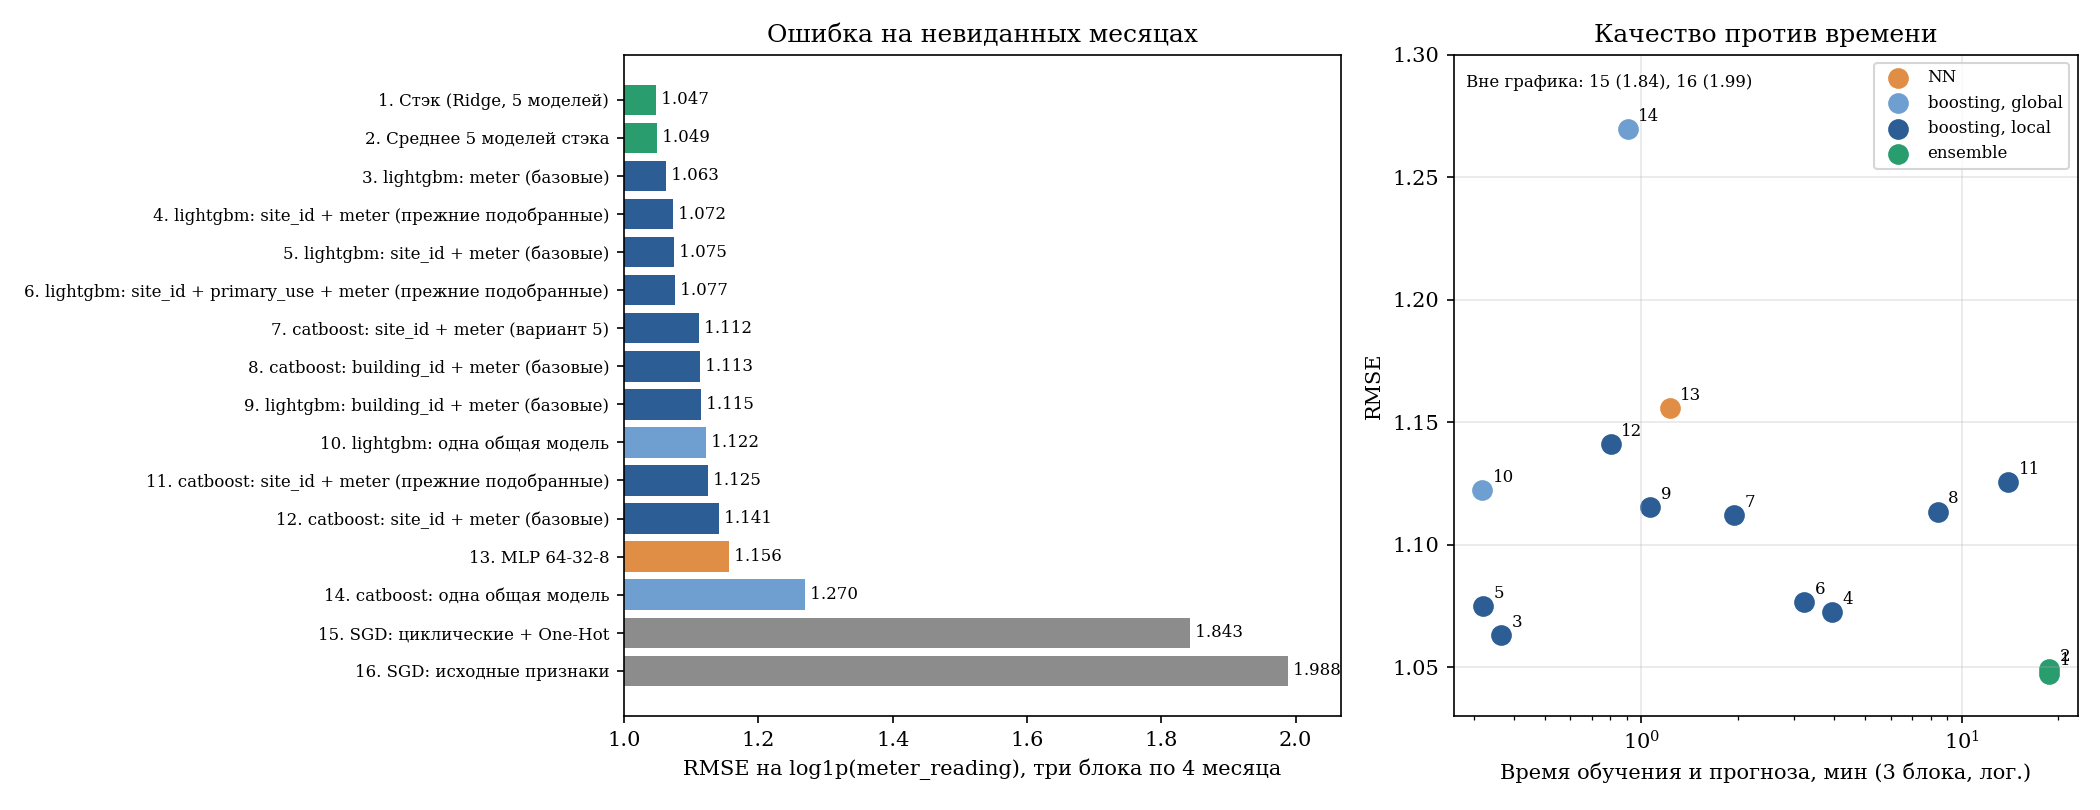

In [ ]:
import matplotlib.pyplot as plt

colors = {"linear": "#8c8c8c", "boosting, global": "#6f9fd0", "boosting, local": "#2c5d94", "NN": "#e08e45", "ensemble": "#2a9d6f"}
table = bench_table.sort_values("RMSE").reset_index(drop=True)
table["n"] = table.index + 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.15, 1]})

# Слева: ошибка по моделям, справа: ошибка и время (номера совпадают).
ordered = table.iloc[::-1]
axes[0].barh(
    [f"{n}. {name}" for n, name in zip(ordered["n"], ordered["model"])],
    ordered["RMSE"], color=[colors[f] for f in ordered["family"]],
)
axes[0].set_xlim(1.0, ordered["RMSE"].max() * 1.04)
axes[0].set_xlabel("RMSE на log1p(meter_reading), три блока по 4 месяца")
axes[0].set_title("Ошибка на невиданных месяцах")
axes[0].tick_params(axis="y", labelsize=8)
for y, value in enumerate(ordered["RMSE"]):
    axes[0].text(value, y, f" {value:.3f}", va="center", fontsize=8)

shown = table[table["RMSE"] < 1.35]
for family_name, part in shown.groupby("family"):
    axes[1].scatter(part["train_minutes"], part["RMSE"], s=80, color=colors[family_name], label=family_name)
for _, row in shown.iterrows():
    axes[1].annotate(str(row["n"]), (row["train_minutes"], row["RMSE"]),
                     fontsize=8, xytext=(5, 4), textcoords="offset points")
outside = table[table["RMSE"] >= 1.35]
axes[1].text(0.02, 0.97, "Вне графика: " + ", ".join(f"{n} ({v:.2f})" for n, v in zip(outside["n"], outside["RMSE"])),
             transform=axes[1].transAxes, va="top", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_ylim(1.03, 1.30)
axes[1].set_xlabel("Время обучения и прогноза, мин (3 блока, лог.)")
axes[1].set_ylabel("RMSE")
axes[1].set_title("Качество против времени")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].grid(alpha=0.3)
plt.tight_layout()
Path("results/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("results/figures/model_comparison.png", dpi=150)
plt.show()

In [ ]:
# Почему стэк лучше одиночных моделей: на каких счётчиках ошибаются и насколько
# ошибки моделей похожи. Строки те же, что в таблице выше (половина predict трёх блоков).
predict_meter = np.concatenate([
    cv_fold_frames(fold)["predict"]["meter"].to_numpy()
    for fold in range(len(CV_BLOCKS))
])
assert len(predict_meter) == len(bench_y["predict"])

error_predictions = {
    name: stack5_predictions[name]["predict"] for name in stack5_names
}
error_predictions["Среднее"] = mean_predict
error_predictions["Стэк"] = stack_predict

residuals = pd.DataFrame({
    name: prediction - bench_y["predict"]
    for name, prediction in error_predictions.items()
})

by_meter = pd.DataFrame({
    name: {
        f"meter {meter}": float(np.sqrt((residuals.loc[predict_meter == meter, name] ** 2).mean()))
        for meter in range(4)
    }
    for name in residuals
}).T
by_meter["доля строк"] = [None] * len(by_meter)
shares = pd.Series(predict_meter).value_counts(normalize=True).sort_index()
by_meter.loc["доля строк", [f"meter {m}" for m in range(4)]] = shares.to_numpy()
by_meter = by_meter.drop(columns="доля строк")

correlation = residuals.drop(columns=["Среднее", "Стэк"]).corr()
mean_correlation = float(
    correlation.to_numpy()[np.triu_indices(len(correlation), 1)].mean()
)

display(by_meter.round(3))
display(correlation.round(3))
print(f"Средняя корреляция ошибок моделей стэка: {mean_correlation:.3f}")

by_meter.to_csv("results/error_by_meter.csv")
correlation.to_csv("results/error_correlation.csv")

                                         meter 0  meter 1  meter 2  meter 3
lightgbm: site_id + meter                  0.686    1.400    1.448    1.660
catboost: site_id + meter                  0.695    1.471    1.525    1.684
lightgbm: site_id + primary_use + meter    0.686    1.392    1.474    1.677
catboost: building_id + meter              0.684    1.460    1.545    1.733
MLP                                        0.753    1.475    1.646    1.662
Среднее                                    0.674    1.359    1.441    1.599
Стэк                                       0.675    1.351    1.442    1.596
доля строк                                 0.590    0.210    0.135    0.064
                                         lightgbm: site_id + meter  catboost: site_id + meter  lightgbm: site_id + primary_use + meter  catboost: building_id + meter    MLP
lightgbm: site_id + meter                                    1.000                      0.917                                    0.972         

### Выводы: почему модели ведут себя по-разному

Числа ниже — из таблицы выше (RMSE на `log1p`, три невиданных блока по 4 месяца). Что проверено измерением, а что — объяснение, отмечено явно.

**1. Линейная модель против деревьев: 1.84–1.99 против 1.06–1.12.**
SGD видит зависимость от признаков только по прямой, а потребление — это произведение: площадь здания × (температура − уставка) × график работы по часам. Циклические признаки и One-Hot по `building_id` дали 1.99 → 1.84 (у каждого здания свой уровень), но остаток — взаимодействия, которые линейная модель выразить не может. Дерево получает их бесплатно. Время: 0.1 мин против 0.3–19 мин, но ошибка в 1.7 раза выше, так что линейная модель здесь не компромисс «быстро и чуть хуже», а заведомо слабый вариант.

**2. Общая модель против локальных: 1.122 → 1.063 → 1.075 → 1.115.**
Разделение по типу счётчика (`meter`) снижает ошибку на 0.06: электричество, холодная вода, пар и горячая вода по-разному зависят от погоды, и одна модель вынуждена усреднять. Дальше выигрыша нет: по `site_id + meter` 1.075, по зданиям 1.115. Измерено, что чем мельче группа, тем хуже; объяснение — на каждую модель приходится всё меньше строк (около 250 тыс. на счётчик, 26 тыс. на площадку+счётчик, 420 на здание) и меньше разных сезонов. Модель здания, обученная на восьми месяцах, на девятом месяце экстраполирует хуже, чем модель, которая видела много зданий с похожим поведением. На тесте (два следующих года) этот эффект должен быть сильнее, чем на проверке, — это предположение, не проверенное локально.

**3. LightGBM против CatBoost: 1.075 против 1.112 на площадках, 1.122 против 1.270 общая.**
CatBoost хуже при любой группировке и в 3–8 раз медленнее. Измерено два факта: большая модель CatBoost (600 итераций, глубина 10) хуже маленькой (400 итераций, глубина 4): 1.1255 против 1.1119 — то есть он переобучается, а не недообучается; общая CatBoost со 100 итерациями слабее LightGBM на 0.15 — на миллионе строк ей мало деревьев. Причины такой разницы — предположения: симметричные деревья менее гибки на числовых взаимодействиях (площадь × температура), порядковая целевая статистика по `building_id` на 400 строках шумит.

**4. Подбор гиперпараметров почти ничего не даёт: LightGBM 1.0750 → 1.0724 (в 13 раз дольше), CatBoost 1.141 → 1.112.**
Для LightGBM разница 0.003 меньше, чем разброс между блоками (1.05–1.09 у одной и той же модели). 25 минут подбора LightGBM и 36 минут CatBoost — самые дорогие вложения времени с самой маленькой отдачей. У CatBoost выигрыш заметнее, но он в основном достигается за счёт уменьшения модели.

**5. MLP слабее деревьев (1.156), но в стэке получает вес 0.25.**
Причина — ошибки MLP меньше похожи на ошибки деревьев: корреляция ошибок MLP с деревьями 0.77–0.84, а деревьев между собой — 0.87–0.97. Дерево даёт кусочно-постоянный ответ, сеть — гладкий; на сезонах, которых нет в обучении, они ошибаются по-разному.

**6. Стэк 1.047 против лучшей одиночной модели 1.063.**
Выигрыш 0.016 относительно лучшей одиночной модели и 0.025 относительно LightGBM по площадкам даёт не подбор весов, а усреднение разных моделей: простое среднее получает 1.049 против 1.047 у Ridge. Поэтому метамодель можно оставить простой, а ресурсы вложить в разнообразие ансамбля. Средняя корреляция ошибок моделей стэка 0.877, то есть они ошибаются похоже; добавлять в него стоит модели другого типа, а не ещё один бустинг на тех же признаках. Самая сильная одиночная модель (LightGBM по `meter`, 1.063) кандидатом стэка не была: тестовая схема обучает модели площадка за площадкой. Это первое, что стоит попробовать.

**7. Где ошибка.**
Электричество — 59% строк, но RMSE у него 0.68; холодная вода, пар и горячая вода — 41% строк с RMSE 1.35–1.66, то есть две трети суммарной квадратичной ошибки приходятся на тепловые счётчики. Они зависят от сезона и от режима отопления конкретного здания, которых за один год наблюдения видно мало.

**8. Почему 1.047 на проверке и 1.338 на Kaggle.**
Ошибка растёт вместе с горизонтом: следующий месяц — 1.003, невиданные 4 месяца — 1.047, public leaderboard — 1.125, private — 1.338. Обучающие данные — один год (2016), тест — два следующих. В нём есть сезоны и поведение зданий, которых модель не видела ни разу, а аномалии счётчиков, скорее всего, остаются в тестовых метках (предположение). Локальная проверка внутри 2016 года этого не воспроизводит, поэтому ей нельзя доверять в абсолютных значениях, только в сравнении моделей между собой.

**9. Что даёт и что не даёт признаки.**
На общей LightGBM: окна температуры и праздники почти ничего не добавили (±0.002), месяц — 0.008–0.035 на блоках, чистка нулей электричества и постоянных серий от недели — 0.015 (1.139 → 1.124). Прирост 1.428 → 1.338 на Kaggle дали сразу несколько изменений (сырая погода, час и день недели вместо одних произведений с площадью, чистка обучения, окно 72 часа, клиппинг); по отдельности они на Kaggle не мерились. Месяц, праздники и валидация блоками на Kaggle ещё не отправлялись.

**Что делать дальше.** Добавить в стэк общие модели по `meter` (самая сильная одиночная и самая дешёвая), убрать дорогой CatBoost глубины 10 и разнообразить ансамбль моделями другого типа; ошибку на тепловых счётчиках можно снизить, моделируя нагрузку на единицу площади.

## Результаты на Kaggle

Здесь результаты берутся с самого Kaggle, а не вводятся вручную:

1. **История отправок** — `kaggle competitions submissions` через CLI (нужны правила соревнования, принятые на Kaggle, и учётные данные в `~/.kaggle/`). Если CLI или доступа нет, используется сохранённый `results/kaggle_submissions.csv`.
2. **Private leaderboard** — постраничная выгрузка `kaggle competitions leaderboard --show`; сохранена в `results/ashrae-energy-prediction-privateleaderboard-2026-10-13.csv`.
3. **Положение отправок** — по итоговому private leaderboard (3592 команды): позиция и процентиль каждой отправки.

Порядок отправок и что в каждой:

| Отправка | Что внутри |
|---|---|
| 1 | Стэк из 5 моделей: бустинги по площадкам и зданиям + MLP (вес 0.54). 18 признаков, вес стэка подобран по одному августу |
| 2 | Тот же набор без LightGBM по зданиям: быстрее, результат тот же |
| 3 | Сырая погода, час и день недели, чистка нулей электричества и сбоя site 0, среднее температуры за 72 часа, прогноз ограничен максимумом train |
| 4 | Повторная загрузка файла 3: результат тот же |
| — | Итоговая версия с месяцем, праздниками, окнами температуры и валидацией блоками месяцев ещё не отправлена |

In [28]:
import io
import shutil
import subprocess
from pathlib import Path

KAGGLE_COMPETITION = "ashrae-energy-prediction"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

# Что внутри отправки (ref -> описание): Kaggle хранит только имя файла.
SUBMISSION_NOTES = {
    57122102: "1. Стэк 5 моделей + MLP (0.54), 18 признаков",
    57136288: "2. Стэк 4 модели, без LightGBM по зданиям",
    57141061: "3. Сырая погода, час, чистка, окно 72 ч, клиппинг",
    57147426: "4. Повторная отправка файла 3",
}


def kaggle_csv(*arguments):
    """Вывод kaggle CLI как DataFrame; None, если CLI недоступен или отказал."""
    executable = shutil.which("kaggle")

    if executable is None:
        return None

    result = subprocess.run(
        [executable, *arguments], capture_output=True, text=True,
    )

    if result.returncode != 0 or not result.stdout.strip():
        return None

    return pd.read_csv(io.StringIO(result.stdout))


kaggle_submissions = kaggle_csv(
    "competitions", "submissions", "-c", KAGGLE_COMPETITION, "--csv",
)

if kaggle_submissions is None:
    print("Kaggle CLI недоступен: берём сохранённый results/kaggle_submissions.csv")
    kaggle_submissions = pd.read_csv(RESULTS / "kaggle_submissions.csv")
else:
    kaggle_submissions.to_csv(RESULTS / "kaggle_submissions.csv", index=False)

kaggle_submissions["note"] = kaggle_submissions["ref"].map(SUBMISSION_NOTES)
kaggle_submissions = kaggle_submissions.sort_values("date").reset_index(drop=True)
display(kaggle_submissions[
    ["ref", "date", "fileName", "status", "publicScore", "privateScore", "note"]
])

Kaggle CLI недоступен: берём сохранённый results/kaggle_submissions.csv


,ref,date,fileName,status,publicScore,privateScore,note
0,57122102,2026-10-12 23:33:36.087000,submission.csv.gz,SubmissionStatus.COMPLETE,1.192,1.428,"1. Стэк 5 моделей + MLP (0.54), 18 признаков"
1,57136288,2026-10-13 08:13:11.943000,submission.csv.gz,SubmissionStatus.COMPLETE,1.190,1.427,"2. Стэк 4 модели, без LightGBM по зданиям"
2,57141061,2026-10-13 11:10:01.927000,submission_clipped.csv.gz,SubmissionStatus.COMPLETE,1.125,1.338,"3. Сырая погода, час, чистка, окно 72 ч, клиппинг"
3,57147426,2026-10-13 14:57:18.513000,submission_v2_clipped.csv.gz,SubmissionStatus.COMPLETE,1.125,1.338,4. Повторная отправка файла 3


In [31]:
import math

LEADERBOARD_FILE = RESULTS / "ashrae-energy-prediction-privateleaderboard-2026-10-13.csv"


def download_private_leaderboard(page_size=200):
    """Весь private leaderboard постранично; None, если CLI недоступен."""
    executable = shutil.which("kaggle")
    pages, token = [], None

    while executable:
        command = [
            executable, "competitions", "leaderboard", KAGGLE_COMPETITION,
            "--show", "--csv", "--page-size", str(page_size),
        ]
        if token:
            command += ["--page-token", token]

        result = subprocess.run(command, capture_output=True, text=True)

        if result.returncode != 0:
            return None

        lines = result.stdout.strip().splitlines()
        token = None

        if lines and lines[0].startswith("Next Page Token"):
            token = lines[0].split("=", 1)[1].strip()
            lines = lines[1:]

        page = pd.read_csv(io.StringIO("\n".join(lines)))
        pages.append(page)

        if not token or page.empty:
            break

    if not pages:
        return None

    board = pd.concat(pages, ignore_index=True)
    board.insert(0, "Rank", range(1, len(board) + 1))
    board.columns = ["Rank", "TeamId", "TeamName", "SubmissionDate", "Score"]
    return board


if LEADERBOARD_FILE.exists():
    leaderboard = pd.read_csv(LEADERBOARD_FILE)
else:
    leaderboard = download_private_leaderboard()
    leaderboard.to_csv(LEADERBOARD_FILE, index=False)

teams = len(leaderboard)
scores = leaderboard["Score"].to_numpy()          # по возрастанию: чем меньше, тем лучше

# Пороги процентилей: позиция и RMSLE на этой позиции.
thresholds = pd.DataFrame([
    {
        "Percentile": f"Top {share}%",
        "Rank": math.ceil(teams * share / 100),
        "Private Score": leaderboard.iloc[math.ceil(teams * share / 100) - 1]["Score"],
    }
    for share in (1, 5, 10, 20, 25, 50)
])
display(thresholds)


def leaderboard_position(score):
    """Позиция отправки: 1 + число команд строго лучше."""
    position = int((scores < score).sum()) + 1
    return position, position / teams * 100


submissions_scored = kaggle_submissions.dropna(subset=["privateScore"]).copy()
positions = [leaderboard_position(score) for score in submissions_scored["privateScore"]]
submissions_scored["position"] = [p for p, _ in positions]
submissions_scored["top_percent"] = [round(share, 1) for _, share in positions]
display(submissions_scored[
    ["note", "publicScore", "privateScore", "position", "top_percent"]
].reset_index(drop=True))

,Percentile,Rank,Private Score
0,Top 1%,36,1.247
1,Top 5%,180,1.268
2,Top 10%,360,1.280
3,Top 20%,719,1.295
4,Top 25%,898,1.296
5,Top 50%,1796,1.352


,note,publicScore,privateScore,position,top_percent
0,"1. Стэк 5 моделей + MLP (0.54), 18 признаков",1.192,1.428,2492,69.4
1,"2. Стэк 4 модели, без LightGBM по зданиям",1.190,1.427,2491,69.3
2,"3. Сырая погода, час, чистка, окно 72 ч, клиппинг",1.125,1.338,1748,48.7
3,4. Повторная отправка файла 3,1.125,1.338,1748,48.7


![Результат на Kaggle](results/Screenshot_result.png)